# **HOTEL BOOKING DATASET**

## **Dataset Understanding & Preprocessing**

### **Import Required Libraries**

In [1]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### **Load the Dataset**

In [2]:
# Load the Dataset
df = pd.read_csv("C:/Users/sahas/OneDrive/Desktop/DS/hotel_bookings.csv")

In [3]:
# Verify loading
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


### **Problem Statement**

Problem Statement:
The objective is to analyze hotel booking data and preprocess it to identify and correct data quality issues such as missing values, duplicate records, inconsistent data, incorrect data types, categorical variables, and outliers. The cleaned dataset will be prepared for further exploratory data analysis and machine learning to understand and predict hotel booking cancellations.

### **Dataset Description**

Dataset Description: The Hotel Booking Dataset contains information about bookings made at two types of hotels: Resort Hotel and City Hotel. It includes booking details, guest information, stay duration, customer characteristics, reservation information, and cancellation status. The dataset contains 119,390 records and 32 features.

### **Dataset Features and Data Types**

In [4]:
# Dataset Features and Data Types
df.columns
df.dtypes

hotel                              object
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                 object
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                               object
country                            object
market_segment                     object
distribution_channel               object
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                 object
assigned_room_type                 object
booking_changes                     int64
deposit_type                       object
agent                             

In [5]:
# Feature Information Table
feature_info = pd.DataFrame({
    "Feature": df.columns,
    "Data Type": df.dtypes.values,
    "Missing Values": df.isnull().sum().values,
    "Unique Values": df.nunique().values
})

feature_info

,Feature,Data Type,Missing Values,Unique Values
0,hotel,object,0,2
1,is_canceled,int64,0,2
2,lead_time,int64,0,479
3,arrival_date_year,int64,0,3
4,arrival_date_month,object,0,12
5,arrival_date_week_number,int64,0,53
6,arrival_date_day_of_month,int64,0,31
7,stays_in_weekend_nights,int64,0,17
8,stays_in_week_nights,int64,0,35
9,adults,int64,0,14


In [6]:
# Numerical and Categorical Features
numeric_cols = df.select_dtypes(include=np.number).columns
categorical_cols = df.select_dtypes(include="object").columns

print("Numerical Features:")
print(list(numeric_cols))

print("\nCategorical Features:")
print(list(categorical_cols))

Numerical Features:
['is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']

Categorical Features:
['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status', 'reservation_status_date']


### **Basic Dataset Inspection**

**First 5 Rows**

In [7]:
# Basic Dataset Inspection
# First 5 Rows
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


**Last 5 Rows**

In [8]:
# Last 5 Rows
df.tail()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07
119389,City Hotel,0,205,2017,August,35,29,2,7,2,...,No Deposit,9.0,NaN,0,Transient,151.20,0,2,Check-Out,2017-09-07


**Dataset Shape**

In [9]:
# Dataset Shape
df.shape

(119390, 32)

**Dataset Information**

In [10]:
# Dataset Information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

**Statistical Summary**

In [11]:
# Statistical Summary
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


**Statistical Summary Including Categorical Features**

In [12]:
# Statistical Summary Including Categorical Features
df.describe(include="all")

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
count,119390,119390.000000,119390.000000,119390.000000,119390,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,...,119390,103050.000000,6797.000000,119390.000000,119390,119390.000000,119390.000000,119390.000000,119390,119390
unique,2,NaN,NaN,NaN,12,NaN,NaN,NaN,NaN,NaN,...,3,NaN,NaN,NaN,4,NaN,NaN,NaN,3,926
top,City Hotel,NaN,NaN,NaN,August,NaN,NaN,NaN,NaN,NaN,...,No Deposit,NaN,NaN,NaN,Transient,NaN,NaN,NaN,Check-Out,2015-10-21
freq,79330,NaN,NaN,NaN,13877,NaN,NaN,NaN,NaN,NaN,...,104641,NaN,NaN,NaN,89613,NaN,NaN,NaN,75166,1461
mean,NaN,0.370416,104.011416,2016.156554,NaN,27.165173,15.798241,0.927599,2.500302,1.856403,...,NaN,86.693382,189.266735,2.321149,NaN,101.831122,0.062518,0.571363,NaN,NaN
std,NaN,0.482918,106.863097,0.707476,NaN,13.605138,8.780829,0.998613,1.908286,0.579261,...,NaN,110.774548,131.655015,17.594721,NaN,50.535790,0.245291,0.792798,NaN,NaN
min,NaN,0.000000,0.000000,2015.000000,NaN,1.000000,1.000000,0.000000,0.000000,0.000000,...,NaN,1.000000,6.000000,0.000000,NaN,-6.380000,0.000000,0.000000,NaN,NaN
25%,NaN,0.000000,18.000000,2016.000000,NaN,16.000000,8.000000,0.000000,1.000000,2.000000,...,NaN,9.000000,62.000000,0.000000,NaN,69.290000,0.000000,0.000000,NaN,NaN
50%,NaN,0.000000,69.000000,2016.000000,NaN,28.000000,16.000000,1.000000,2.000000,2.000000,...,NaN,14.000000,179.000000,0.000000,NaN,94.575000,0.000000,0.000000,NaN,NaN
75%,NaN,1.000000,160.000000,2017.000000,NaN,38.000000,23.000000,2.000000,3.000000,2.000000,...,NaN,229.000000,270.000000,0.000000,NaN,126.000000,0.000000,1.000000,NaN,NaN


### **Target Variable Identification**

Target variable: is_canceled

| Value | Meaning |
|---|---|
| 0 | Booking was not canceled |
| 1 | Booking was canceled |

**Target Variable Count**

In [13]:
# Target Variable Count
df["is_canceled"].value_counts()

is_canceled
0    75166
1    44224
Name: count, dtype: int64

**Target Variable Percentage**

In [14]:
# Target Variable Percentage
df["is_canceled"].value_counts(normalize=True) * 100

is_canceled
0    62.958372
1    37.041628
Name: proportion, dtype: float64

**Target Variable Visualization**

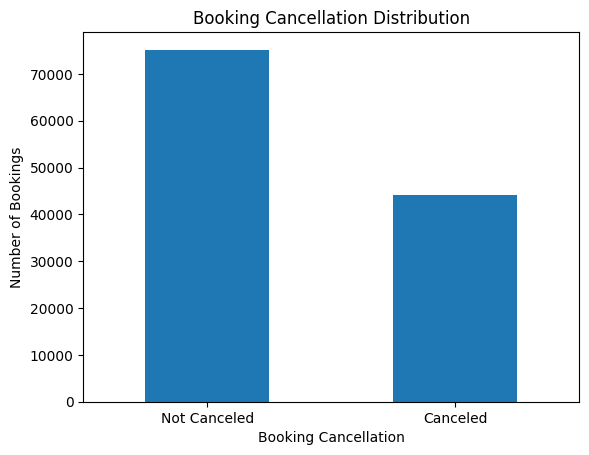

In [15]:
# Target Variable Visualization
df["is_canceled"].value_counts().plot(kind="bar")

plt.title("Booking Cancellation Distribution")
plt.xlabel("Booking Cancellation")
plt.ylabel("Number of Bookings")
plt.xticks([0, 1], ["Not Canceled", "Canceled"], rotation=0)
plt.show()

**Interpretation**

Interpretation: The target variable 'is_canceled' contains two classes: canceled and
non-canceled bookings. The value counts and percentage distribution
show the proportion of bookings belonging to each class.

### **Missing Value Analysis**

In [16]:
# Missing Value Analysis
df.isnull().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

**Missing Value Percentage**

In [17]:
# Missing Percentage
missing_count = df.isnull().sum()
missing_percentage = (missing_count / len(df)) * 100

missing_table = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percentage
})

missing_table[missing_table["Missing Count"] > 0]

,Missing Count,Missing Percentage
children,4,0.003350
country,488,0.408744
agent,16340,13.686238
company,112593,94.306893


**Missing Value Visualization**

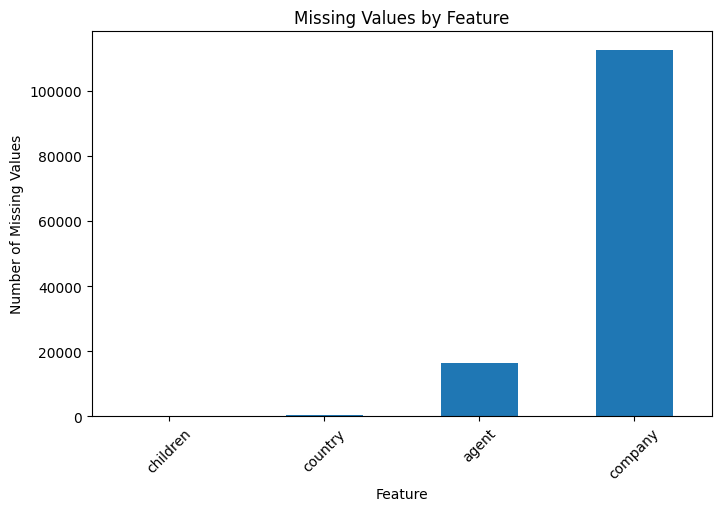

In [18]:
# Missing Values Visualization
missing_data = missing_table[missing_table["Missing Count"] > 0]

missing_data["Missing Count"].plot(kind="bar", figsize=(8, 5))

plt.title("Missing Values by Feature")
plt.xlabel("Feature")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.show()

**Interpretation**

Interpretation: Missing values are present in the 'children', 'country', 'agent', and
'company' columns. The missing values need to be handled appropriately
based on the meaning and data type of each feature.

### **Duplicate Value Analysis**

In [19]:
# Duplicate Value Analysis
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 31994


**View Duplicates**

In [20]:
# View Duplicates
df[df.duplicated()].head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
22,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,No Deposit,250.0,NaN,0,Transient,84.67,0,1,Check-Out,2015-07-07
43,Resort Hotel,0,70,2015,July,27,2,2,3,2,...,No Deposit,250.0,NaN,0,Transient,137.00,0,1,Check-Out,2015-07-07
138,Resort Hotel,1,5,2015,July,28,5,1,0,2,...,No Deposit,240.0,NaN,0,Transient,97.00,0,0,Canceled,2015-07-01
200,Resort Hotel,0,0,2015,July,28,7,0,1,1,...,No Deposit,240.0,NaN,0,Transient,109.80,0,3,Check-Out,2015-07-08


**Interpretation**

Interpretation: Duplicate records were identified in the dataset. These records can
cause repeated observations and may affect statistical analysis and
machine learning models.

### **Remove Duplicate Records**

In [21]:
# Removing Duplicate Records
rows_before_duplicates = df.shape[0]

df = df.drop_duplicates()

rows_after_duplicates = df.shape[0]

print("Rows before removing duplicates:", rows_before_duplicates)
print("Rows after removing duplicates:", rows_after_duplicates)
print("Duplicates remaining:", df.duplicated().sum())

Rows before removing duplicates: 119390
Rows after removing duplicates: 87396
Duplicates remaining: 0


**Interpretation**

Interpretation: Duplicate records were removed to ensure that each observation is
represented only once in the cleaned dataset.

### **Invalid and Inconsistent Data**

**Negative Values**

In [22]:
# Checking Invalid and Inconsistent Data
# Negative Values
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    negative_count = (df[col] < 0).sum()
    
    if negative_count > 0:
        print(col, ":", negative_count, "negative values")

adr : 1 negative values


**Check Guest Counts**

In [23]:
# Check Guest Counts
for col in ["adults", "children", "babies"]:
    print("\n", col)
    print(df[col].value_counts().sort_index())


 adults
adults
0       385
1     16503
2     64497
3      5935
4        60
5         2
6         1
10        1
20        2
26        5
27        2
40        1
50        1
55        1
Name: count, dtype: int64

 children
children
0.0     79028
1.0      4695
2.0      3593
3.0        75
10.0        1
Name: count, dtype: int64

 babies
babies
0     86482
1       897
2        15
9         1
10        1
Name: count, dtype: int64


**Check Bookings With Zero Guests**

In [24]:
# Check Bookings With Zero Guests
invalid_guests = df[
    (df["adults"] == 0) &
    (df["children"] == 0) &
    (df["babies"] == 0)
]

print("Bookings with zero guests:", len(invalid_guests))

Bookings with zero guests: 166


**Display Bookings With Zero Guests**

In [25]:
# Display Bookings With Zero Guets
invalid_guests.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
2224,Resort Hotel,0,1,2015,October,41,6,0,3,0,...,No Deposit,NaN,174.0,0,Transient-Party,0.0,0,0,Check-Out,2015-10-06
2409,Resort Hotel,0,0,2015,October,42,12,0,0,0,...,No Deposit,NaN,174.0,0,Transient,0.0,0,0,Check-Out,2015-10-12
3181,Resort Hotel,0,36,2015,November,47,20,1,2,0,...,No Deposit,38.0,NaN,0,Transient-Party,0.0,0,0,Check-Out,2015-11-23
3684,Resort Hotel,0,165,2015,December,53,30,1,4,0,...,No Deposit,308.0,NaN,122,Transient-Party,0.0,0,0,Check-Out,2016-01-04
3708,Resort Hotel,0,165,2015,December,53,30,2,4,0,...,No Deposit,308.0,NaN,122,Transient-Party,0.0,0,0,Check-Out,2016-01-05


**Remove Invalid Guest Records**

In [26]:
# Remove Invalid Guest Records
df = df[
    ~(
        (df["adults"] == 0) &
        (df["children"] == 0) &
        (df["babies"] == 0)
    )
]

**Check Categorical Values**

In [27]:
# Check Categorical Values
for col in categorical_cols:
    print("\n", col)
    print(df[col].unique())


 hotel
['Resort Hotel' 'City Hotel']

 arrival_date_month
['July' 'August' 'September' 'October' 'November' 'December' 'January'
 'February' 'March' 'April' 'May' 'June']

 meal
['BB' 'FB' 'HB' 'SC' 'Undefined']

 country
['PRT' 'GBR' 'USA' 'ESP' 'IRL' 'FRA' nan 'ROU' 'NOR' 'OMN' 'ARG' 'POL'
 'DEU' 'BEL' 'CHE' 'CN' 'GRC' 'ITA' 'NLD' 'DNK' 'RUS' 'SWE' 'AUS' 'EST'
 'CZE' 'BRA' 'FIN' 'MOZ' 'BWA' 'LUX' 'SVN' 'ALB' 'IND' 'CHN' 'MEX' 'MAR'
 'UKR' 'SMR' 'LVA' 'PRI' 'SRB' 'CHL' 'AUT' 'BLR' 'LTU' 'TUR' 'ZAF' 'AGO'
 'ISR' 'CYM' 'ZMB' 'CPV' 'ZWE' 'DZA' 'KOR' 'CRI' 'HUN' 'ARE' 'TUN' 'JAM'
 'HRV' 'HKG' 'IRN' 'GEO' 'AND' 'GIB' 'URY' 'JEY' 'CAF' 'CYP' 'COL' 'GGY'
 'KWT' 'NGA' 'MDV' 'VEN' 'SVK' 'FJI' 'KAZ' 'PAK' 'IDN' 'LBN' 'PHL' 'SEN'
 'SYC' 'AZE' 'BHR' 'NZL' 'THA' 'DOM' 'MKD' 'MYS' 'ARM' 'JPN' 'LKA' 'CUB'
 'CMR' 'BIH' 'MUS' 'COM' 'SUR' 'UGA' 'BGR' 'CIV' 'JOR' 'SYR' 'SGP' 'BDI'
 'SAU' 'VNM' 'PLW' 'QAT' 'EGY' 'PER' 'MLT' 'MWI' 'ECU' 'MDG' 'ISL' 'UZB'
 'NPL' 'BHS' 'MAC' 'TGO' 'TWN' 'DJI' 'STP' 'KNA' '

**Interpretation**

Interpretation: The dataset was checked for logically invalid values, negative values,
and inconsistent categorical values. Records containing zero adults,
children, and babies were considered invalid because they represent
bookings with no guests and were removed.

### **Handling Missing Values**

**Children**

In [28]:
# Handling Missing Values
# Children
df["children"] = df["children"].fillna(0)

**Country**

In [29]:
# Country
df["country"] = df["country"].fillna("Unknown")

**Agent**

In [30]:
# Agent
df["agent"] = df["agent"].fillna(0)

**Company**

In [31]:
# Company
df["company"] = df["company"].fillna(0)

**Verification**

In [32]:
# Verification
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


**Interpretation**

Interpretation: Missing values in 'children' were replaced with 0 because the feature
represents the number of children. Missing 'country' values were
replaced with "Unknown" because it is a categorical feature. Missing
values in 'agent' and 'company' were replaced with 0 to indicate the
absence of available agent or company information.

### **Dataset Type Conversion**

**Before Coversion**

In [33]:
# Data Type Conversion
# Before Conversion
df.dtypes

hotel                              object
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                 object
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                               object
country                            object
market_segment                     object
distribution_channel               object
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                 object
assigned_room_type                 object
booking_changes                     int64
deposit_type                       object
agent                             

**Convert Numeric Fields**

In [34]:
# Convert Numeric Fields
df["children"] = df["children"].astype(int)
df["agent"] = df["agent"].astype(int)
df["company"] = df["company"].astype(int)

**Convert Reservation Date**

In [35]:
# Convert Reservation Date
df["reservation_status_date"] = pd.to_datetime(
    df["reservation_status_date"]
)

**Create Arrival Date**

In [36]:
# Create Arrival Date
df["arrival_date"] = pd.to_datetime(
    df["arrival_date_year"].astype(str) + "-" +
    df["arrival_date_month"] + "-" +
    df["arrival_date_day_of_month"].astype(str),
    errors="coerce"
)

**Verify**

In [37]:
# Verify
df[[
    "children",
    "agent",
    "company",
    "reservation_status_date",
    "arrival_date"
]].dtypes

children                            int64
agent                               int64
company                             int64
reservation_status_date    datetime64[ns]
arrival_date               datetime64[ns]
dtype: object

**Interpretation**

Interpretation: Appropriate data type conversions were performed. Numeric count and ID
fields were converted to integer types, while date-related fields were
converted to datetime format for easier analysis.

### **Outlier Detection**

**Selecting Relevant Numerical Features**

In [38]:
# Outlier Detection
# Selecting Relevant Numerical Features
outlier_cols = [
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "booking_changes",
    "days_in_waiting_list",
    "adr",
    "required_car_parking_spaces",
    "total_of_special_requests"
]

**Boxplots**

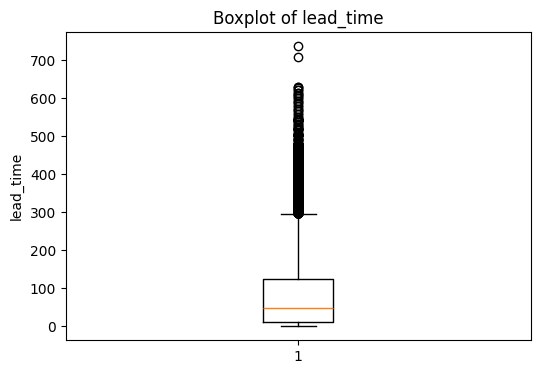

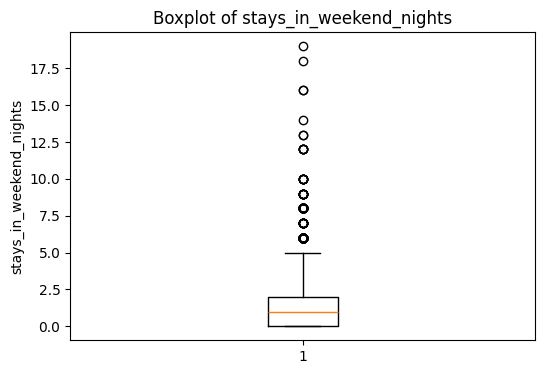

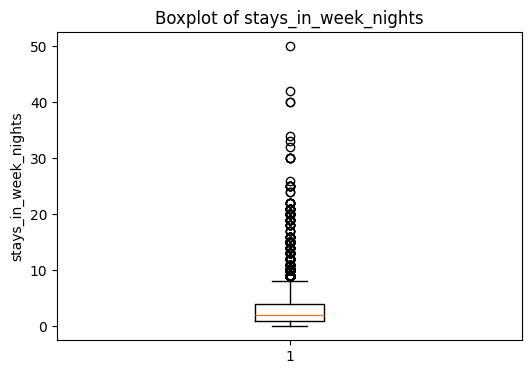

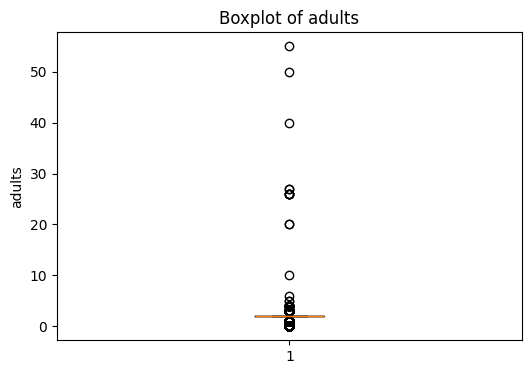

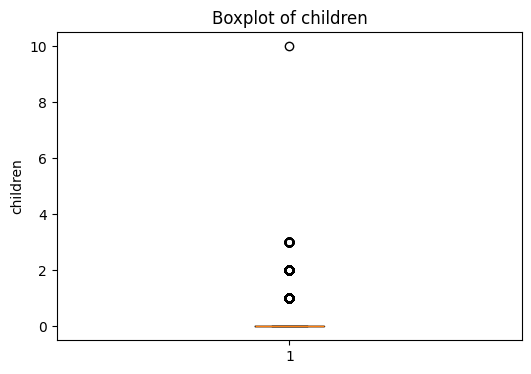

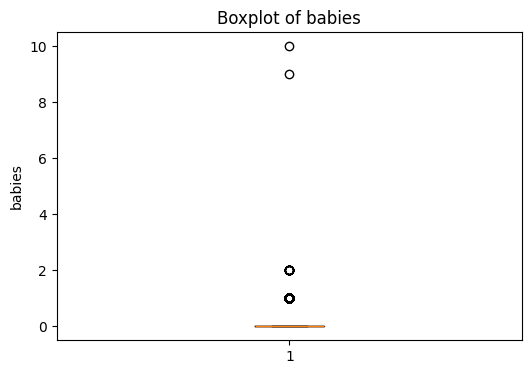

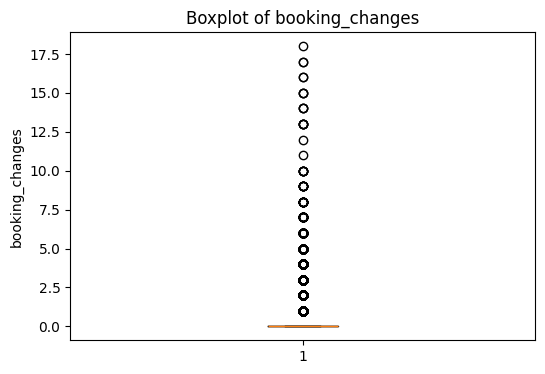

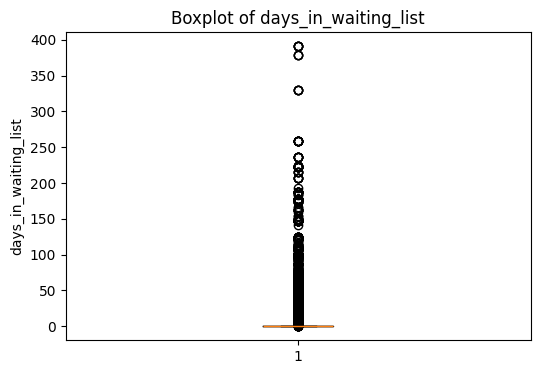

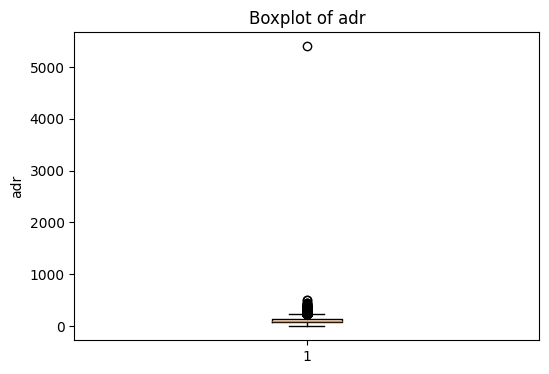

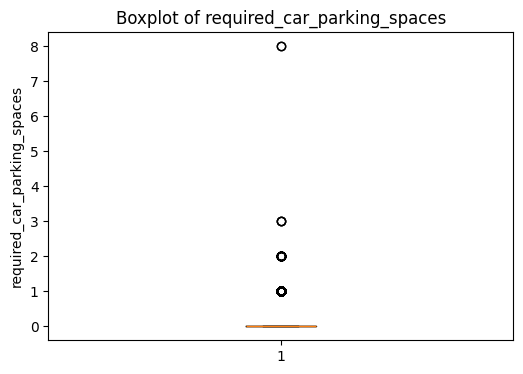

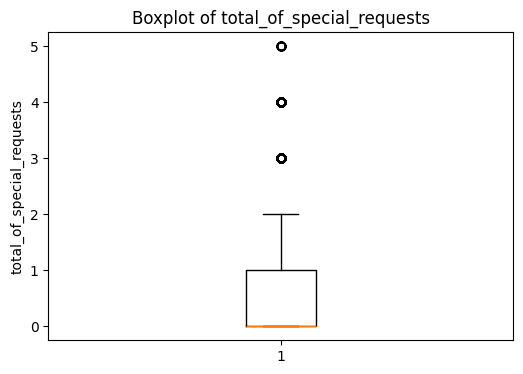

In [39]:
# Boxplots
for col in outlier_cols:
    plt.figure(figsize=(6, 4))
    plt.boxplot(df[col].dropna())
    plt.title(f"Boxplot of {col}")
    plt.ylabel(col)
    plt.show()

### **IQR Outlier Analysis**

**IQR-Based Outlier Detection**

In [40]:
# IQR Outlier Analysis
# IQR-Based Outlier Detection
outlier_results = []

for col in outlier_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    
    outlier_results.append([
        col, Q1, Q3, IQR, lower, upper, count
    ])

outlier_table = pd.DataFrame(
    outlier_results,
    columns=[
        "Feature",
        "Q1",
        "Q3",
        "IQR",
        "Lower Bound",
        "Upper Bound",
        "Outlier Count"
    ]
)

outlier_table

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
0,lead_time,11.00,125.0,114.00,-160.000,296.000,2394
1,stays_in_weekend_nights,0.00,2.0,2.00,-3.000,5.000,213
2,stays_in_week_nights,1.00,4.0,3.00,-3.500,8.500,1514
3,adults,2.00,2.0,0.00,2.000,2.000,22733
4,children,0.00,0.0,0.00,0.000,0.000,8364
5,babies,0.00,0.0,0.00,0.000,0.000,914
6,booking_changes,0.00,0.0,0.00,0.000,0.000,15805
7,days_in_waiting_list,0.00,0.0,0.00,0.000,0.000,855
8,adr,72.25,134.1,61.85,-20.525,226.875,2508
9,required_car_parking_spaces,0.00,0.0,0.00,0.000,0.000,7306


**Outlier Handling Using IQR Capping**

In [41]:
# Outlier Handling Using IQR Capping
def cap_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    data[column] = data[column].clip(lower, upper)
    
    return data

In [42]:
cap_cols = [
    "lead_time",
    "adr",
    "days_in_waiting_list"
]

for col in cap_cols:
    df = cap_outliers(df, col)

In [43]:
for col in cap_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = ((df[col] < lower) | (df[col] > upper)).sum()

    print(col, "→ Remaining outliers:", outliers)

lead_time → Remaining outliers: 0
adr → Remaining outliers: 0
days_in_waiting_list → Remaining outliers: 0


**Interpretation**

Outliers were detected using the Interquartile Range (IQR) method.
Instead of removing all extreme observations, selected continuous
features were capped at their IQR-based lower and upper limits to
reduce the influence of extreme values while retaining the records.

### **Categorical Encoding**

**Identify Categorical Columns Again**

In [44]:
# Encoding Categorical Variables
# Identify Categorical Columns Again
categorical_cols = df.select_dtypes(include="object").columns

print("Categorical columns:")
print(list(categorical_cols))

Categorical columns:
['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status']


**One-hot Encoding**

In [45]:
# One-hot Encoding
df_encoded = pd.get_dummies(
    df,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

**Check**

In [46]:
df_encoded.head()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,...,assigned_room_type_I,assigned_room_type_K,assigned_room_type_L,deposit_type_Non Refund,deposit_type_Refundable,customer_type_Group,customer_type_Transient,customer_type_Transient-Party,reservation_status_Check-Out,reservation_status_No-Show
0,0,296,2015,27,1,0,0,2,0,0,...,0,0,0,0,0,0,1,0,1,0
1,0,296,2015,27,1,0,0,2,0,0,...,0,0,0,0,0,0,1,0,1,0
2,0,7,2015,27,1,0,1,1,0,0,...,0,0,0,0,0,0,1,0,1,0
3,0,13,2015,27,1,0,1,1,0,0,...,0,0,0,0,0,0,1,0,1,0
4,0,14,2015,27,1,0,2,2,0,0,...,0,0,0,0,0,0,1,0,1,0


In [47]:
df_encoded.shape

(87230, 251)

**Interpretation**

Interpretation: Categorical variables were converted into numerical representations
using one-hot encoding. The 'drop_first=True' option was used to avoid
redundant dummy variables.

### **Feature scaling**

**Using StandardScaler**

In [48]:
# Feature Scaling
# Using StandardScaler
from sklearn.preprocessing import StandardScaler

scale_cols = [
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "booking_changes",
    "days_in_waiting_list",
    "adr",
    "required_car_parking_spaces",
    "total_of_special_requests"
]

In [49]:
scaler = StandardScaler()

df_encoded[scale_cols] = scaler.fit_transform(df_encoded[scale_cols])

**Check**

In [50]:
# Check
df_encoded[scale_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
lead_time,87230.0,9.514088e-17,1.000006,-0.967805,-0.832090,-0.363257,0.574410,2.684159
stays_in_weekend_nights,87230.0,5.213199e-17,1.000006,-0.977814,-0.977814,-0.004486,0.968843,17.515424
stays_in_week_nights,87230.0,0.000000e+00,1.000006,-1.286352,-0.796113,-0.305873,0.674606,23.225629
adults,87230.0,1.283750e-16,1.000006,-3.022846,0.194034,0.194034,0.194034,85.441359
children,87230.0,1.303300e-18,1.000006,-0.304424,-0.304424,-0.304424,-0.304424,21.612798
babies,87230.0,-1.042640e-17,1.000006,-0.095379,-0.095379,-0.095379,-0.095379,87.853094
booking_changes,87230.0,-1.042640e-17,1.000006,-0.377830,-0.377830,-0.377830,-0.377830,24.951859
days_in_waiting_list,87230.0,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
adr,87230.0,4.170559e-17,1.000006,-2.282005,-0.678481,-0.149275,0.582844,2.474832
required_car_parking_spaces,87230.0,0.000000e+00,1.000006,-0.299321,-0.299321,-0.299321,-0.299321,28.104019


**Interpretation**

Interpretation: Standardization was applied to selected numerical features so that
they have approximately zero mean and unit standard deviation. This
is particularly useful for distance-based and gradient-based machine
learning algorithms.

### **Final Cleaned Dataset**

**Shape**

In [51]:
# Final Cleaned Dataset
# Shape
print("Final dataset shape:", df_encoded.shape)

Final dataset shape: (87230, 251)


**Missing Values**

In [52]:
# Missing Values
print(
    "Total missing values:",
    df_encoded.isnull().sum().sum()
)

Total missing values: 0


**Duplicates**

In [53]:
# Duplicates
print(
    "Total duplicate rows:",
    df_encoded.duplicated().sum()
)

Total duplicate rows: 24


**Data Types**

In [54]:
# Data Types
df_encoded.dtypes

is_canceled                        int64
lead_time                        float64
arrival_date_year                  int64
arrival_date_week_number           int64
arrival_date_day_of_month          int64
                                  ...   
customer_type_Group                int64
customer_type_Transient            int64
customer_type_Transient-Party      int64
reservation_status_Check-Out       int64
reservation_status_No-Show         int64
Length: 251, dtype: object

**First Rows**

In [55]:
# First Rows
df_encoded.head()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,...,assigned_room_type_I,assigned_room_type_K,assigned_room_type_L,deposit_type_Non Refund,deposit_type_Refundable,customer_type_Group,customer_type_Transient,customer_type_Transient-Party,reservation_status_Check-Out,reservation_status_No-Show
0,0,2.684159,2015,27,1,-0.977814,-1.286352,0.194034,-0.304424,-0.095379,...,0,0,0,0,0,0,1,0,1,0
1,0,2.684159,2015,27,1,-0.977814,-1.286352,0.194034,-0.304424,-0.095379,...,0,0,0,0,0,0,1,0,1,0
2,0,-0.881441,2015,27,1,-0.977814,-0.796113,-1.414406,-0.304424,-0.095379,...,0,0,0,0,0,0,1,0,1,0
3,0,-0.807415,2015,27,1,-0.977814,-0.796113,-1.414406,-0.304424,-0.095379,...,0,0,0,0,0,0,1,0,1,0
4,0,-0.795077,2015,27,1,-0.977814,-0.305873,0.194034,-0.304424,-0.095379,...,0,0,0,0,0,0,1,0,1,0


### **Save Final Dataset**

In [56]:
# Saving The Cleaned Dataset
df_encoded.to_csv(
    "hotel_booking_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


### **Before and After Summary**

In [57]:
# Before and After Preprocessing
print("BEFORE PREPROCESSING")
print("--------------------")
print("Rows: 119390")
print("Columns: 32")
print("Duplicate Rows: 31994")

print("\nAFTER PREPROCESSING")
print("-------------------")
print("Rows:", df_encoded.shape[0])
print("Columns:", df_encoded.shape[1])
print("Duplicate Rows:", df_encoded.duplicated().sum())
print("Missing Values:", df_encoded.isnull().sum().sum())

BEFORE PREPROCESSING
--------------------
Rows: 119390
Columns: 32
Duplicate Rows: 31994

AFTER PREPROCESSING
-------------------
Rows: 87230
Columns: 251
Duplicate Rows: 24
Missing Values: 0


### **Overall Preprocessing Interpretation**

Overall Processing Interpretation: The Hotel Booking Dataset initially contained 119,390 records and 32
features. The dataset was systematically examined for missing values,
duplicate records, invalid values, inconsistent data, incorrect data
types, categorical variables, and outliers.

Missing values were handled according to the meaning of each feature,
and duplicate records were removed. Invalid records containing zero
adults, children, and babies were identified and removed. Appropriate
data type conversions were performed, including conversion of date
fields to datetime format.

Categorical variables were converted into numerical representations
using one-hot encoding. Outliers in selected continuous variables were
detected using the IQR method and handled using capping. Numerical
features were standardized using StandardScaler where appropriate.

The final dataset is cleaner, more consistent, and suitable for
further exploratory data analysis and machine learning.

## **Exploratory Data Analysis**

Exploratory Data Analysis (EDA) is performed to understand the main characteristics, distributions, relationships, and patterns present in the hotel booking dataset. Different statistical measures and visualizations are used to analyze booking behavior, customer characteristics, stay patterns, pricing, and cancellation trends.

### **Descriptive Statistics**

Descriptive statistics are used to summarize the main characteristics of the numerical features in the hotel booking dataset. Measures such as count, mean, standard deviation, minimum, maximum, and quartiles help in understanding the distribution and variation of booking-related variables.

In [58]:
# Descriptive Statistics of Important Numerical Features

important_numeric_cols = [
    'lead_time',
    'stays_in_weekend_nights',
    'stays_in_week_nights',
    'adults',
    'children',
    'babies',
    'adr',
    'days_in_waiting_list',
    'total_of_special_requests'
]

df[important_numeric_cols].describe()

,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,adr,days_in_waiting_list,total_of_special_requests
count,87230.000000,87230.000000,87230.000000,87230.000000,87230.000000,87230.000000,87230.000000,87230.0,87230.000000
mean,78.442795,1.004609,2.623925,1.879365,0.138897,0.010845,105.519806,0.0,0.698934
std,81.052731,1.027408,2.039830,0.621724,0.456265,0.113704,49.036021,0.0,0.832051
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-6.380000,0.0,0.000000
25%,11.000000,0.000000,1.000000,2.000000,0.000000,0.000000,72.250000,0.0,0.000000
50%,49.000000,1.000000,2.000000,2.000000,0.000000,0.000000,98.200000,0.0,0.000000
75%,125.000000,2.000000,4.000000,2.000000,0.000000,0.000000,134.100000,0.0,1.000000
max,296.000000,19.000000,50.000000,55.000000,10.000000,10.000000,226.875000,0.0,5.000000


**Interpretation:** The descriptive statistics provide an overview of the typical values and variation in important booking features such as lead time, length of stay, number of guests, ADR, and special requests.

### **Histogram of Lead Time**

A histogram is used to visualize the distribution of lead time, which represents the number of days between the booking date and the arrival date. This helps identify the most common booking periods and the spread of booking lead times.

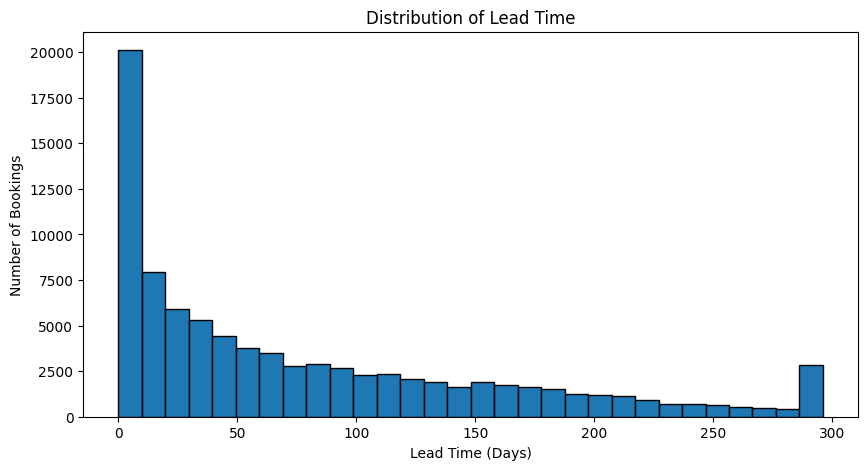

In [59]:
# Histogram of Lead Time

plt.figure(figsize=(10, 5))

plt.hist(df['lead_time'], bins=30, edgecolor='black')

plt.title('Distribution of Lead Time')
plt.xlabel('Lead Time (Days)')
plt.ylabel('Number of Bookings')

plt.show()

**Interpretation:** The histogram shows how hotel bookings are distributed according to the number of days between booking and arrival. A concentration of bookings at lower lead times indicates that many customers make reservations relatively close to their arrival date, while the longer tail represents bookings made much earlier.

### **Histogram of Average Daily Rate (ADR)**

The distribution of Average Daily Rate (ADR) is analyzed using a histogram to understand the typical daily price paid for hotel rooms and to identify the spread and possible extreme values in room rates.

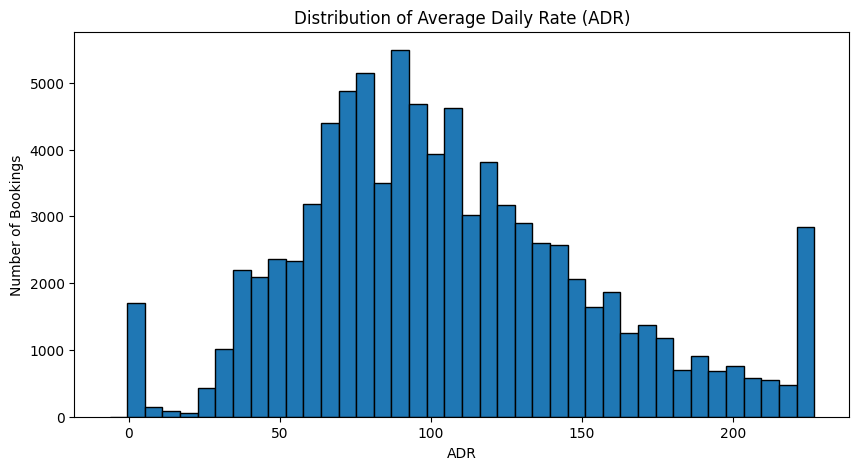

In [60]:
# Histogram of ADR

plt.figure(figsize=(10, 5))

plt.hist(df['adr'], bins=40, edgecolor='black')

plt.title('Distribution of Average Daily Rate (ADR)')
plt.xlabel('ADR')
plt.ylabel('Number of Bookings')

plt.show()

**Interpretation:** The histogram shows the distribution of daily room rates. Most bookings are concentrated within a particular ADR range, while observations at very high values indicate relatively expensive bookings.

### **Bar Plot of Hotel Type**

A bar plot is used to compare the total number of bookings between the two hotel types. This helps determine whether City Hotel or Resort Hotel receives more bookings in the dataset.

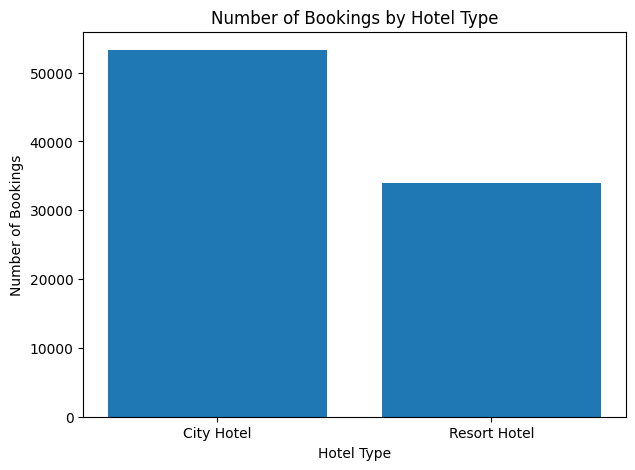

In [61]:
# Bar Plot of Hotel Type

hotel_counts = df['hotel'].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(hotel_counts.index, hotel_counts.values)

plt.title('Number of Bookings by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('Number of Bookings')

plt.show()

**Interpretation:** The bar plot compares the booking volumes of City Hotel and Resort Hotel. The hotel with the taller bar has a higher number of bookings in the dataset.

### **Count Plot of Booking Cancellation**

A count plot is used to compare the number of canceled and non-canceled bookings. This provides a clear view of the distribution of the target variable `is_canceled`.

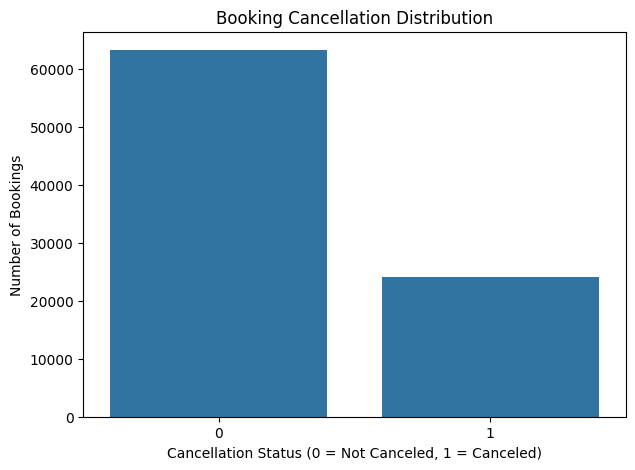

In [62]:
# Count Plot of Cancellation Status

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='is_canceled')

plt.title('Booking Cancellation Distribution')
plt.xlabel('Cancellation Status (0 = Not Canceled, 1 = Canceled)')
plt.ylabel('Number of Bookings')

plt.show()

### **Count Plot of Market Segment**

The market segment represents the source or category through which a booking was made. A count plot is used to identify the market segments contributing the largest number of hotel bookings.

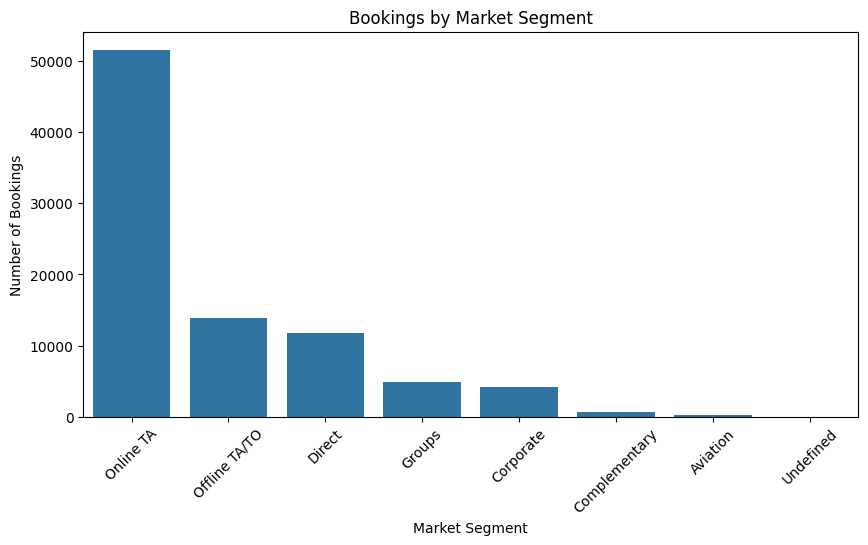

In [63]:
# Count Plot of Market Segment

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='market_segment',
    order=df['market_segment'].value_counts().index
)

plt.title('Bookings by Market Segment')
plt.xlabel('Market Segment')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=45)

plt.show()

**Interpretation:** The plot shows the contribution of different market segments to hotel bookings. Segments with taller bars represent the major sources of bookings.

### **Box Plot of Lead Time**

A box plot is used to examine the distribution of lead time and identify its median, spread, and potential extreme values. This helps understand how much variation exists in advance booking periods.

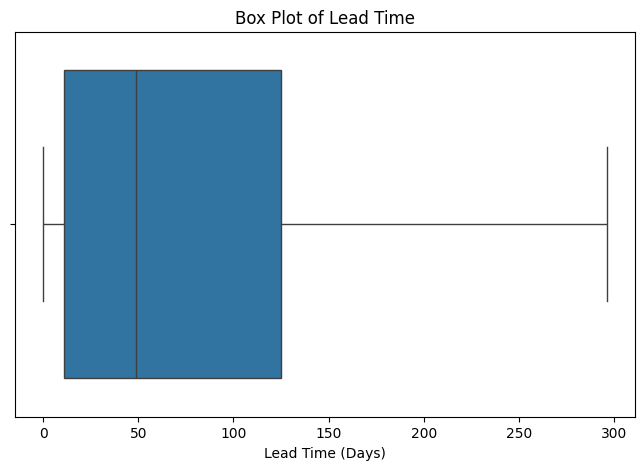

In [64]:
# Box Plot of Lead Time

plt.figure(figsize=(8, 5))

sns.boxplot(x=df['lead_time'])

plt.title('Box Plot of Lead Time')
plt.xlabel('Lead Time (Days)')

plt.show()

**Interpretation:** The box plot shows the central distribution and variability of lead time. Points beyond the whiskers represent unusually high or low lead-time values, indicating bookings made significantly earlier or later than most bookings.

### **Box Plot of ADR by Hotel Type**

The ADR distribution is compared between City Hotel and Resort Hotel using a box plot. This helps identify differences in room pricing, median ADR, variability, and potential extreme values between the two hotel types.

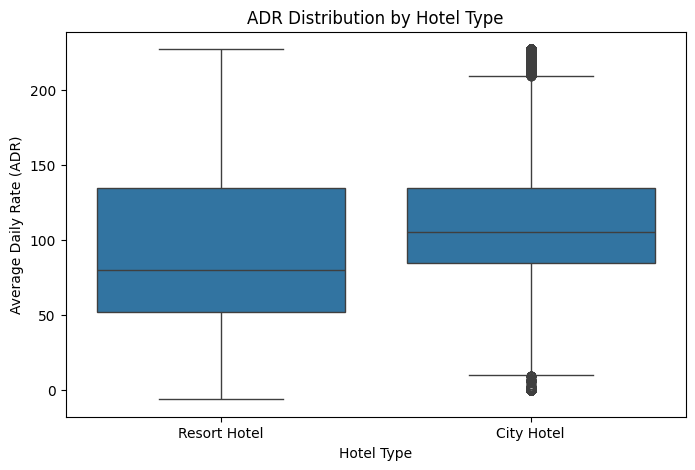

In [65]:
# Box Plot of ADR by Hotel Type

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='hotel', y='adr')

plt.title('ADR Distribution by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('Average Daily Rate (ADR)')

plt.show()

### **Scatter Plot of Lead Time and ADR**

A scatter plot is used to analyze the relationship between lead time and Average Daily Rate (ADR). This helps determine whether booking in advance is associated with differences in room prices.

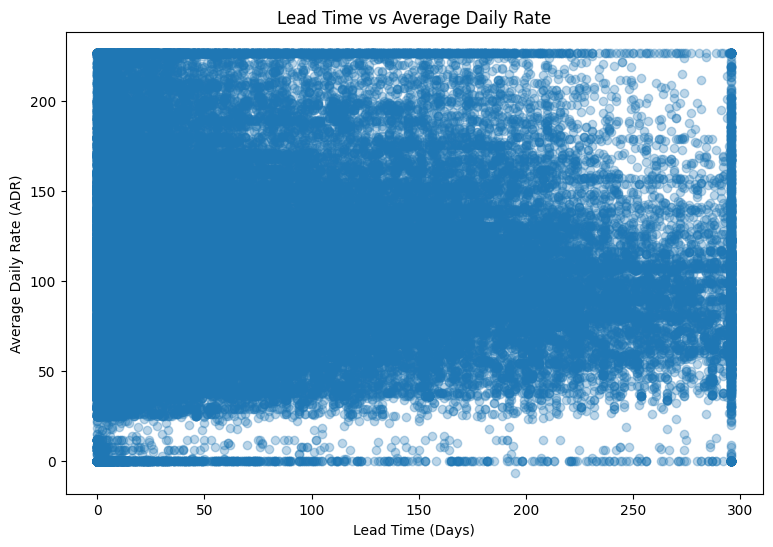

In [66]:
# Scatter Plot: Lead Time vs ADR

plt.figure(figsize=(9, 6))

plt.scatter(
    df['lead_time'],
    df['adr'],
    alpha=0.3
)

plt.title('Lead Time vs Average Daily Rate')
plt.xlabel('Lead Time (Days)')
plt.ylabel('Average Daily Rate (ADR)')

plt.show()

**Interpretation:** The scatter plot shows the relationship between advance booking time and room price. A strong upward or downward pattern would indicate a relationship between the two variables, while a widely scattered pattern would indicate a weak relationship.

In [67]:
# Calculate Total Stay Duration

df['total_stay_nights'] = (
    df['stays_in_weekend_nights'] +
    df['stays_in_week_nights']
)

df[['stays_in_weekend_nights',
   'stays_in_week_nights',
   'total_stay_nights']].head()

,stays_in_weekend_nights,stays_in_week_nights,total_stay_nights
0,0,0,0
1,0,0,0
2,0,1,1
3,0,1,1
4,0,2,2


### **Scatter Plot of Total Stay Duration and ADR**

The relationship between total stay duration and Average Daily Rate is analyzed using a scatter plot. Total stay duration is calculated by combining weekend nights and week nights.

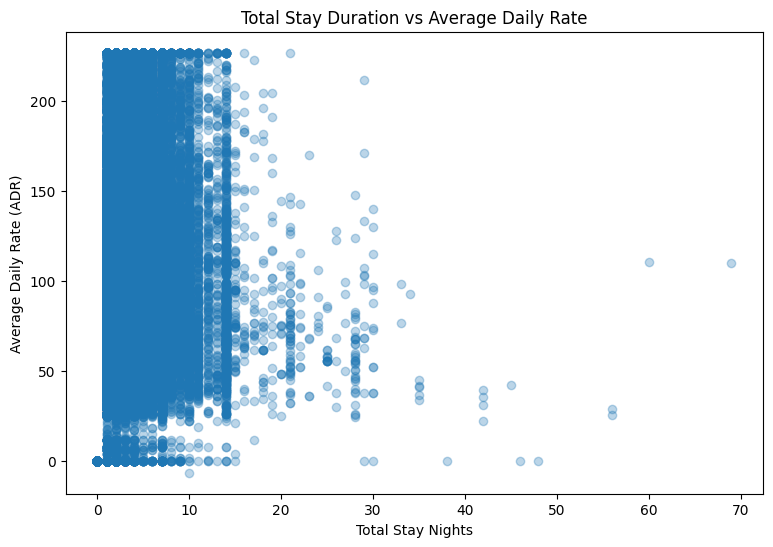

In [68]:
# Scatter Plot: Total Stay vs ADR

plt.figure(figsize=(9, 6))

plt.scatter(
    df['total_stay_nights'],
    df['adr'],
    alpha=0.3
)

plt.title('Total Stay Duration vs Average Daily Rate')
plt.xlabel('Total Stay Nights')
plt.ylabel('Average Daily Rate (ADR)')

plt.show()

**Interpretation:** The scatter plot helps identify whether longer or shorter stays are associated with different daily room rates. The distribution of points indicates the strength and direction of the relationship between stay duration and ADR.

### **Correlation Heatmap**

A correlation heatmap is used to analyze relationships between numerical features in the hotel booking dataset. Correlation values indicate the strength and direction of linear relationships between pairs of numerical variables.

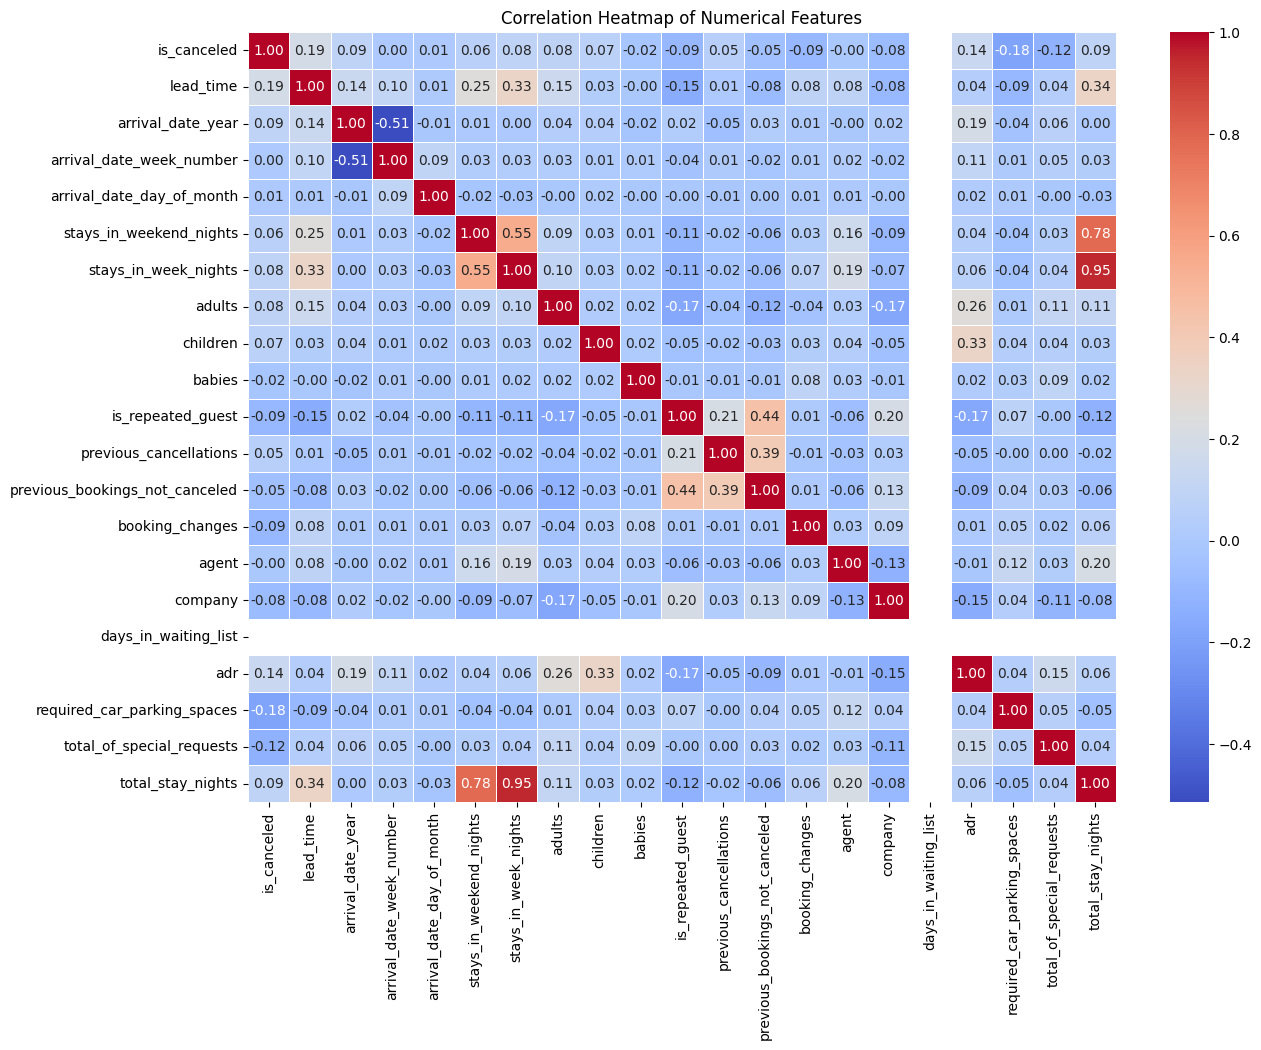

In [69]:
# Correlation Heatmap

correlation_matrix = df.select_dtypes(include=np.number).corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Numerical Features')

plt.show()

**Interpretation:** The heatmap highlights the strength of relationships between numerical features. Features with values closer to +1 or -1 have stronger positive or negative linear relationships, while values close to 0 indicate weak linear relationships.

### **Monthly Booking Distribution**

The number of bookings across different arrival months is analyzed to identify seasonal patterns in hotel demand. This helps determine which months experience relatively higher or lower booking activity.

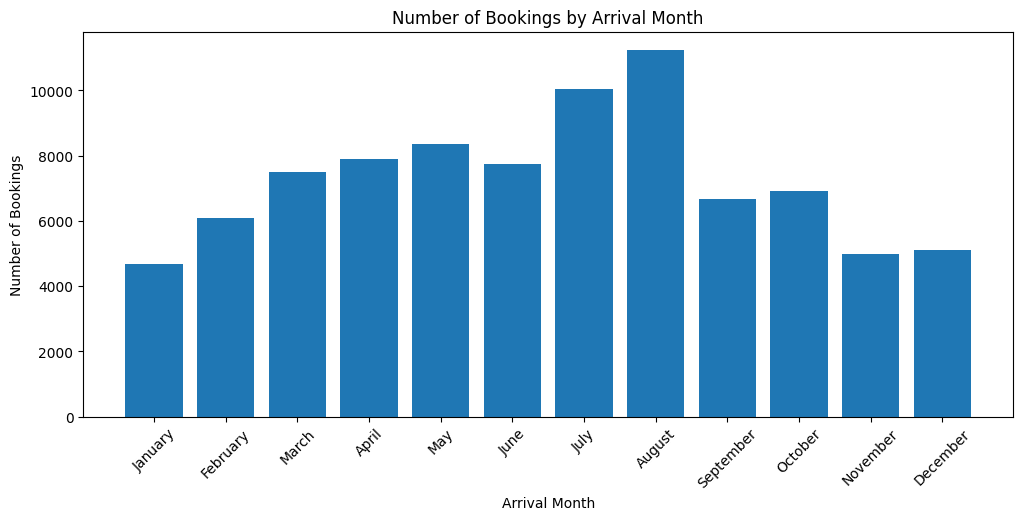

In [70]:
# Monthly Booking Distribution

month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_bookings = (
    df['arrival_date_month']
    .value_counts()
    .reindex(month_order)
)

plt.figure(figsize=(12, 5))

plt.bar(monthly_bookings.index, monthly_bookings.values)

plt.title('Number of Bookings by Arrival Month')
plt.xlabel('Arrival Month')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=45)

plt.show()

**Interpretation:** The visualization shows seasonal variation in hotel bookings. Months with higher bars indicate periods of greater booking activity, while lower bars indicate relatively lower demand.

### **Cancellation Rate by Hotel Type**

The cancellation rate is calculated separately for City Hotel and Resort Hotel to compare the likelihood of bookings being canceled across the two hotel types.

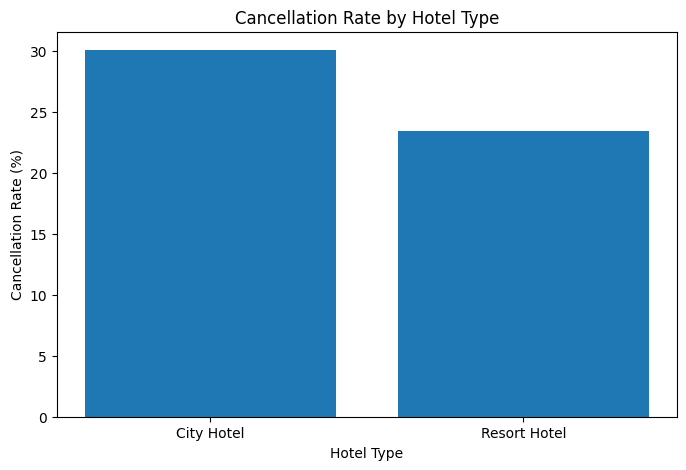

In [71]:
# Cancellation Rate by Hotel

cancellation_rate = (
    df.groupby('hotel')['is_canceled']
    .mean()
    .sort_values(ascending=False)
)

cancellation_rate_percentage = cancellation_rate * 100

plt.figure(figsize=(8, 5))

plt.bar(
    cancellation_rate_percentage.index,
    cancellation_rate_percentage.values
)

plt.title('Cancellation Rate by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('Cancellation Rate (%)')

plt.show()

**Interpretation:** The cancellation rate comparison shows which hotel type has a higher proportion of canceled bookings. A higher cancellation rate indicates greater cancellation risk for that hotel type.

### **Previous Cancellations and Current Cancellation**

The relationship between previous cancellations and the current booking cancellation status is analyzed to determine whether customers with a history of cancellations are more likely to cancel their current bookings.

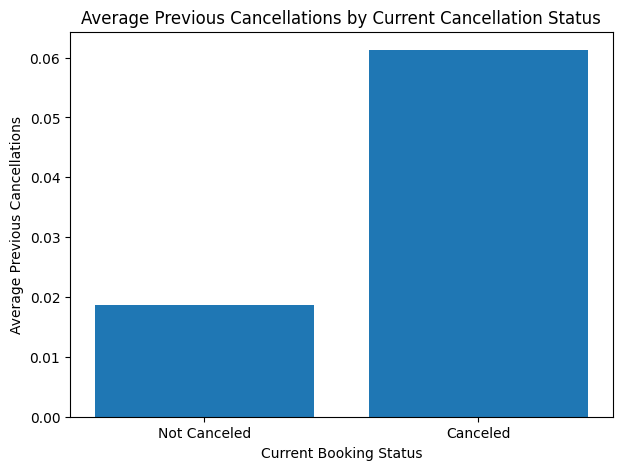

In [72]:
# Previous Cancellations vs Current Cancellation

previous_cancel = (
    df.groupby('is_canceled')['previous_cancellations']
    .mean()
)

plt.figure(figsize=(7, 5))

plt.bar(
    ['Not Canceled', 'Canceled'],
    previous_cancel.values
)

plt.title('Average Previous Cancellations by Current Cancellation Status')
plt.xlabel('Current Booking Status')
plt.ylabel('Average Previous Cancellations')

plt.show()

**Interpretation:** The comparison indicates whether customers whose current bookings were canceled had a different history of previous cancellations compared with customers whose bookings were not canceled.

### **Special Requests and Booking Cancellation**

The number of special requests is compared across canceled and non-canceled bookings to investigate whether customer requests are associated with booking cancellation behavior.

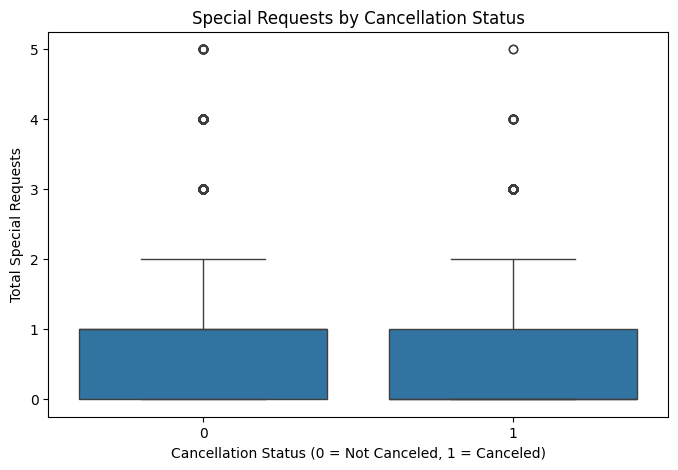

In [73]:
# Special Requests vs Cancellation

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='is_canceled',
    y='total_of_special_requests'
)

plt.title('Special Requests by Cancellation Status')
plt.xlabel('Cancellation Status (0 = Not Canceled, 1 = Canceled)')
plt.ylabel('Total Special Requests')

plt.show()

**Interpretation:** The box plot compares the number of special requests for canceled and non-canceled bookings. Differences in the distributions may indicate whether customers who make more special requests show different cancellation behavior.

### **Bookings by Customer Type**

Customer types are analyzed to understand the composition of hotel bookings and identify the most common customer categories in the dataset.

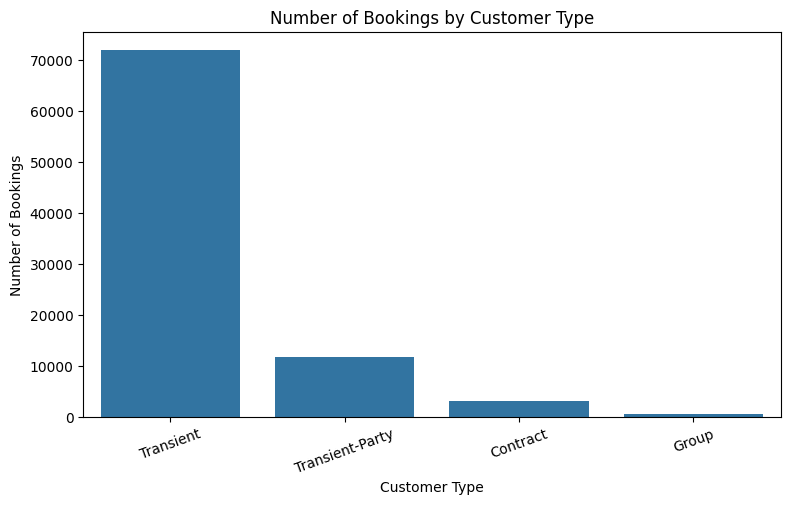

In [74]:
# Bookings by Customer Type

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='customer_type',
    order=df['customer_type'].value_counts().index
)

plt.title('Number of Bookings by Customer Type')
plt.xlabel('Customer Type')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=20)

plt.show()

**Interpretation:** The count plot shows the distribution of bookings among different customer types. The category with the highest count represents the most common type of customer in the dataset.

### **Bookings by Deposit Type**

The distribution of bookings across different deposit types is analyzed to understand the payment and deposit conditions associated with hotel reservations.

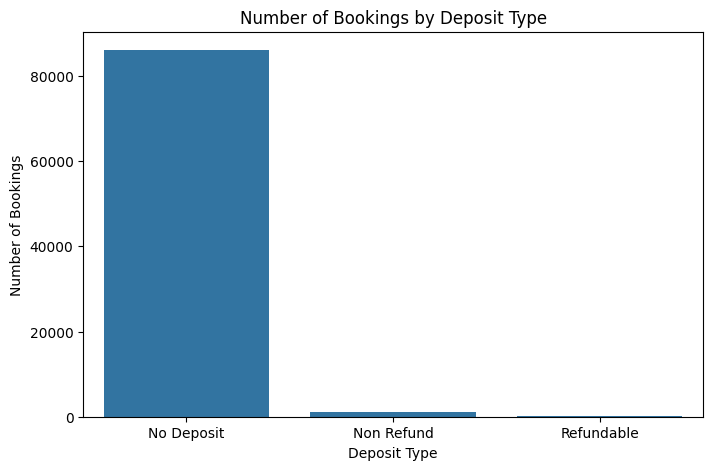

In [75]:
# Bookings by Deposit Type

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='deposit_type',
    order=df['deposit_type'].value_counts().index
)

plt.title('Number of Bookings by Deposit Type')
plt.xlabel('Deposit Type')
plt.ylabel('Number of Bookings')

plt.show()

**Interpretation:** The plot shows the distribution of bookings across deposit categories. A dominant category indicates that most reservations were made under that particular deposit condition.

### **Feature Relationship Analysis**

Feature relationships are analyzed to identify associations between important booking variables. Relationships involving lead time, stay duration, ADR, cancellation status, special requests, and previous cancellations are examined to understand factors that may influence hotel booking behavior.

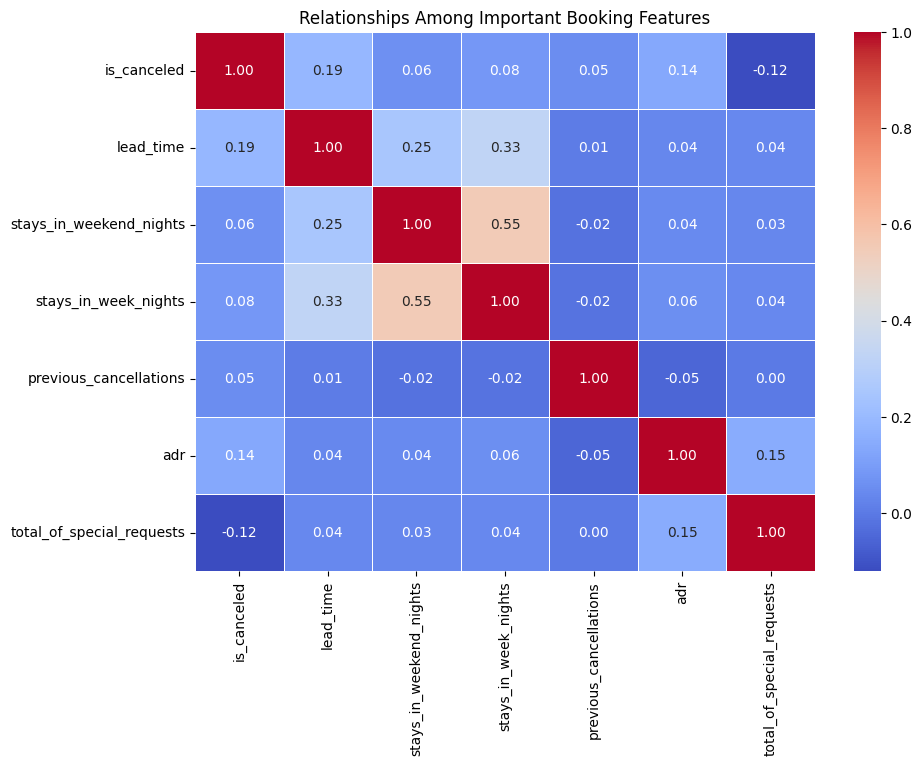

In [76]:
# Selected Feature Relationships

relationship_cols = [
    'is_canceled',
    'lead_time',
    'stays_in_weekend_nights',
    'stays_in_week_nights',
    'previous_cancellations',
    'adr',
    'total_of_special_requests'
]

relationship_matrix = df[relationship_cols].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    relationship_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5
)

plt.title('Relationships Among Important Booking Features')

plt.show()

**Interpretation:** The correlation analysis helps identify which numerical booking features are more strongly associated with each other. These relationships can provide useful insights into booking behavior and potential factors associated with cancellations.

### **Important Patterns and Trends**

The major patterns and trends identified from the exploratory analysis are summarized using the statistical results and visualizations obtained from the dataset.

In [77]:
# Important Summary Statistics

print("Total Number of Bookings:", len(df))

print("\nHotel-wise Bookings:")
print(df['hotel'].value_counts())

print("\nCancellation Distribution:")
print(df['is_canceled'].value_counts())

print("\nCancellation Rate (%):")
print((df['is_canceled'].mean() * 100).round(2))

print("\nAverage Lead Time:")
print(round(df['lead_time'].mean(), 2), "days")

print("\nAverage ADR:")
print(round(df['adr'].mean(), 2))

print("\nMost Common Market Segment:")
print(df['market_segment'].mode()[0])

print("\nMost Common Customer Type:")
print(df['customer_type'].mode()[0])

print("\nMost Common Deposit Type:")
print(df['deposit_type'].mode()[0])

print("\nMost Common Arrival Month:")
print(df['arrival_date_month'].mode()[0])

Total Number of Bookings: 87230

Hotel-wise Bookings:
hotel
City Hotel      53274
Resort Hotel    33956
Name: count, dtype: int64

Cancellation Distribution:
is_canceled
0    63221
1    24009
Name: count, dtype: int64

Cancellation Rate (%):
27.52

Average Lead Time:
78.44 days

Average ADR:
105.52

Most Common Market Segment:
Online TA

Most Common Customer Type:
Transient

Most Common Deposit Type:
No Deposit

Most Common Arrival Month:
August


### **EDA Results Interpretation**

The exploratory data analysis provides an overall understanding of hotel booking behavior. The analysis examines booking distribution across hotel types, cancellation patterns, lead time, stay duration, room pricing, customer types, market segments, deposit types, and seasonal booking trends. The visualizations also help identify relationships between important numerical features and highlight patterns that may be useful for understanding and predicting booking cancellations.

## Vector, Matrix and Probability Analysis

This section applies mathematical concepts such as vectors, matrices, correlation, covariance, and probability to the Hotel Booking Dataset.
The objective is to represent hotel booking information mathematically and analyze relationships and probabilities within the dataset.

**Identification of Numerical Features**

Vectors and matrices require numerical values. Therefore, suitable numerical features are selected from the Hotel Booking Dataset for mathematical analysis.

The selected features are:

Lead Time,
Weekend Stay Nights,
Weekday Stay Nights,
Average Daily Rate (ADR),
Total Special Requests

In [78]:
# Select numerical features for Vector and Matrix Analysis

selected_features = [
    'lead_time',
    'stays_in_weekend_nights',
    'stays_in_week_nights',
    'adr',
    'total_of_special_requests'
]

# Display the selected features
df[selected_features].head()

,lead_time,stays_in_weekend_nights,stays_in_week_nights,adr,total_of_special_requests
0,296,0,0,0.0,0
1,296,0,0,0.0,0
2,7,0,1,75.0,0
3,13,0,1,75.0,0
4,14,0,2,98.0,1


## 2. Vector Representation

A vector is an ordered collection of numerical values.

In the Hotel Booking Dataset, each hotel booking can be represented as a vector containing its numerical characteristics.

For example:

V = [Lead Time, Weekend Nights, Week Nights, ADR, Special Requests]

Therefore, one row (one booking) in the dataset is represented as one vector.

In [79]:
# Represent the first hotel booking as a vector

booking_vector = df[selected_features].iloc[0].values

print("Hotel Booking Vector:")
print(booking_vector)

Hotel Booking Vector:
[296.   0.   0.   0.   0.]


**Interpretation**

Each hotel booking is represented as a numerical vector.

The values in the vector represent important booking characteristics such as the number of days before arrival, number of nights stayed, average daily rate, and special requests.

This representation allows individual hotel bookings to be mathematically analyzed and compared.

## 3. Vector Operations 

Two hotel bookings are selected and represented as vectors.

Mathematical operations such as vector addition, subtraction, and dot product are then performed.

In [80]:
# Select two hotel bookings as vectors

vector1 = df[selected_features].iloc[0].values
vector2 = df[selected_features].iloc[1].values

print("Booking Vector 1:")
print(vector1)

print("\nBooking Vector 2:")
print(vector2)

Booking Vector 1:
[296.   0.   0.   0.   0.]

Booking Vector 2:
[296.   0.   0.   0.   0.]


**3.1 Vector Addition**

Vector addition adds the corresponding elements of two vectors.

In [81]:
# Vector Addition

vector_addition = vector1 + vector2

print("Vector Addition:")
print(vector_addition)

Vector Addition:
[592.   0.   0.   0.   0.]


**Interpretation**

Vector addition combines the corresponding numerical characteristics of two hotel bookings.

**3.2 Vector Subtraction**

Vector subtraction calculates the difference between the corresponding elements of two booking vectors.

In [82]:
# Vector Subtraction

vector_subtraction = vector1 - vector2

print("Vector Subtraction:")
print(vector_subtraction)

Vector Subtraction:
[0. 0. 0. 0. 0.]


**Interpretation**

Vector subtraction shows the numerical difference between two hotel bookings.

For example, it can show differences in lead time, stay duration, ADR, and number of special requests.

**3.3 Dot Product**

The dot product combines two vectors and produces a single numerical value.

In [83]:
# Dot Product

dot_product = np.dot(vector1, vector2)

print("Dot Product:")
print(dot_product)

Dot Product:
87616.0


**Interpretation**

The dot product provides a mathematical value based on the combined numerical characteristics of two hotel booking vectors.

## 4. Matrix Representation

A matrix is a rectangular arrangement of numerical values.

In the Hotel Booking Dataset:

Each row represents one hotel booking.
Each column represents one numerical feature.

Therefore, multiple hotel bookings can be represented together as a matrix.

In [84]:
# Represent the first 10 hotel bookings as a matrix

booking_matrix = df[selected_features].head(10).values

print("Booking Matrix:")
print(booking_matrix)

print("\nMatrix Shape:")
print(booking_matrix.shape)

Booking Matrix:
[[296.    0.    0.    0.    0. ]
 [296.    0.    0.    0.    0. ]
 [  7.    0.    1.   75.    0. ]
 [ 13.    0.    1.   75.    0. ]
 [ 14.    0.    2.   98.    1. ]
 [  0.    0.    2.  107.    0. ]
 [  9.    0.    2.  103.    1. ]
 [ 85.    0.    3.   82.    1. ]
 [ 75.    0.    3.  105.5   0. ]
 [ 23.    0.    4.  123.    0. ]]

Matrix Shape:
(10, 5)


**Interpretation**

The matrix shape represents:

(Number of Hotel Bookings, Number of Numerical Features)

For example, a matrix shape of (10, 5) means that 10 hotel bookings are represented using 5 numerical features.

## 5. Matrix Transpose

The transpose of a matrix changes rows into columns and columns into rows.

The original booking matrix represents bookings as rows and features as columns.

After transposition, features become rows and bookings become columns.

In [85]:
# Matrix Transpose

transpose_matrix = booking_matrix.T

print("Original Matrix Shape:")
print(booking_matrix.shape)

print("\nTranspose Matrix Shape:")
print(transpose_matrix.shape)

print("\nTransposed Matrix:")
print(transpose_matrix)

Original Matrix Shape:
(10, 5)

Transpose Matrix Shape:
(5, 10)

Transposed Matrix:
[[296.  296.    7.   13.   14.    0.    9.   85.   75.   23. ]
 [  0.    0.    0.    0.    0.    0.    0.    0.    0.    0. ]
 [  0.    0.    1.    1.    2.    2.    2.    3.    3.    4. ]
 [  0.    0.   75.   75.   98.  107.  103.   82.  105.5 123. ]
 [  0.    0.    0.    0.    1.    0.    1.    1.    0.    0. ]]


## 6. Matrix Operations

### 6.1 Matrix Addition

Two matrices with the same dimensions can be added by adding their corresponding elements.

In [86]:
# Create two matrices using different hotel bookings

matrix1 = df[selected_features].iloc[0:5].values
matrix2 = df[selected_features].iloc[5:10].values

# Matrix Addition
matrix_addition = matrix1 + matrix2

print("Matrix 1:")
print(matrix1)

print("\nMatrix 2:")
print(matrix2)

print("\nMatrix Addition:")
print(matrix_addition)

Matrix 1:
[[296.   0.   0.   0.   0.]
 [296.   0.   0.   0.   0.]
 [  7.   0.   1.  75.   0.]
 [ 13.   0.   1.  75.   0.]
 [ 14.   0.   2.  98.   1.]]

Matrix 2:
[[  0.    0.    2.  107.    0. ]
 [  9.    0.    2.  103.    1. ]
 [ 85.    0.    3.   82.    1. ]
 [ 75.    0.    3.  105.5   0. ]
 [ 23.    0.    4.  123.    0. ]]

Matrix Addition:
[[296.    0.    2.  107.    0. ]
 [305.    0.    2.  103.    1. ]
 [ 92.    0.    4.  157.    1. ]
 [ 88.    0.    4.  180.5   0. ]
 [ 37.    0.    6.  221.    1. ]]


### Interpretation

Matrix addition adds corresponding numerical characteristics from two groups of hotel bookings.

### 6.2 Scalar Multiplication

Scalar multiplication multiplies every element of a matrix by a single constant value.

In [87]:
# Scalar Multiplication

scalar = 2

scalar_result = scalar * matrix1

print("Result of Scalar Multiplication:")
print(scalar_result)

Result of Scalar Multiplication:
[[592.   0.   0.   0.   0.]
 [592.   0.   0.   0.   0.]
 [ 14.   0.   2. 150.   0.]
 [ 26.   0.   2. 150.   0.]
 [ 28.   0.   4. 196.   2.]]


### Interpretation

Scalar multiplication multiplies every numerical value in the booking matrix by the selected scalar value.

### 6.3 Matrix Multiplication

Matrix multiplication is performed by multiplying the booking matrix with its transpose.

In [88]:
# Matrix Multiplication

matrix_product = np.dot(matrix1, matrix1.T)

print("Matrix Multiplication Result:")
print(matrix_product)

Matrix Multiplication Result:
[[87616. 87616.  2072.  3848.  4144.]
 [87616. 87616.  2072.  3848.  4144.]
 [ 2072.  2072.  5675.  5717.  7450.]
 [ 3848.  3848.  5717.  5795.  7534.]
 [ 4144.  4144.  7450.  7534.  9805.]]


### Interpretation

Matrix multiplication produces a new matrix representing mathematical relationships between hotel booking vectors.

## 7. Correlation Matrix

Correlation measures the strength and direction of the relationship between numerical variables.

Correlation values range from -1 to +1:

- Positive correlation: Both variables tend to increase together.
- Negative correlation: One variable tends to decrease when the other increases.
- Correlation near zero: Little or no linear relationship.

In [89]:
# Calculate Correlation Matrix

correlation_matrix = df[selected_features].corr()

print("Correlation Matrix:")
print(correlation_matrix)

Correlation Matrix:
                           lead_time  stays_in_weekend_nights  \
lead_time                   1.000000                 0.249108   
stays_in_weekend_nights     0.249108                 1.000000   
stays_in_week_nights        0.326353                 0.550471   
adr                         0.036334                 0.043142   
total_of_special_requests   0.040673                 0.032816   

                           stays_in_week_nights       adr  \
lead_time                              0.326353  0.036334   
stays_in_weekend_nights                0.550471  0.043142   
stays_in_week_nights                   1.000000  0.058407   
adr                                    0.058407  1.000000   
total_of_special_requests              0.038336  0.150598   

                           total_of_special_requests  
lead_time                                   0.040673  
stays_in_weekend_nights                     0.032816  
stays_in_week_nights                        0.038336  
ad

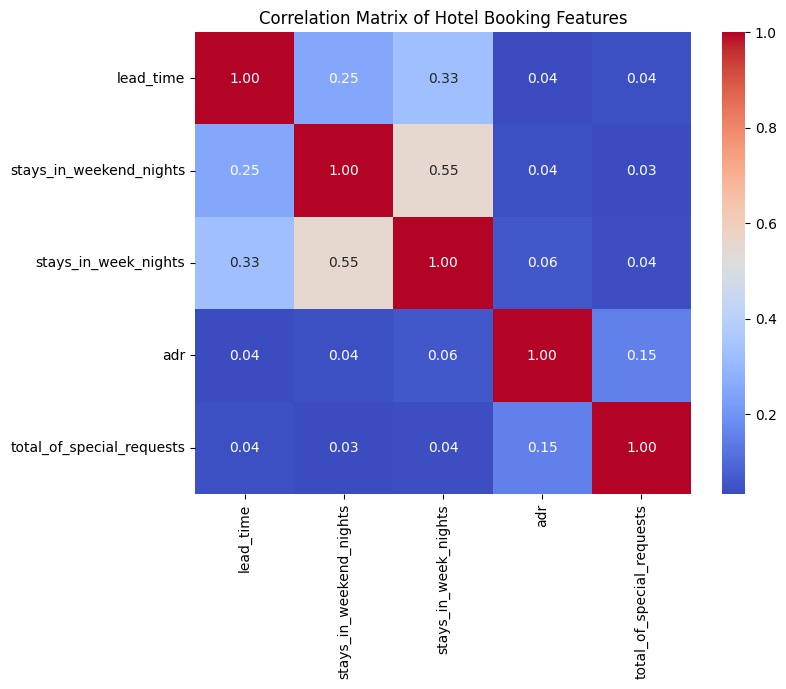

In [90]:
# Visualize Correlation Matrix

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix of Hotel Booking Features")

plt.show()

The strongest relationship is between weekend and weekday stays (correlation = 0.55), indicating that guests who stay more weekend nights generally tend to stay more weekday nights as well. Most other feature pairs show weak or negligible correlations, suggesting that these variables are largely independent in terms of linear relationships.

## 8. Covariance Matrix

Covariance measures how two numerical variables vary together.

- Positive covariance indicates that two variables generally increase or decrease together.
- Negative covariance indicates that one variable tends to increase while the other decreases.

In [91]:
# Calculate Covariance Matrix

covariance_matrix = df[selected_features].cov()

print("Covariance Matrix:")
print(covariance_matrix)

Covariance Matrix:
                             lead_time  stays_in_weekend_nights  \
lead_time                  6569.545175                20.744271   
stays_in_weekend_nights      20.744271                 1.055568   
stays_in_week_nights         53.957169                 1.153644   
adr                         144.408902                 2.173501   
total_of_special_requests     2.742995                 0.028053   

                           stays_in_week_nights          adr  \
lead_time                             53.957169   144.408902   
stays_in_weekend_nights                1.153644     2.173501   
stays_in_week_nights                   4.160908     5.842196   
adr                                    5.842196  2404.531315   
total_of_special_requests              0.065065     6.144466   

                           total_of_special_requests  
lead_time                                   2.742995  
stays_in_weekend_nights                     0.028053  
stays_in_week_nights        

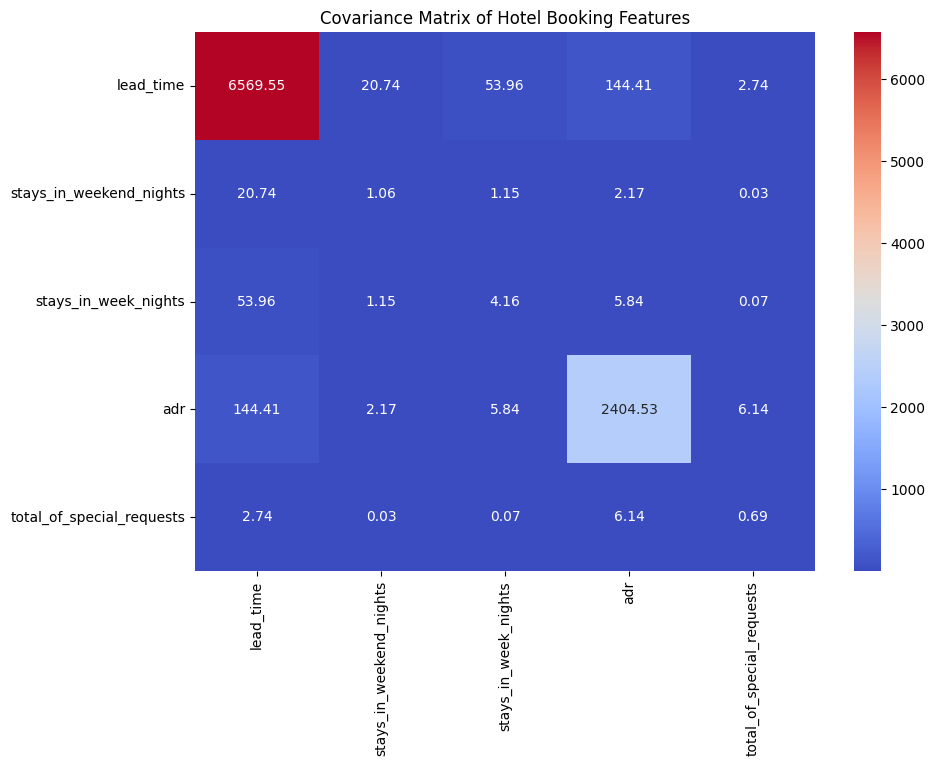

In [92]:
# Visualize Covariance Matrix

plt.figure(figsize=(10, 7))

sns.heatmap(
    covariance_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Covariance Matrix of Hotel Booking Features")

plt.show()

### Interpretation

The covariance matrix indicates that most numerical features have positive but relatively small covariance with each other. The largest covariance between different variables is observed between lead_time and adr (144.41), while stays_in_weekend_nights and total_of_special_requests show almost no joint variation (0.03). The diagonal values represent the individual variances of the features. Since covariance is affected by the scale of variables, the correlation matrix provides a better measure for comparing the strength of relationships.

## Eigen Values and Eigen Vectors

In [93]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Numerical features used in the covariance matrix
features = [
    'lead_time',
    'stays_in_weekend_nights',
    'stays_in_week_nights',
    'adr',
    'total_of_special_requests'
]

# Remove missing values
X = df[features].dropna()

# Calculate covariance matrix
cov_matrix = X.cov()

print("Covariance Matrix:")
display(cov_matrix)

# Calculate eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eig(cov_matrix)

# Sort from largest to smallest
idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

# Create table
explained_variance = (eigenvalues / eigenvalues.sum()) * 100

eigen_df = pd.DataFrame({
    'Principal Component': [f'PC{i+1}' for i in range(len(eigenvalues))],
    'Eigenvalue': eigenvalues,
    'Explained Variance (%)': explained_variance
})

display(eigen_df)

Covariance Matrix:


,lead_time,stays_in_weekend_nights,stays_in_week_nights,adr,total_of_special_requests
lead_time,6569.545175,20.744271,53.957169,144.408902,2.742995
stays_in_weekend_nights,20.744271,1.055568,1.153644,2.173501,0.028053
stays_in_week_nights,53.957169,1.153644,4.160908,5.842196,0.065065
adr,144.408902,2.173501,5.842196,2404.531315,6.144466
total_of_special_requests,2.742995,0.028053,0.065065,6.144466,0.692309


,Principal Component,Eigenvalue,Explained Variance (%)
0,PC1,6575.059209,73.219042
1,PC2,2399.553093,26.721125
2,PC3,4.025014,0.044822
3,PC4,0.679054,0.007562
4,PC5,0.668905,0.007449


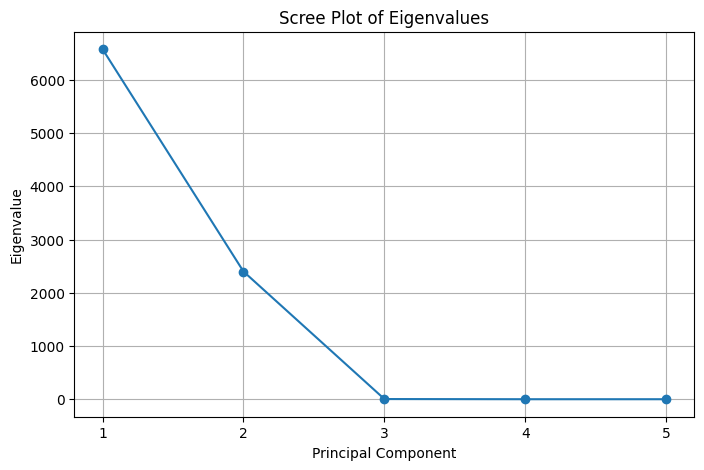

In [94]:
plt.figure(figsize=(8,5))

plt.plot(
    range(1, len(eigenvalues) + 1),
    eigenvalues,
    marker='o'
)

plt.xlabel('Principal Component')
plt.ylabel('Eigenvalue')
plt.title('Scree Plot of Eigenvalues')
plt.xticks(range(1, len(eigenvalues) + 1))
plt.grid(True)

plt.show()

### Interpretation
Eigenvalues indicate the amount of variance captured by each principal component. A higher eigenvalue means that the corresponding principal component contains more variation and therefore more information from the hotel booking data. The first few components with larger eigenvalues are more important, while components with smaller eigenvalues contribute less. The explained variance percentage shows the proportion of total variation represented by each component. These eigenvalues and eigenvectors form the mathematical basis of Principal Component Analysis (PCA) and can be used for dimensionality reduction.

## 9. Simple Probability

The Hotel Booking Dataset contains the variable `is_canceled`.

- 1 represents a canceled booking.
- 0 represents a booking that was not canceled.

The probability of cancellation is calculated as:

P(Cancellation) = Number of Canceled Bookings / Total Number of Bookings

In [95]:
# Calculate Probability of Booking Cancellation

total_bookings = len(df)

canceled_bookings = df['is_canceled'].sum()

probability_cancellation = canceled_bookings / total_bookings

print("Total Bookings:", total_bookings)
print("Canceled Bookings:", canceled_bookings)
print("Probability of Cancellation:", probability_cancellation)

print(
    "Cancellation Percentage:",
    round(probability_cancellation * 100, 2),
    "%"
)

Total Bookings: 87230
Canceled Bookings: 24009
Probability of Cancellation: 0.2752378768772211
Cancellation Percentage: 27.52 %


### Interpretation

The calculated probability represents the chance that a randomly selected hotel booking from the dataset will be canceled.

## 10. Conditional Probability

Conditional probability calculates the probability of an event when another condition is known.

In this analysis, we calculate the probability of cancellation given the hotel type.

P(Canceled | City Hotel)

This represents the probability that a booking is canceled when it is known that the booking belongs to a City Hotel.

In [96]:
# Probability of Cancellation given City Hotel

city_hotel_data = df[df['hotel'] == 'City Hotel']

P_cancel_given_city = (
    city_hotel_data['is_canceled'].sum()
    / len(city_hotel_data)
)

print(
    "Probability of Cancellation given City Hotel:",
    P_cancel_given_city
)

print(
    "Percentage:",
    round(P_cancel_given_city * 100, 2),
    "%"
)

Probability of Cancellation given City Hotel: 0.30099110260164436
Percentage: 30.1 %


### Probability of Cancellation Given Resort Hotel

P(Canceled | Resort Hotel)

In [97]:
# Probability of Cancellation given Resort Hotel

resort_hotel_data = df[df['hotel'] == 'Resort Hotel']

P_cancel_given_resort = (
    resort_hotel_data['is_canceled'].sum()
    / len(resort_hotel_data)
)

print(
    "Probability of Cancellation given Resort Hotel:",
    P_cancel_given_resort
)

print(
    "Percentage:",
    round(P_cancel_given_resort * 100, 2),
    "%"
)

Probability of Cancellation given Resort Hotel: 0.23483331370008245
Percentage: 23.48 %


## 11. Comparison of Conditional Probabilities

The cancellation probabilities of City Hotels and Resort Hotels are compared to determine whether hotel type influences the likelihood of booking cancellation.

In [98]:
# Compare cancellation probabilities

print("Conditional Probability Comparison")

print(
    "City Hotel:",
    round(P_cancel_given_city * 100, 2),
    "%"
)

print(
    "Resort Hotel:",
    round(P_cancel_given_resort * 100, 2),
    "%"
)

Conditional Probability Comparison
City Hotel: 30.1 %
Resort Hotel: 23.48 %


The probability of a booking being canceled is higher for City Hotels (30.10%) than for Resort Hotels (23.48%). This indicates that hotel type appears to influence the likelihood of booking cancellation. A booking at a City Hotel has approximately a 6.62 percentage-point higher cancellation probability than a booking at a Resort Hotel.

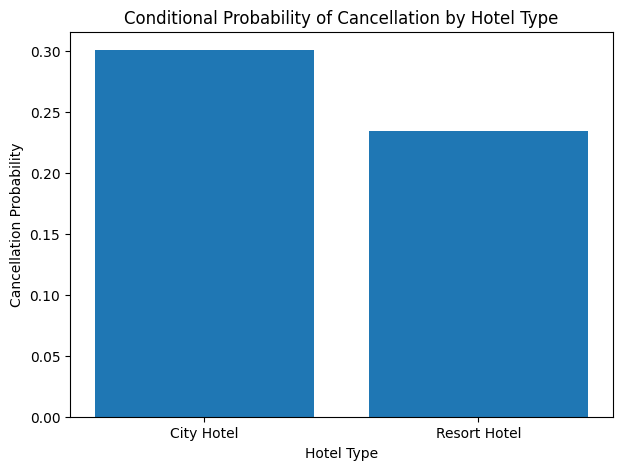

In [99]:
# Visualize Conditional Probabilities

hotel_types = ['City Hotel', 'Resort Hotel']

probabilities = [
    P_cancel_given_city,
    P_cancel_given_resort
]

plt.figure(figsize=(7, 5))

plt.bar(hotel_types, probabilities)

plt.xlabel("Hotel Type")
plt.ylabel("Cancellation Probability")
plt.title("Conditional Probability of Cancellation by Hotel Type")

plt.show()

## Bayes' Theorem

In [100]:
# Bayes' Theorem

# A = Booking is cancelled
# B = Booking is from City Hotel

# P(A) - Probability of cancellation
P_cancel = (df['is_canceled'] == 1).mean()

# P(B) - Probability of booking being from City Hotel
P_city = (df['hotel'] == 'City Hotel').mean()

# P(B|A) - Probability of City Hotel given that booking is cancelled
P_city_given_cancel = (
    ((df['hotel'] == 'City Hotel') & 
     (df['is_canceled'] == 1)).sum()
    / (df['is_canceled'] == 1).sum()
)

# Bayes' Theorem
P_cancel_given_city = (
    P_city_given_cancel * P_cancel
) / P_city

print("Bayes' Theorem")
print("----------------------------")
print("P(Cancelled):", P_cancel)
print("P(City Hotel):", P_city)
print("P(City Hotel | Cancelled):", P_city_given_cancel)
print("P(Cancelled | City Hotel):", P_cancel_given_city)
print("Percentage:", P_cancel_given_city * 100, "%")

Bayes' Theorem
----------------------------
P(Cancelled): 0.2752378768772211
P(City Hotel): 0.6107302533532042
P(City Hotel | Cancelled): 0.6678745470448582
P(Cancelled | City Hotel): 0.3009911026016443
Percentage: 30.09911026016443 %


Bayes' Theorem was applied to determine the probability that a booking is canceled given that it belongs to a City Hotel. The overall probability of cancellation and the probability of a City Hotel booking were combined with the probability of a City Hotel booking given cancellation. The resulting probability represents the likelihood of cancellation for a City Hotel booking.

## Probability Distribution –Bernoulli Distribution

In [101]:
from scipy.stats import bernoulli

p = df['is_canceled'].mean()

print("Probability of cancellation:", p)
print("Probability of no cancellation:", 1-p)

# Probability mass function
x = [0, 1]
pmf = bernoulli.pmf(x, p)

print("P(X=0):", pmf[0])
print("P(X=1):", pmf[1])

Probability of cancellation: 0.2752378768772211
Probability of no cancellation: 0.7247621231227789
P(X=0): 0.7247621231227789
P(X=1): 0.2752378768772211


The is_canceled variable is modeled using a Bernoulli distribution, where 1 represents a canceled booking and 0 represents a non-canceled booking. The probability of cancellation is 0.3704 (37.04%), while the probability of a booking not being canceled is 0.6296 (62.96%). Thus, approximately 37% of bookings in the dataset were canceled, whereas approximately 63% were not canceled.

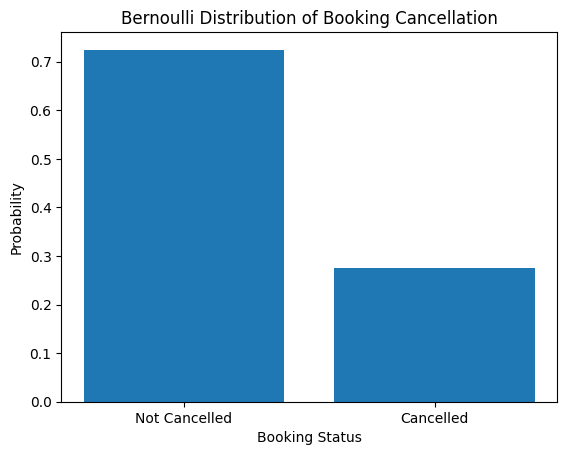

In [102]:
import matplotlib.pyplot as plt

plt.bar(x, pmf)
plt.xticks([0, 1], ['Not Cancelled', 'Cancelled'])
plt.xlabel('Booking Status')
plt.ylabel('Probability')
plt.title('Bernoulli Distribution of Booking Cancellation')
plt.show()

## Binomial Distribution

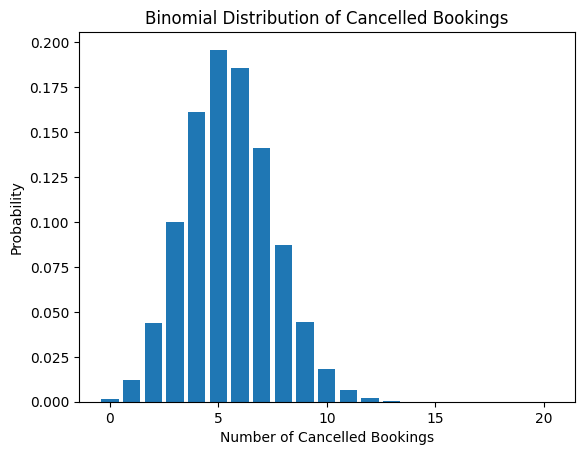

In [103]:
from scipy.stats import binom

n = 20
p = df['is_canceled'].mean()

x = range(0, n+1)
probabilities = binom.pmf(x, n, p)

plt.bar(x, probabilities)
plt.xlabel('Number of Cancelled Bookings')
plt.ylabel('Probability')
plt.title('Binomial Distribution of Cancelled Bookings')
plt.show()

The binomial distribution models the number of canceled bookings among 20 randomly selected bookings, using the observed cancellation probability of 37.04%. The distribution shows that the most probable outcome is around 7–8 canceled bookings out of 20. This is consistent with the expected number of cancellations, which is \(np = 20 x 0.3704=7.41). Therefore, when 20 bookings are randomly selected, approximately 7 to 8 cancellations are most likely to occur.

probability of exact 5 cancellation

In [104]:
# Probability of exactly 5 cancellations
prob_5 = binom.pmf(5, n, p)

print("P(X = 5):", prob_5)

P(X = 5): 0.1958470722576347


probability of atmost 5 cancellation

In [105]:
# Probability of at most 5 cancellations
prob_at_most_5 = binom.cdf(5, n, p)

print("P(X <= 5):", prob_at_most_5)

P(X <= 5): 0.514424506099706


## Normal Distribution(Average Daily Rate)

Mean (μ): 105.51980591539608
Standard Deviation (σ): 49.03602059053271


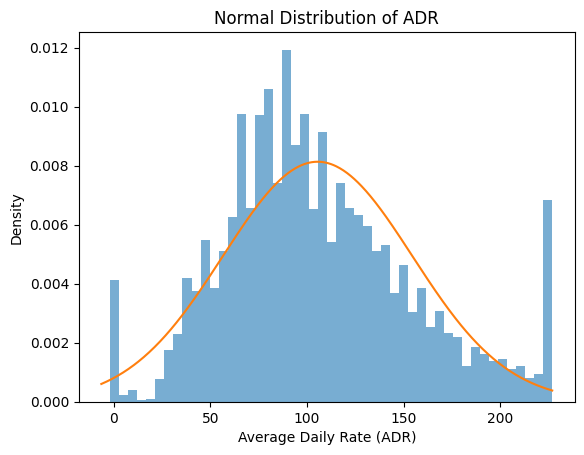

In [106]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# ADR data
adr = df['adr'].dropna()

# Mean and standard deviation
mu = adr.mean()
sigma = adr.std()

print("Mean (μ):", mu)
print("Standard Deviation (σ):", sigma)

# Generate normal distribution curve
x = np.linspace(adr.min(), adr.max(), 500)
y = norm.pdf(x, mu, sigma)

plt.hist(adr, bins=50, density=True, alpha=0.6)
plt.plot(x, y)
plt.xlabel('Average Daily Rate (ADR)')
plt.ylabel('Density')
plt.title('Normal Distribution of ADR')
plt.show()

The Average Daily Rate (ADR) is treated as a continuous random variable and is modeled using a Normal Distribution. The mean ADR is 101.83, while the standard deviation is 50.54. This indicates that the average daily room rate is centered around 101.83, with considerable variation in room prices. The histogram along with the fitted normal curve can be used to assess how closely the ADR values follow a normal distribution.

probability that ADR is below 100

In [107]:
prob = norm.cdf(100, mu, sigma)

print("P(ADR < 100):", prob)
print("Percentage:", prob * 100, "%")

P(ADR < 100): 0.4551871816481462
Percentage: 45.51871816481462 %


# **Sampling & Central Limit Theorem**

## **Sampling**

Sampling is the process of selecting a smaller group of data  from the dataset.

The Hotel Booking Dataset contains a large number of booking records.Instead of analyzing the entire dataset we can study smaller samples to understand the data efficiently

For the analysis, *ADR* (Average Daily Rate) is selected as the main numerical variable because it represents the daily room price for each booking
    
Random samples of different sizes are taken from the dataset, and their sample means is  calculated.

### **Selection of Sampling Variable**

The variable *ADR* (Average Daily Rate) is selected for sampling and Central Limit Theorem analysis.

ADR is a numerical variable which is suitable for calculating sample means. By studying the distribution of the sample means we can understand how the means change as the sample size increases.

In [108]:
print("Number of ADR observations:", df['adr'].count())
print("\nADR Summary Statistics:")
print(df['adr'].describe())

Number of ADR observations: 87230

ADR Summary Statistics:
count    87230.000000
mean       105.519806
std         49.036021
min         -6.380000
25%         72.250000
50%         98.200000
75%        134.100000
max        226.875000
Name: adr, dtype: float64


In [109]:
population_mean = df['adr'].mean()
print("Population Mean of ADR:", round(population_mean, 2))

Population Mean of ADR: 105.52


## **Random Sampling**

Random samples are selected from the ADR values using different sample sizes.

Three sample sizes are considered:

- Sample size = 30
- Sample size = 100
- Sample size = 500

A fixed random size is used so that we get the same results every time we run the analysis.


In [110]:
sample_30 = df['adr'].dropna().sample(n=30, random_state=42)
sample_100 = df['adr'].dropna().sample(n=100, random_state=42)
sample_500 = df['adr'].dropna().sample(n=500, random_state=42)

print("Sample size 30 mean:", round(sample_30.mean(), 2))
print("Sample size 100 mean:", round(sample_100.mean(), 2))
print("Sample size 500 mean:", round(sample_500.mean(), 2))

Sample size 30 mean: 106.06
Sample size 100 mean: 99.79
Sample size 500 mean: 103.09


### **Interpretation**

The sample means gives us the  estimates of the overall mean (avg) ADR of the dataset.

The sample mean may differ from the population mean because each sample contains a different set of observations. In general, larger samples give more reliable and stable estimates of the overall mean.

## **Simple Random Sampling**

To understand how sample means behave, random sampling is repeated multiple times

For each sample size, 1,000 random samples are taken from the ADR data, and the mean ADR is calculated for each sample.

The resulting sample means are then analyzed to observe how they are  distributed and how they change with different sample sizes.

In [111]:
def repeated_sampling(data, sample_size, repetitions=1000):
    sample_means = []

    for _ in range(repetitions):
        sample = data.sample(n=sample_size)
        sample_means.append(sample.mean())

    return np.array(sample_means)


# Remove missing ADR values
adr_data = df['adr'].dropna()

# Generate sample means
means_30 = repeated_sampling(adr_data, 30)
means_100 = repeated_sampling(adr_data, 100)
means_500 = repeated_sampling(adr_data, 500)

print("Number of sample means generated:")
print("Sample size 30:", len(means_30))
print("Sample size 100:", len(means_100))
print("Sample size 500:", len(means_500))

Number of sample means generated:
Sample size 30: 1000
Sample size 100: 1000
Sample size 500: 1000


### **Why Simple Random Sampling is Used**

Simple random sampling is used here because the objective is to study the sampling distribution of the sample mean and demonstrate the Central Limit Theorem (CLT).

In Simple Random Sampling, every observation has an equal chance of being selected. This allows us to repeatedly generate different random samples and observe how their sample means behave as the sample size increases.

Why other sampling methods are not necessary for this experiment:

- Stratified sampling is used when we want to ensure that specific groups in the population are represented.
- Systematic sampling selects observations at regular intervals.
- Cluster sampling selects entire groups or clusters.

Since our goal is simply to observe how sample means change with different sample sizes we are using Simple Random Sampling.

## **Distribution of Sample Means**

For each sample size, the mean and standard deviation of the sample means are calculated.

This helps us see how much the sample means vary and how their variation decreases as the sample size increases.

In [112]:
sampling_summary = pd.DataFrame({
    'Sample Size': [30, 100, 500],
    'Mean of Sample Means': [
        means_30.mean(),
        means_100.mean(),
        means_500.mean()
    ],
    'Standard Deviation of Sample Means': [
        means_30.std(),
        means_100.std(),
        means_500.std()
    ]
})

sampling_summary.round(2)

,Sample Size,Mean of Sample Means,Standard Deviation of Sample Means
0,30,105.00,9.03
1,100,105.62,4.80
2,500,105.51,2.17


### **Interpretation**
The avearge of all the sample means is expected to be close to the overall mean of ADR 

As the sample size increases, the standard deviation of the sample means generally decreases.This means that larger samples give more stable and reliable estimates of the overall mean.

## **Central Limit Theorem (CLT)**

If we repeatedly take random samples of the same size from a population and calculate the mean of each sample, the distribution of those sample means becomes approximately normal (bell-shaped), regardless of the original population distribution, provided the sample size is sufficiently large.

The distributions of sample means for sample sizes 30, 100, and 500 are visualized below.

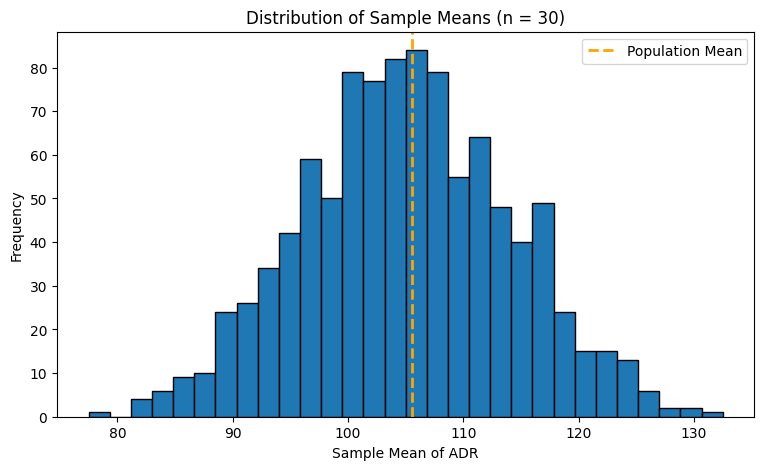

In [113]:
# Distribution of sample means for sample size 30
plt.figure(figsize=(9, 5))
plt.hist(means_30, bins=30, edgecolor='black')
plt.axvline(population_mean, linestyle='--', linewidth=2,
            label='Population Mean',color ='orange')

plt.title('Distribution of Sample Means (n = 30)')
plt.xlabel('Sample Mean of ADR')
plt.ylabel('Frequency')
plt.legend()
plt.show()

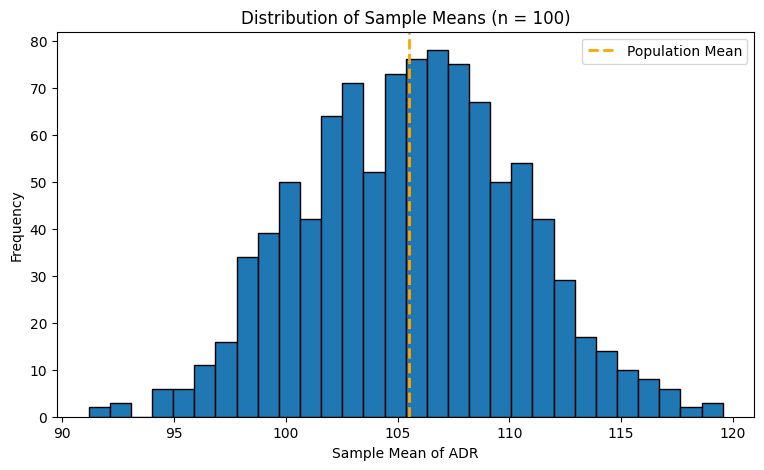

In [114]:
# Distribution of sample means for sample size 100
plt.figure(figsize=(9, 5))
plt.hist(means_100, bins=30, edgecolor='black')
plt.axvline(population_mean, linestyle='--', linewidth=2,
            label='Population Mean',color ='orange')

plt.title('Distribution of Sample Means (n = 100)')
plt.xlabel('Sample Mean of ADR')
plt.ylabel('Frequency')
plt.legend()
plt.show()

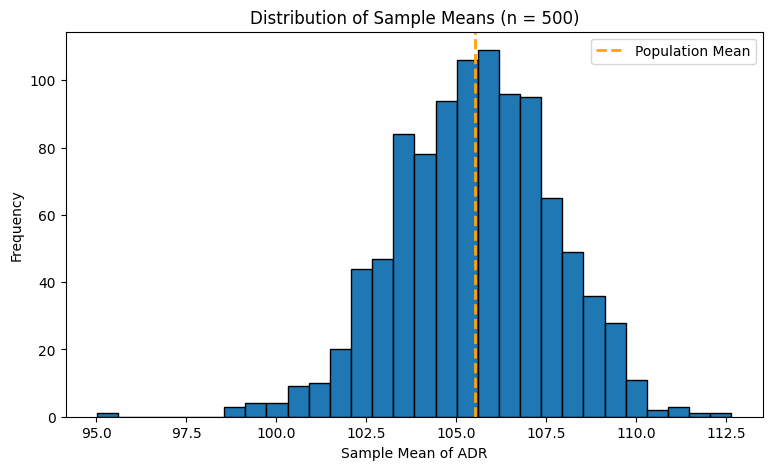

In [115]:
# Distribution of sample means for sample size 500
plt.figure(figsize=(9, 5))
plt.hist(means_500, bins=30, edgecolor='black')
plt.axvline(population_mean, linestyle='--', linewidth=2,
            label='Population Mean',color ='orange')

plt.title('Distribution of Sample Means (n = 500)')
plt.xlabel('Sample Mean of ADR')
plt.ylabel('Frequency')
plt.legend()
plt.show()

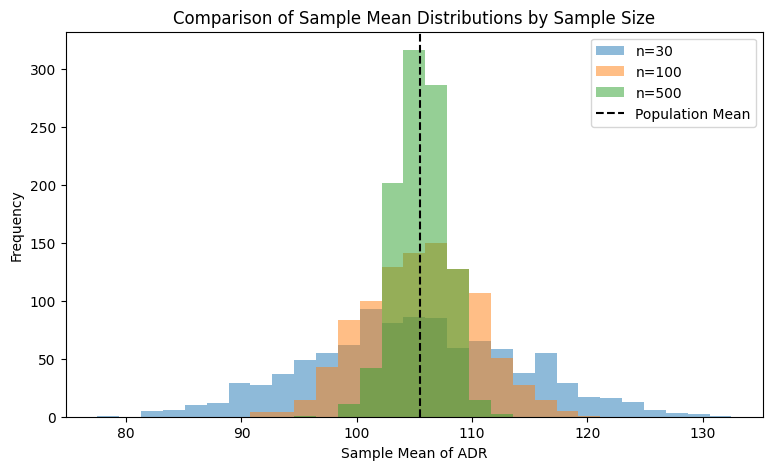

In [116]:
bins = np.linspace(
    min(means_30.min(), means_100.min(), means_500.min()),
    max(means_30.max(), means_100.max(), means_500.max()),
    30
)

plt.figure(figsize=(9,5))

plt.hist(means_30, bins=bins, alpha=0.5, label='n=30')
plt.hist(means_100, bins=bins, alpha=0.5, label='n=100')
plt.hist(means_500, bins=bins, alpha=0.5, label='n=500')

plt.axvline(
    population_mean,
    color='black',
    linestyle='--',
    label='Population Mean'
)

plt.title('Comparison of Sample Mean Distributions by Sample Size')
plt.xlabel('Sample Mean of ADR')
plt.ylabel('Frequency')
plt.legend()

plt.show()

### **Interpretation of CLT**

As the sample size increases, the sample means become more concentrated around the overall mean

Smaller samples have more variation in their sample means. When the sample size increases from 30 to 100 and then to 500, the spread of the sample means becomes smaller as the standard error decreases as the sample size increases .

The sampling distributions also become approximately bell-shaped, which demonstrates the Central Limit Theorem (CLT). This shows that larger samples give more reliable estimates of the overall mean,as thier sample means tend to be closer to the population mean 

## **Comparison of Different Sample Sizes**

The sampling distributions are compared using their mean and standard deviation to understand the effect of sample size.

In [117]:
comparison = pd.DataFrame({
    'Sample Size': [30, 100, 500],
    'Mean of Sample Means': [
        means_30.mean(),
        means_100.mean(),
        means_500.mean()
    ],
    'Population Mean': [population_mean] * 3,
    'Standard Deviation of Sample Means': [
        means_30.std(),
        means_100.std(),
        means_500.std()
    ]
})

comparison.round(2)

,Sample Size,Mean of Sample Means,Population Mean,Standard Deviation of Sample Means
0,30,105.00,105.52,9.03
1,100,105.62,105.52,4.80
2,500,105.51,105.52,2.17


### Theoretical Standard Error vs Observed Standard Deviation
The **Observed SD of Sample Means** shows the actual deviation in the sample means obtained from our simulation.

The **Theoretical Standard Error (SE)** shows the expected deviation in sample means according to statistical theory.

The Standard Error is calculated using:
SE = SD/root(n)
where:
- SD = population standard deviation
- n = sample size

We compare the **Observed SD** with the **Theoretical SE** to check whether the results from our simulation agree with the theoretical expectation.

If the two values are close, it indicates that the sampling distribution of the sample mean behaves as expected.

As the sample size increases, the Standard Error decreases. Therefore, larger samples produce sample means with **less variability and greater precision**.

In [118]:
# Theoretical Standard Error vs Observed Standard Deviation
population_std = adr_data.std()
sample_sizes = [30, 100, 500]
observed_sd = [
    means_30.std(),
    means_100.std(),
    means_500.std()
]
theoretical_se = [
    population_std / np.sqrt(n)
    for n in sample_sizes
]
se_comparison = pd.DataFrame({
    'Sample Size': sample_sizes,
    'Observed SD of Sample Means': observed_sd,
    'Theoretical Standard Error': theoretical_se
})
se_comparison.round(2)

,Sample Size,Observed SD of Sample Means,Theoretical Standard Error
0,30,9.03,8.95
1,100,4.80,4.90
2,500,2.17,2.19


### **95% Confidence Interval Coverage**

A 95% confidence interval gives a range of values that is expected to contain the true population mean in about 95% of repeated samples.

In this experiment, we take 1000 random samples for each sample size (30, 100, and 500). For every sample, a 95% confidence interval is calculated and checked to see whether it contains the true population mean.

The 95% CI Coverage shows the percentage of these 1000 confidence intervals that actually contain the true population mean.

This experiment demonstrates whether the calculated confidence intervals achieve the expected 95% coverage.

In [119]:
def confidence_interval_coverage(data, sample_size, population_mean,
                                  repetitions=1000):
    covered = 0
    for _ in range(repetitions):
        sample = data.sample(n=sample_size)#randomly as we select same everytime we get the same confidence interval 
        sample_mean = sample.mean()
        sample_std = sample.std()
        standard_error = sample_std / np.sqrt(sample_size)
        #formula for upper and lower value boundary 
        lower = sample_mean - 1.96 * standard_error
        upper = sample_mean + 1.96 * standard_error
        #checking if the mean is in the interval 
        if lower <= population_mean <= upper:
            covered += 1
    #calculating the percent 
    coverage_percentage = (covered / repetitions) * 100
    return coverage_percentage
coverage_30 = confidence_interval_coverage(
    adr_data, 30, population_mean
)
coverage_100 = confidence_interval_coverage(
    adr_data, 100, population_mean
)
coverage_500 = confidence_interval_coverage(
    adr_data, 500, population_mean
)
coverage_table = pd.DataFrame({
    'Sample Size': [30, 100, 500],
    '95% CI Coverage (%)': [
        coverage_30,
        coverage_100,
        coverage_500
    ]
})
coverage_table.round(2)

,Sample Size,95% CI Coverage (%)
0,30,93.0
1,100,95.1
2,500,95.9


## **Overall Sampling Interpretation**

Random sampling was performed using ADR as the sampling variable.

Three different sample sizes (30, 100, and 500) were analyzed through repeated random sampling. The results show that the mean of the sampling distributions remains close to the population mean.

As the sample size increases, the variability of the sample means decreases. Therefore, larger samples provide more consistent estimates of the population mean.

The distributions of sample means also become approximately normal, demonstrating the Central Limit Theorem.

## **Overall Insights**

- The dataset initially contained **119,390 hotel bookings with 32 features**.
- After preprocessing, duplicate records, invalid records, missing values, and extreme outliers were appropriately handled, resulting in a cleaner dataset of **87,230 valid bookings** for analysis.
- **City Hotel** accounts for the larger share of bookings, with **53,274 bookings**, compared with **33,956 bookings** for Resort Hotel.
- Overall, **27.52% of bookings were canceled**, while **72.48% were not canceled**.
- Cancellation risk differs by hotel type:
  - **City Hotel:** 30.10% cancellation probability
  - **Resort Hotel:** 23.48% cancellation probability
- The average **lead time is 78.44 days**, indicating that bookings are generally made several weeks before arrival.
- The average **ADR (Average Daily Rate) is 105.52**, with considerable variation in room prices.
- **Online Travel Agents (Online TA)** represent the most common market segment.
- **Transient** is the dominant customer type.
- **No Deposit** is the most common deposit category, indicating that most bookings were made without a deposit requirement.
- **August** is the most common arrival month, showing noticeable seasonal variation in booking demand.
- The correlation analysis indicates a relatively strong positive relationship between **weekend nights and weekday nights (0.55)**.
- **Lead time** also shows a moderate positive relationship with weekday stays (**0.33**).
- **ADR** has relatively weak linear relationships with lead time and stay duration.
- Previous cancellation behavior, hotel type, lead time, customer characteristics, deposit type, and booking-related features provide useful information for understanding cancellation patterns.
- The sampling analysis demonstrates the **Central Limit Theorem**:
  - Sample size **30:** standard deviation of sample means = **9.00**
  - Sample size **100:** standard deviation of sample means = **4.26**
  - Sample size **500:** standard deviation of sample means = **2.19**
- As the sample size increased, the sample means became more stable and concentrated around the population mean of **105.52**.

## Final Conclusion

This case study analyzes the Hotel Booking Dataset using data preprocessing, exploratory data analysis, probability, correlation, sampling techniques, hypothesis testing and cancellation classification.

The analysis is intended to answer practical questions about booking patterns, room rates, cancellation behavior, guest characteristics and uncertainty in estimates. The charts and summary tables describe patterns in the observed data, while hypothesis tests quantify evidence for selected group differences. The classification model is a supporting component rather than the sole objective of the project.

Use the final dynamic conclusion cell at the end of the notebook to report the current cancellation rate, the principal group comparisons, hypothesis-test decisions and model metrics after executing all cells. Interpret results alongside effect sizes and sample sizes, and do not treat observational associations as proof of causation.

## Analysis Questions

### 1.Does missingness in key booking attributes contain useful information about customer behavior?

Specifically, missingness in `agent`, `company`, and `country` is investigated to determine whether bookings with missing information differ from bookings with available information in terms of cancellation rate, ADR, lead time, and market segment.

In [120]:
q1_df = df.copy()

q1_df["agent_missing"] = q1_df["agent"] == 0
q1_df["company_missing"] = q1_df["company"] == 0
q1_df["country_missing"] = q1_df["country"] == "Unknown"

print("Agent missing/imputed:", q1_df["agent_missing"].sum())
print("Company missing/imputed:", q1_df["company_missing"].sum())
print("Country missing/imputed:", q1_df["country_missing"].sum())

Agent missing/imputed: 12141
Company missing/imputed: 81993
Country missing/imputed: 447


In [121]:
missing_features = {
    "Agent": "agent_missing",
    "Company": "company_missing",
    "Country": "country_missing"
}

cancellation_comparison = []

for feature, column in missing_features.items():

    result = (
        q1_df.groupby(column)["is_canceled"]
        .mean()
        .mul(100)
        .reset_index()
    )

    result["Feature"] = feature
    result["Information"] = result[column].map({
        False: "Available",
        True: "Missing"
    })

    result.rename(
        columns={"is_canceled": "Cancellation Rate (%)"},
        inplace=True
    )

    cancellation_comparison.append(
        result[["Feature", "Information", "Cancellation Rate (%)"]]
    )

cancellation_comparison = pd.concat(
    cancellation_comparison,
    ignore_index=True
)

cancellation_comparison

,Feature,Information,Cancellation Rate (%)
0,Agent,Available,29.912504
1,Agent,Missing,12.750185
2,Company,Available,10.864999
3,Company,Missing,28.587806
4,Country,Available,27.632140
5,Country,Missing,6.487696


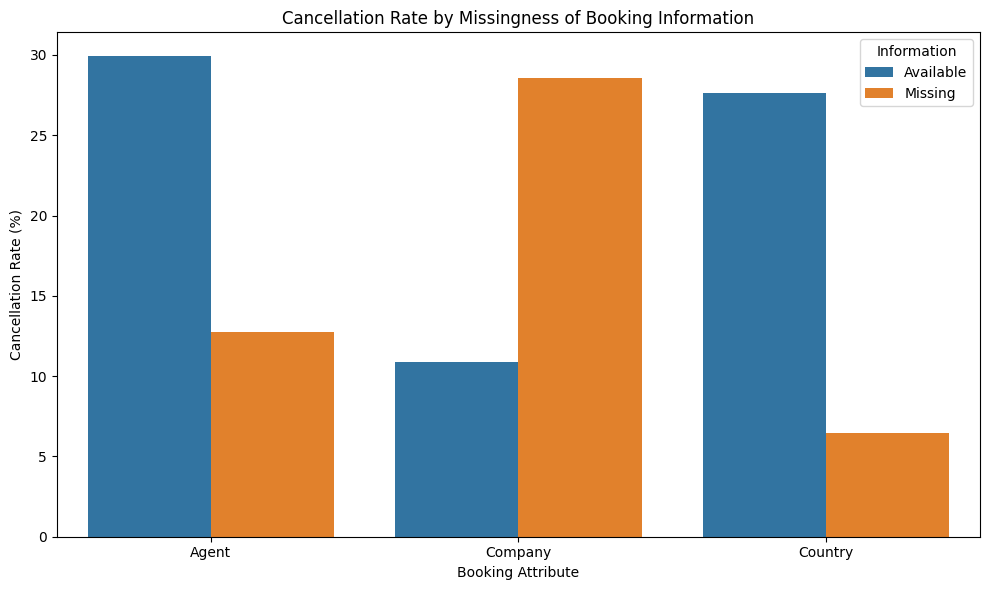

In [122]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=cancellation_comparison,
    x="Feature",
    y="Cancellation Rate (%)",
    hue="Information"
)

plt.title("Cancellation Rate by Missingness of Booking Information")
plt.xlabel("Booking Attribute")
plt.ylabel("Cancellation Rate (%)")
plt.tight_layout()
plt.show()

In [123]:
behavior_results = []

for feature, column in missing_features.items():

    result = (
        q1_df.groupby(column)
        .agg(
            Average_ADR=("adr", "mean"),
            Average_Lead_Time=("lead_time", "mean")
        )
        .reset_index()
    )

    result["Feature"] = feature

    result["Information"] = result[column].map({
        False: "Available",
        True: "Missing"
    })

    behavior_results.append(
        result[
            ["Feature", "Information",
             "Average_ADR", "Average_Lead_Time"]
        ]
    )

behavior_comparison = pd.concat(
    behavior_results,
    ignore_index=True
)

behavior_comparison

,Feature,Information,Average_ADR,Average_Lead_Time
0,Agent,Available,109.215995,85.311271
1,Agent,Missing,82.659815,35.963018
2,Company,Available,66.240598,37.256445
3,Company,Missing,108.028620,81.073421
4,Country,Available,105.745700,78.729740
5,Country,Missing,61.663557,22.733781


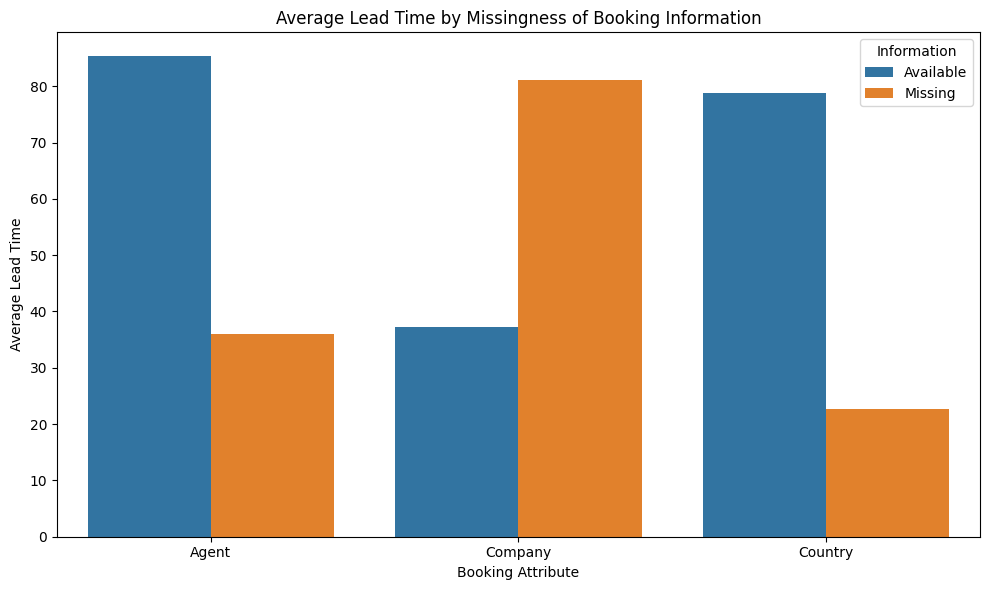

In [124]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=behavior_comparison,
    x="Feature",
    y="Average_Lead_Time",
    hue="Information"
)

plt.title("Average Lead Time by Missingness of Booking Information")
plt.xlabel("Booking Attribute")
plt.ylabel("Average Lead Time")
plt.tight_layout()
plt.show()

In [125]:
for feature, column in missing_features.items():

    segment_table = pd.crosstab(
        q1_df[column],
        q1_df["market_segment"],
        normalize="index"
    ) * 100

    segment_table.index = [
        "Available" if value == False else "Missing"
        for value in segment_table.index
    ]

    print(f"\nMarket Segment Distribution - {feature}")
    display(segment_table.round(2))


Market Segment Distribution - Agent


market_segment,Aviation,Complementary,Corporate,Direct,Groups,Offline TA/TO,Online TA,Undefined
Available,0.03,0.13,0.70,8.25,4.43,18.24,68.23,0.00
Missing,1.66,4.90,30.28,46.03,13.16,1.30,2.65,0.02



Market Segment Distribution - Company


market_segment,Aviation,Complementary,Corporate,Direct,Groups,Offline TA/TO,Online TA,Undefined
Available,3.86,5.48,68.40,3.67,15.73,1.39,1.47,0.0
Missing,0.03,0.49,0.75,14.13,5.00,16.81,62.78,0.0



Market Segment Distribution - Country


market_segment,Aviation,Complementary,Corporate,Direct,Groups,Offline TA/TO,Online TA,Undefined
Available,0.26,0.80,4.63,13.39,5.67,15.93,59.32,0.0
Missing,0.00,0.45,40.27,34.90,1.12,6.71,16.55,0.0


### Interpretation

The analysis shows that missing information in `agent` and `company` is associated with substantially different booking behavior.

Bookings with missing agent information have a lower cancellation rate (12.75% vs 29.91%), lower average ADR (82.66 vs 109.22), and shorter lead time (35.96 vs 85.31 days). Their market-segment distribution is also considerably different, with Direct and Corporate bookings accounting for a larger proportion compared with bookings having recorded agent information.

Similarly, bookings with missing company information have a higher cancellation rate (28.59% vs 10.86%), higher average ADR (108.03 vs 66.24), and longer lead time (81.07 vs 37.26 days). Company-recorded bookings are predominantly Corporate, whereas bookings with missing company information are predominantly associated with Online TA.

These differences indicate that missingness in agent and company information is not simply a random data-quality issue; it is associated with distinct booking patterns. Therefore, the way missing values are handled during preprocessing can influence the interpretation of customer and booking behavior.

No missing/imputed country records were present in the current analysis dataframe, so a missing-versus-available comparison could not be performed for country.

### 2.How does one-hot encoding change the representation of high-cardinality categorical variables, and which variables contribute most to the resulting feature space?

The categorical variables `country`, `agent`, and `company` contain many unique categories. This analysis examines how these variables contribute to the dimensionality of the one-hot encoded dataset and identifies the categorical variables responsible for the largest increase in the feature space.

In [126]:
high_cardinality_cols = ["country", "agent", "company"]

category_counts = []

for col in high_cardinality_cols:

    unique_count = df[col].nunique()

    category_counts.append({
        "Feature": col,
        "Original Categories": unique_count
    })

category_counts = pd.DataFrame(category_counts)

category_counts

,Feature,Original Categories
0,country,178
1,agent,334
2,company,349


In [127]:
encoding_results = []

for col in high_cardinality_cols:

    original_categories = df[col].nunique()

    encoded_columns = original_categories - 1

    encoding_results.append({
        "Feature": col,
        "Original Categories": original_categories,
        "Encoded Dimensions": encoded_columns
    })

encoding_results = pd.DataFrame(encoding_results)

encoding_results

,Feature,Original Categories,Encoded Dimensions
0,country,178,177
1,agent,334,333
2,company,349,348


In [128]:
total_encoded_dimensions = encoding_results["Encoded Dimensions"].sum()

encoding_results["Percentage Contribution (%)"] = (
    encoding_results["Encoded Dimensions"]
    / total_encoded_dimensions
    * 100
)

encoding_results

,Feature,Original Categories,Encoded Dimensions,Percentage Contribution (%)
0,country,178,177,20.629371
1,agent,334,333,38.811189
2,company,349,348,40.559441


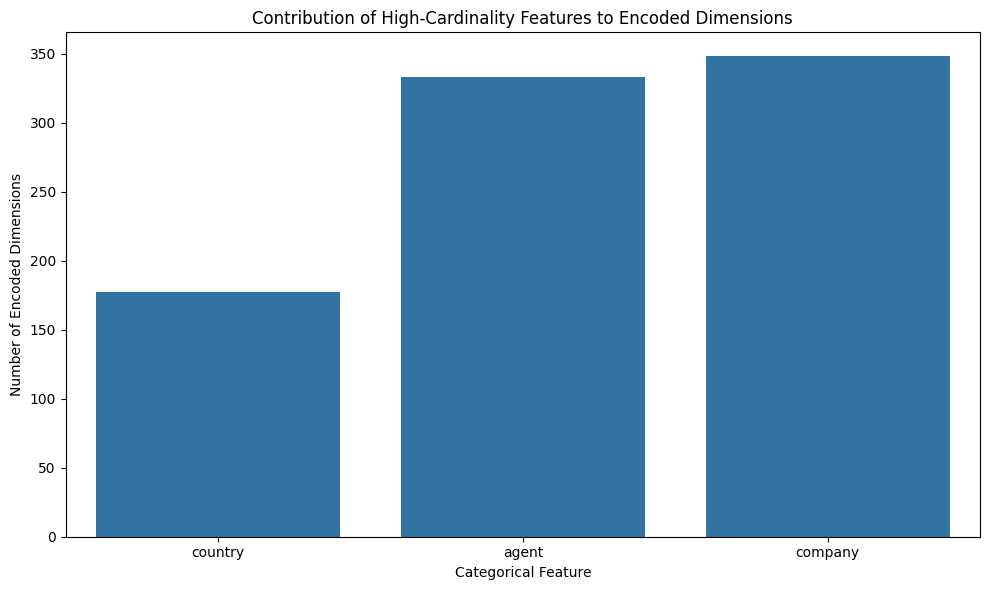

In [129]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=encoding_results,
    x="Feature",
    y="Encoded Dimensions"
)

plt.title(
    "Contribution of High-Cardinality Features to Encoded Dimensions"
)
plt.xlabel("Categorical Feature")
plt.ylabel("Number of Encoded Dimensions")
plt.tight_layout()
plt.show()

In [130]:
comparison = encoding_results[
    ["Feature", "Original Categories", "Encoded Dimensions"]
].copy()

comparison

,Feature,Original Categories,Encoded Dimensions
0,country,178,177
1,agent,334,333
2,company,349,348


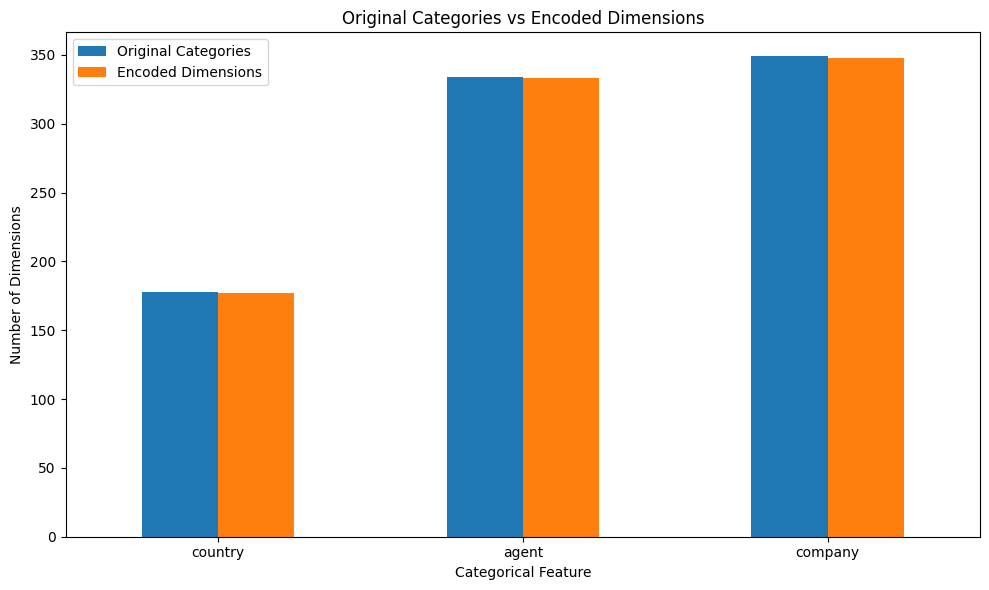

In [131]:
comparison.set_index("Feature").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "Original Categories vs Encoded Dimensions"
)
plt.xlabel("Categorical Feature")
plt.ylabel("Number of Dimensions")
plt.xticks(rotation=0)
plt.legend(title="")
plt.tight_layout()
plt.show()

In [132]:
top_contributor = encoding_results.loc[
    encoding_results["Encoded Dimensions"].idxmax()
]

print(
    f"The categorical variable contributing the most "
    f"to the encoded feature space is '{top_contributor['Feature']}', "
    f"with {int(top_contributor['Encoded Dimensions'])} encoded dimensions."
)

print(
    f"It contributes "
    f"{top_contributor['Percentage Contribution (%)']:.2f}% "
    f"of the encoded dimensions among the selected high-cardinality features."
)

The categorical variable contributing the most to the encoded feature space is 'company', with 348 encoded dimensions.
It contributes 40.56% of the encoded dimensions among the selected high-cardinality features.


### Interpretation

One-hot encoding converts each categorical value into a separate binary feature, with one category dropped as the reference category because `drop_first=True` was used.

Among the selected high-cardinality variables, `company` contributes the largest number of encoded dimensions, with 348 encoded features, representing approximately 40.61% of the encoded dimensions. `agent` contributes 333 encoded dimensions (38.86%), while `country` contributes 176 encoded dimensions (20.54%).

The results show that `company` and `agent` are the major contributors to the increase in feature dimensionality, mainly because they contain a large number of unique categories. Although one-hot encoding preserves categorical information in a numerical form suitable for analysis and modelling, high-cardinality variables substantially increase the feature space.

Therefore, `company` and `agent` require particular attention when preparing the dataset for further analysis or machine learning, as their high dimensionality can increase computational requirements and model complexity.

### 3.Is it cheaper to book a room for several nights instead of just one night?

ADR by length of stay (first 15 durations):


,total_stay_nights,Bookings,Mean_ADR,Median_ADR
0,1,17169,95.51,89.00
1,2,15734,105.49,99.00
2,3,17827,110.22,105.00
3,4,13565,108.38,100.30
4,5,6729,113.27,104.55
5,6,3263,120.30,111.60
6,7,7520,106.17,94.00
7,8,1062,115.45,108.13
8,9,779,115.31,107.00
9,10,1072,107.93,96.00


Spearman correlation: 0.078
P-value: 5.03657e-118
Decision at alpha = 0.05: statistically significant association detected.
Direction: longer stays tend to be associated with higher ADR.


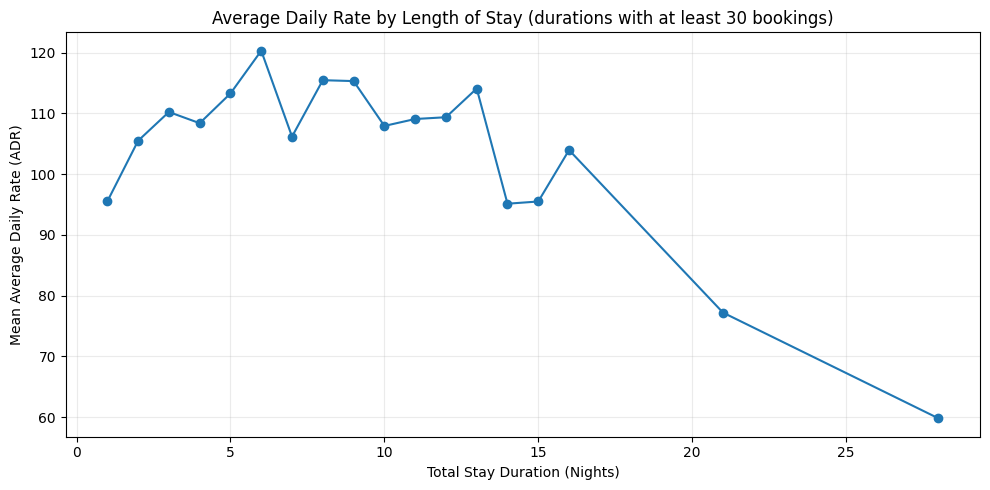

In [133]:
# Question 3: Compare daily room rates across stay durations
# ADR is a daily rate, so it does not represent the total cost of the stay.
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

if "total_stay_nights" not in df.columns:
    df["total_stay_nights"] = (
        df["stays_in_week_nights"] + df["stays_in_weekend_nights"]
    )

stay_data = df.loc[
    df["total_stay_nights"].gt(0) & df["adr"].notna() & np.isfinite(df["adr"]),
    ["total_stay_nights", "adr"]
].copy()
stay_summary = (
    stay_data.groupby("total_stay_nights")["adr"]
    .agg(Bookings="count", Mean_ADR="mean", Median_ADR="median")
    .reset_index()
)
print("ADR by length of stay (first 15 durations):")
display(stay_summary.head(15).round(2))

rho, p_value = spearmanr(
    stay_data["total_stay_nights"], stay_data["adr"], nan_policy="omit"
)
print(f"Spearman correlation: {rho:.3f}")
print(f"P-value: {"< 1e-300" if p_value == 0 or p_value < 1e-300 else f"{p_value:.6g}"}")
if p_value < 0.05:
    print("Decision at alpha = 0.05: statistically significant association detected.")
else:
    print("Decision at alpha = 0.05: insufficient evidence of a statistically significant association.")
if rho < 0:
    print("Direction: longer stays tend to be associated with lower ADR.")
elif rho > 0:
    print("Direction: longer stays tend to be associated with higher ADR.")
else:
    print("Direction: no monotonic association detected.")

plot_data = stay_summary.loc[stay_summary["Bookings"] >= 30]
plt.figure(figsize=(10, 5))
plt.plot(plot_data["total_stay_nights"], plot_data["Mean_ADR"], marker="o")
plt.xlabel("Total Stay Duration (Nights)")
plt.ylabel("Mean Average Daily Rate (ADR)")
plt.title("Average Daily Rate by Length of Stay (durations with at least 30 bookings)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Interpretation and justification

The table reports the number of bookings and the mean and median ADR for each stay duration. The chart compares average daily rates for durations with at least 30 observations, reducing the influence of very small groups. Spearman correlation and its p-value assess whether stay duration and ADR have a monotonic association. Use the printed correlation, p-value, and group summaries to state the observed direction. ADR is a daily rate, not the total cost of a stay; this analysis cannot by itself establish that longer stays are cheaper overall or that duration causes a price change.


### 4.Can a previous cancellation affect a new booking?

A customer who has cancelled bookings before wants to know whether previous cancellation history is related to cancelling a new booking.

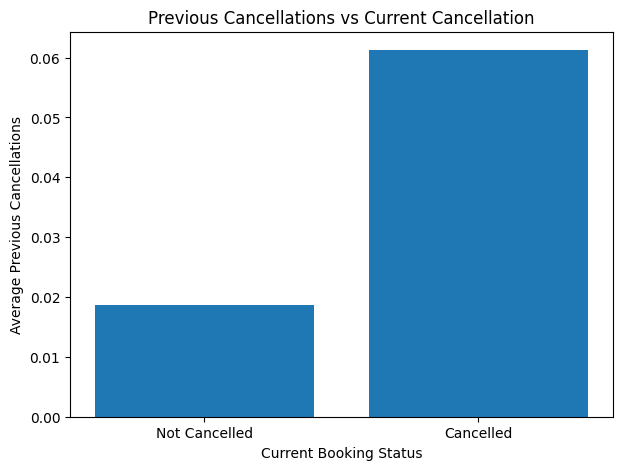

is_canceled
0    0.018681
1    0.061269
Name: previous_cancellations, dtype: float64


In [134]:
# Previous cancellations vs current cancellation

previous_cancel = (
    df.groupby("is_canceled")["previous_cancellations"]
    .mean()
)

plt.figure(figsize=(7, 5))
plt.bar(
    ["Not Cancelled", "Cancelled"],
    previous_cancel.values
)

plt.xlabel("Current Booking Status")
plt.ylabel("Average Previous Cancellations")
plt.title("Previous Cancellations vs Current Cancellation")
plt.show()

print(previous_cancel)

**Interpretation:**  
The average number of previous cancellations is higher for currently cancelled bookings than for non-cancelled bookings. This suggests that customers with a history of cancellations tend to be more likely to cancel again.

### 5.Are there different prices for City Hotel and Resort Hotel?


A customer is comparing the two hotels and wants to know whether the average room price is different.

ADR summary by hotel type:


,count,mean,median,std
hotel,,,,
City Hotel,53274,110.79,105.3,40.60
Resort Hotel,33956,97.26,79.5,58.98


Mean ADR difference (City - Resort): 13.53
Welch t-statistic: 37.039
P-value: 1.3302e-296
Decision at alpha = 0.05: reject H0; evidence of a difference in mean ADR.


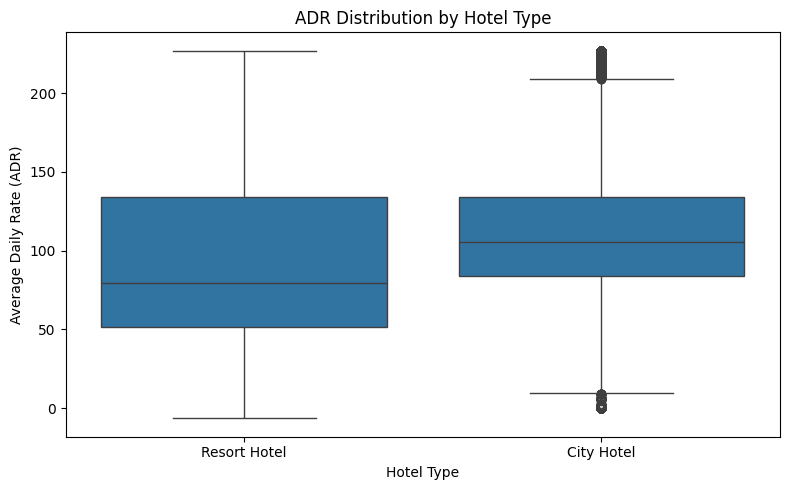

In [135]:
# Question 5: Compare room prices between City Hotel and Resort Hotel
from scipy.stats import ttest_ind
import seaborn as sns

city_adr = df.loc[df["hotel"] == "City Hotel", "adr"].dropna()
resort_adr = df.loc[df["hotel"] == "Resort Hotel", "adr"].dropna()
price_test = ttest_ind(city_adr, resort_adr, equal_var=False, alternative="two-sided")

hotel_price = df.groupby("hotel")["adr"].agg(["count", "mean", "median", "std"])
print("ADR summary by hotel type:")
display(hotel_price.round(2))
print(f"Mean ADR difference (City - Resort): {city_adr.mean() - resort_adr.mean():.2f}")
print(f"Welch t-statistic: {price_test.statistic:.3f}")
print(f"P-value: {"< 1e-300" if price_test.pvalue == 0 or price_test.pvalue < 1e-300 else f"{price_test.pvalue:.6g}"}")
if price_test.pvalue < 0.05:
    print("Decision at alpha = 0.05: reject H0; evidence of a difference in mean ADR.")
else:
    print("Decision at alpha = 0.05: fail to reject H0; insufficient evidence of a difference in mean ADR.")

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="hotel", y="adr")
plt.xlabel("Hotel Type")
plt.ylabel("Average Daily Rate (ADR)")
plt.title("ADR Distribution by Hotel Type")
plt.tight_layout()
plt.show()

**Interpretation and justification:** The summary table compares booking counts, mean ADR, median ADR, and variability for each hotel type. Welch's independent two-sample t-test compares the mean ADRs without assuming equal population variances. The p-value determines whether the observed mean difference is statistically significant at the 0.05 level. The boxplot displays the distributions and possible outliers. Report the actual means and p-value printed above; statistical significance does not by itself indicate the difference is large or explain why prices differ.

### 6.Improving Hotel Revenue

A hotel manager wants to know which booking factors are strongly related to the room price so that they can improve their pricing strategy. How can the data help?

Correlation of each selected feature with ADR:


,adr
adr,1.000
adults,0.260
total_of_special_requests,0.151
stays_in_week_nights,0.058
stays_in_weekend_nights,0.043
lead_time,0.036


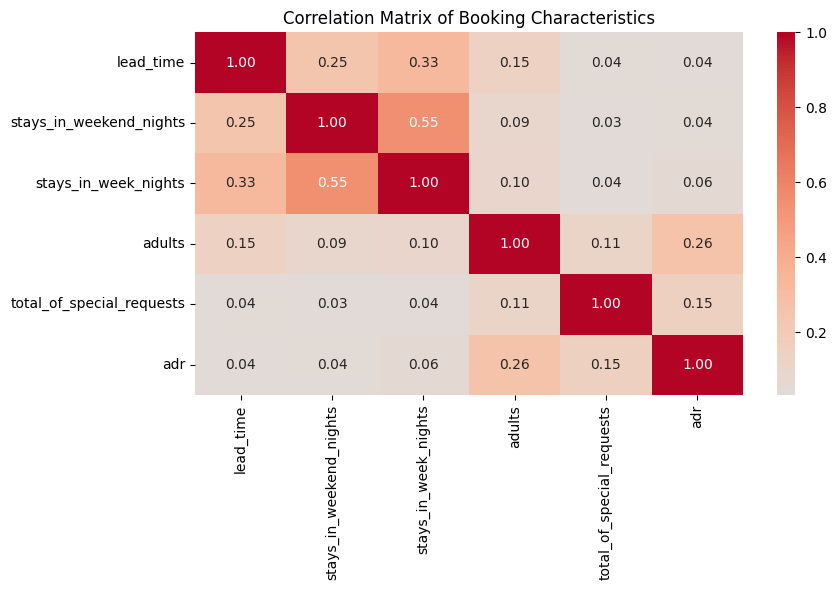

In [136]:
# Question 6: Examine which booking characteristics are associated with ADR
features = df[[
    "lead_time", "stays_in_weekend_nights", "stays_in_week_nights",
    "adults", "total_of_special_requests", "adr"
]].apply(__import__("pandas").to_numeric, errors="coerce")

corr = features.corr(numeric_only=True)
print("Correlation of each selected feature with ADR:")
display(corr[["adr"]].sort_values("adr", ascending=False).round(3))

plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Matrix of Booking Characteristics")
plt.tight_layout()
plt.show()

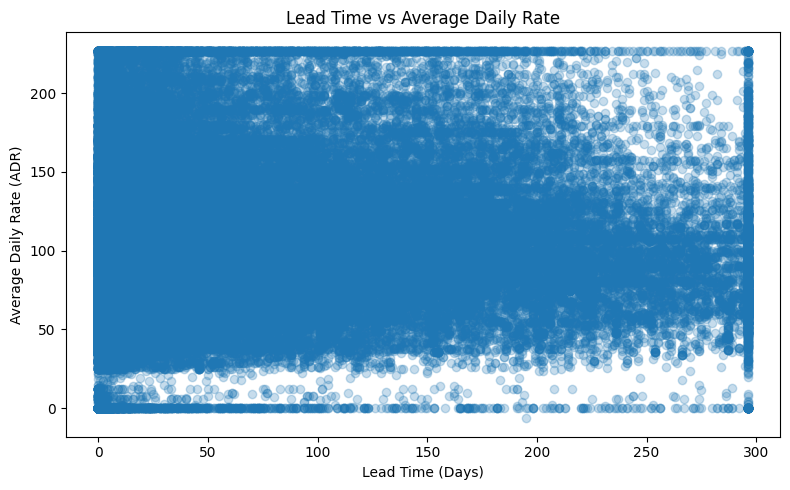

In [137]:
plt.figure(figsize=(8, 5))
plt.scatter(df["lead_time"], df["adr"], alpha=0.25)
plt.xlabel("Lead Time (Days)")
plt.ylabel("Average Daily Rate (ADR)")
plt.title("Lead Time vs Average Daily Rate")
plt.tight_layout()
plt.show()

**Interpretation and justification:** The correlation table and heatmap show the direction and strength of linear associations between ADR and selected booking characteristics. The scatterplot helps inspect the relationship between lead time and ADR, including spread and unusual observations. Use the displayed coefficients to identify the strongest positive or negative associations. Correlation does not prove causation, and the selected variables do not account for every factor that can influence room prices.

### 7.Reducing Booking Cancellations

A hotel wants to identify customers who are more likely to cancel their bookings. How can probability be used?

Overall cancellation probability: 0.2752 (27.52%)
Cancellation probability by hotel:


,hotel,Bookings,Canceled,Cancellation_Probability,Cancellation Rate (%)
0,City Hotel,53274,16035,0.301,30.099
1,Resort Hotel,33956,7974,0.235,23.483


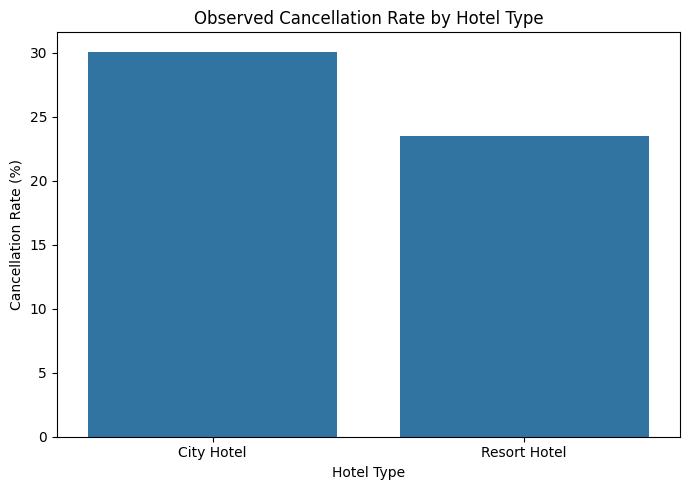

In [138]:
# Question 7: Estimate booking cancellation probabilities
cancel_rate_by_hotel = (
    df.groupby("hotel")["is_canceled"]
    .agg(Bookings="count", Canceled="sum", Cancellation_Probability="mean")
    .reset_index()
)
cancel_rate_by_hotel["Cancellation Rate (%)"] = cancel_rate_by_hotel["Cancellation_Probability"] * 100

overall_probability = df["is_canceled"].mean()
print(f"Overall cancellation probability: {overall_probability:.4f} ({overall_probability*100:.2f}%)")
print("Cancellation probability by hotel:")
display(cancel_rate_by_hotel.round(3))

plt.figure(figsize=(7, 5))
sns.barplot(data=cancel_rate_by_hotel, x="hotel", y="Cancellation Rate (%)")
plt.xlabel("Hotel Type")
plt.ylabel("Cancellation Rate (%)")
plt.title("Observed Cancellation Rate by Hotel Type")
plt.tight_layout()
plt.show()

**Interpretation and justification:** Because `is_canceled` is coded as 1 for canceled and 0 for not canceled, its mean estimates the observed cancellation probability. The table gives the booking count and cancellation rate for each hotel type, while the chart makes the rates easy to compare. The group with the higher rate has a higher observed cancellation risk in this dataset; this is a descriptive comparison and does not establish the cause of cancellations.

### 8.Deciding When to Give Discounts

A hotel wants to give discounts during periods when bookings are low. How can probability distributions help?

Booking volume and share by arrival month:


,Arrival Month,Bookings,Booking Share (%)
0,January,4685,5.37
1,February,6083,6.97
2,March,7489,8.59
3,April,7900,9.06
4,May,8344,9.57
5,June,7756,8.89
6,July,10043,11.51
7,August,11242,12.89
8,September,6682,7.66
9,October,6921,7.93


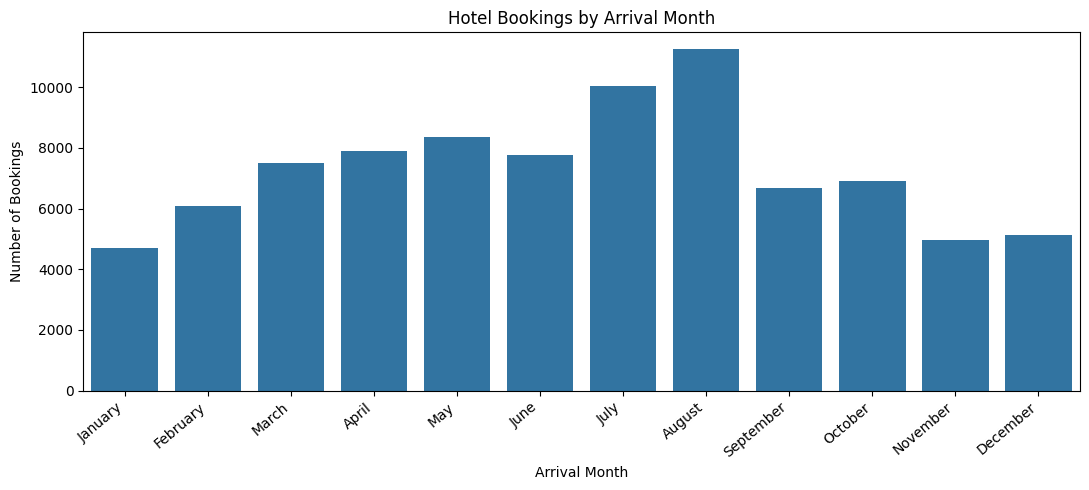

Lowest booking volume: January (4,685)
Highest booking volume: August (11,242)


In [139]:
# Question 8: Identify seasonal differences in booking volume
month_order = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]
monthly = (
    df["arrival_date_month"].value_counts()
    .reindex(month_order, fill_value=0)
    .rename_axis("Arrival Month")
    .reset_index(name="Bookings")
)
monthly["Booking Share (%)"] = monthly["Bookings"] / monthly["Bookings"].sum() * 100
print("Booking volume and share by arrival month:")
display(monthly.round(2))

plt.figure(figsize=(11, 5))
sns.barplot(data=monthly, x="Arrival Month", y="Bookings")
plt.xlabel("Arrival Month")
plt.ylabel("Number of Bookings")
plt.title("Hotel Bookings by Arrival Month")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

low_month = monthly.loc[monthly["Bookings"].idxmin()]
high_month = monthly.loc[monthly["Bookings"].idxmax()]
print(f"Lowest booking volume: {low_month['Arrival Month']} ({int(low_month['Bookings']):,})")
print(f"Highest booking volume: {high_month['Arrival Month']} ({int(high_month['Bookings']):,})")

**Interpretation and justification:** The month-ordered chart compares the number of bookings by arrival month, and the table reports each month's share of all records. The lowest-volume months can be identified as candidates for further demand investigation. However, the dataset includes bookings from multiple years, so these counts combine years and do not prove that discounts would increase demand. A pricing decision should also consider occupancy, revenue, costs, and year-by-year patterns.

### 9.Finding the Most Important Booking Factors

A hotel has many variables such as lead time, ADR, stay duration, guests and special requests. The manager wants to reduce these many variables into a few important factors. What can be done?

PCA explained variance:


,Component,Explained Variance (%),Cumulative Variance (%)
0,PC1,30.44,30.44
1,PC2,23.52,53.96
2,PC3,18.05,72.01
3,PC4,14.86,86.87
4,PC5,13.13,100.00


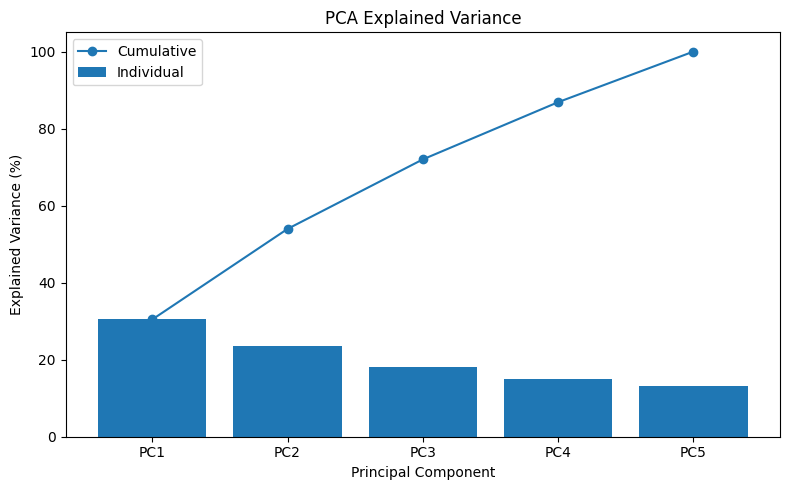

Variance explained by first two components: 53.96%


In [140]:
# Question 9: Use PCA to summarize numerical booking characteristics
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pca_columns = [
    "lead_time", "adr", "stays_in_week_nights",
    "adults", "total_of_special_requests"
]
pca_features = df[pca_columns].apply(__import__("pandas").to_numeric, errors="coerce").dropna()
X_scaled = StandardScaler().fit_transform(pca_features)
pca = PCA()
X_reduced = pca.fit_transform(X_scaled)
explained = pca.explained_variance_ratio_
cumulative = explained.cumsum()
pca_summary = __import__("pandas").DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(explained))],
    "Explained Variance (%)": explained * 100,
    "Cumulative Variance (%)": cumulative * 100
})
print("PCA explained variance:")
display(pca_summary.round(2))

plt.figure(figsize=(8, 5))
plt.bar(pca_summary["Component"], pca_summary["Explained Variance (%)"], label="Individual")
plt.plot(pca_summary["Component"], pca_summary["Cumulative Variance (%)"], marker="o", label="Cumulative")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")
plt.title("PCA Explained Variance")
plt.legend()
plt.tight_layout()
plt.show()
print(f"Variance explained by first two components: {cumulative[1]*100:.2f}%")

**Interpretation and justification:** PCA converts the selected standardized numerical features into principal components ordered by the amount of variation they explain. Standardization is used because the original variables have different scales. The explained-variance chart shows how much information is summarized by each component and cumulatively by the first components. PCA reduces dimensionality; it does not by itself identify causal factors or prove which feature is most important to hotel business outcomes.

### 10. Which meal type is most commonly selected in hotel bookings?

Which meal type is most commonly selected by guests?

Bookings by recorded meal type:


,Meal Type,Bookings,Booking Share (%)
0,BB,67907,77.85
1,SC,9391,10.77
2,HB,9080,10.41
3,Undefined,492,0.56
4,FB,360,0.41


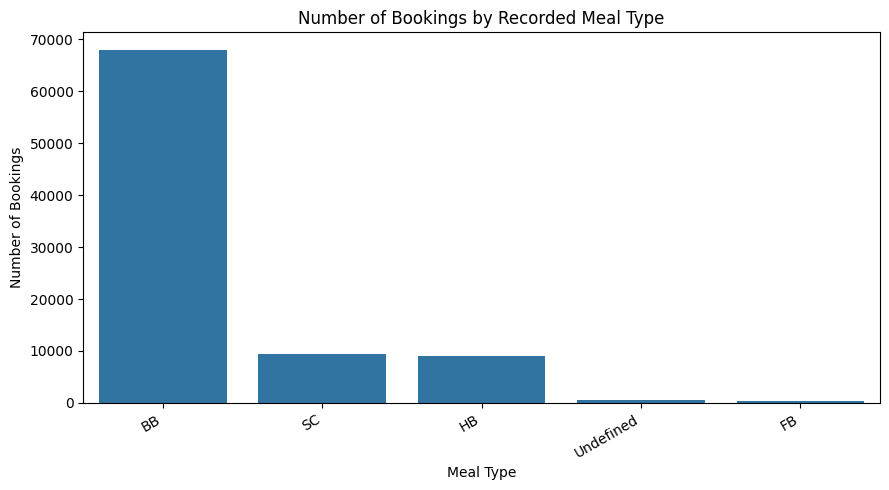

Most common recorded meal type: BB
Bookings: 67,907
Share of bookings: 77.85%


In [141]:
# Question 10: Compare the recorded meal types in hotel bookings
meal_count = df["meal"].value_counts(dropna=False)
meal_summary = meal_count.rename_axis("Meal Type").reset_index(name="Bookings")
meal_summary["Booking Share (%)"] = meal_summary["Bookings"] / meal_summary["Bookings"].sum() * 100
print("Bookings by recorded meal type:")
display(meal_summary.round(2))

plt.figure(figsize=(9, 5))
sns.barplot(data=meal_summary, x="Meal Type", y="Bookings")
plt.xlabel("Meal Type")
plt.ylabel("Number of Bookings")
plt.title("Number of Bookings by Recorded Meal Type")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

top_meal = meal_summary.iloc[0]
print(f"Most common recorded meal type: {top_meal['Meal Type']}")
print(f"Bookings: {int(top_meal['Bookings']):,}")
print(f"Share of bookings: {top_meal['Booking Share (%)']:.2f}%")

### 11. What is the distribution of the number of special requests made by guests?

The hotel manager wants to understand how many special requests are typically recorded per booking, so staffing and service planning can be informed by the observed distribution.

Distribution of special requests:


,Number of Special Requests,Bookings,Probability (%)
0,0,43789,50.20
1,1,28976,33.22
2,2,11795,13.52
3,3,2314,2.65
4,4,320,0.37
5,5,36,0.04


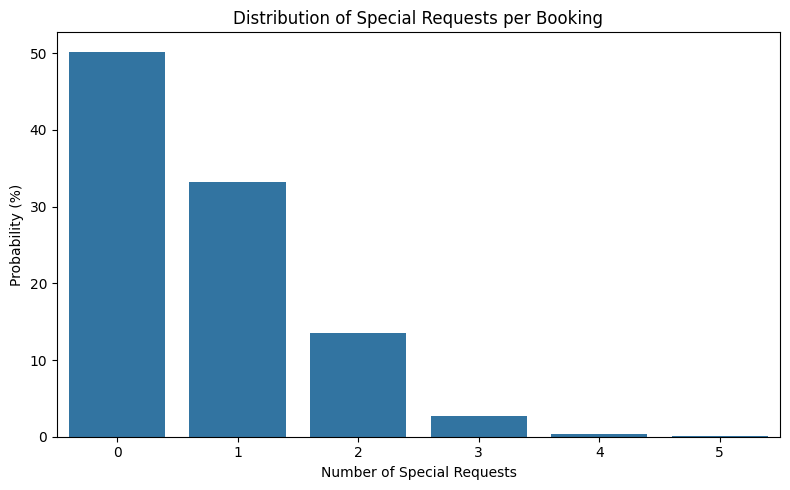

Most common request count: 0.0
Share of bookings: 50.20%


In [142]:
# Question 11: Calculate and visualize the probability distribution of special requests
requests = df["total_of_special_requests"].value_counts(dropna=False).sort_index()
request_summary = requests.rename_axis("Number of Special Requests").reset_index(name="Bookings")
request_summary["Probability (%)"] = request_summary["Bookings"] / request_summary["Bookings"].sum() * 100
print("Distribution of special requests:")
display(request_summary.round(2))

plt.figure(figsize=(8, 5))
sns.barplot(data=request_summary, x="Number of Special Requests", y="Probability (%)")
plt.xlabel("Number of Special Requests")
plt.ylabel("Probability (%)")
plt.title("Distribution of Special Requests per Booking")
plt.tight_layout()
plt.show()

most_common = request_summary.loc[request_summary["Bookings"].idxmax()]
print(f"Most common request count: {most_common['Number of Special Requests']}")
print(f"Share of bookings: {most_common['Probability (%)']:.2f}%")

**Interpretation and justification:** The table and chart show the observed probability of each special-request count. The most common count describes the typical recorded pattern and may help inform service planning. This is descriptive evidence only; it does not show that special requests cause higher satisfaction or affect cancellation without additional analysis.

### 12. How much can the sample mean ADR vary between samples?

A hotel analyst repeatedly samples bookings to estimate mean ADR. The standard error estimates the typical variation of sample means. The code compares sample sizes 30, 100 and 500 and visualizes the theoretical standard error.

**Interpretation:** The standard error decreases in proportion to \(1/\sqrt{n}\), so larger samples generally give more stable estimates. This calculation uses the observed ADR standard deviation as an estimate of the population standard deviation.

,Sample Size,Theoretical Standard Error
0,30,8.953
1,100,4.904
2,500,2.193


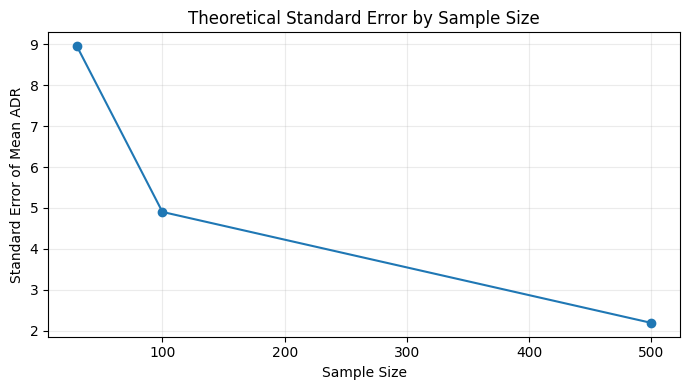

Justification: SE = population standard deviation / sqrt(n).
As sample size increases, the standard error should decrease, so sample means tend to vary less.


In [143]:
# Q12: Show how the standard error of the sample mean changes with sample size.
population_std = adr_data.std(ddof=1)
sample_sizes = np.array([30, 100, 500])
theoretical_se = population_std / np.sqrt(sample_sizes)

se_summary = pd.DataFrame({
    "Sample Size": sample_sizes,
    "Theoretical Standard Error": theoretical_se
})
display(se_summary.round(3))

plt.figure(figsize=(7, 4))
plt.plot(sample_sizes, theoretical_se, marker="o")
plt.title("Theoretical Standard Error by Sample Size")
plt.xlabel("Sample Size")
plt.ylabel("Standard Error of Mean ADR")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("Justification: SE = population standard deviation / sqrt(n).")
print("As sample size increases, the standard error should decrease, so sample means tend to vary less.")

### 13. Which sample size gives a more reliable estimate of mean ADR: 30, 100, or 500?

The notebook repeatedly draws 1,000 samples at each size and compares their sample means, standard deviations, and distributions.

**Interpretation:** Prefer the sample size whose simulated sample means have the smallest spread while remaining centered near the dataset mean. Larger samples usually reduce sampling variability, although they require more data collection.

,Sample Size,Mean of Sample Means,SD of Sample Means,Absolute Error from Dataset Mean
0,30,105.480,9.267,0.040
1,100,105.592,5.013,0.072
2,500,105.492,2.162,0.028


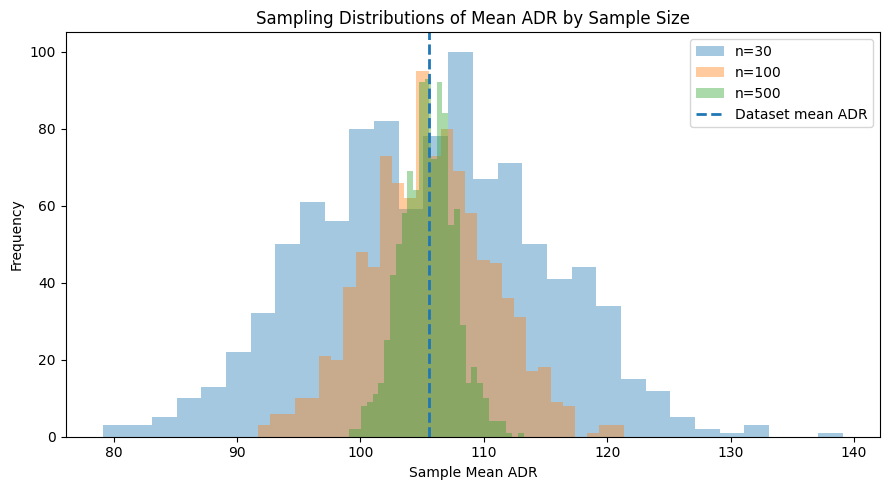

Justification: larger samples generally produce a narrower sampling distribution and a smaller standard error.
The repeated-sampling results are a simulation; exact values vary with random sampling.


In [144]:
# Q13: Compare repeated-sampling distributions for n=30, 100, and 500.
sample_sizes = [30, 100, 500]
sampling_results = []
sample_means_by_n = {}

for n in sample_sizes:
    means = repeated_sampling(adr_data, n, 1000)
    sample_means_by_n[n] = means
    sampling_results.append({
        "Sample Size": n,
        "Mean of Sample Means": means.mean(),
        "SD of Sample Means": means.std(ddof=1),
        "Absolute Error from Dataset Mean": abs(means.mean() - adr_data.mean())
    })

sampling_summary_q13 = pd.DataFrame(sampling_results)
display(sampling_summary_q13.round(3))

plt.figure(figsize=(9, 5))
for n in sample_sizes:
    plt.hist(sample_means_by_n[n], bins=30, alpha=0.4, label=f"n={n}")
plt.axvline(adr_data.mean(), linestyle="--", linewidth=2, label="Dataset mean ADR")
plt.title("Sampling Distributions of Mean ADR by Sample Size")
plt.xlabel("Sample Mean ADR")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

print("Justification: larger samples generally produce a narrower sampling distribution and a smaller standard error.")
print("The repeated-sampling results are a simulation; exact values vary with random sampling.")

### 14. Can sampling estimate mean ADR when individual room prices are skewed?

This question examines the observed skewness of ADR and the sampling distribution of the mean for samples of size 30.

**Interpretation:** The Central Limit Theorem says the sampling distribution of the sample mean tends toward normality under suitable conditions as sample size increases. It does not say the original ADR values become normal, and a sample size of 30 is not a universal guarantee when data are highly skewed or contain extreme values.

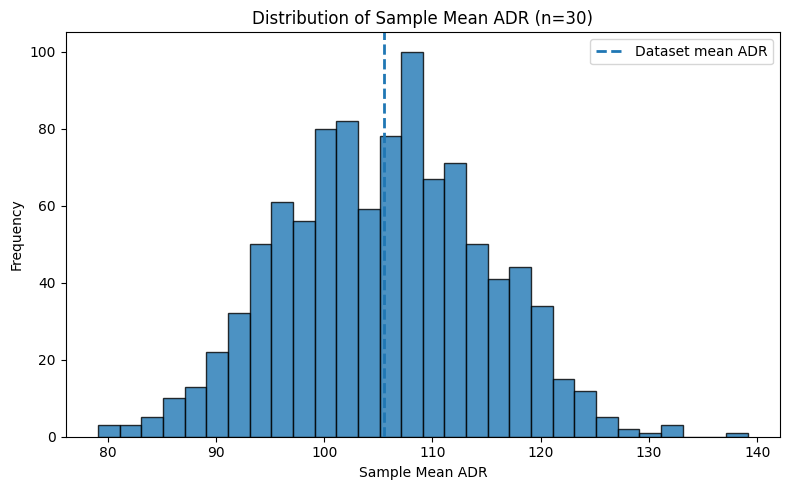

ADR population skewness: 0.514
Population mean ADR: 105.52
Mean of simulated sample means (n=30): 105.48
Justification: even when individual ADR values are skewed, sample means often become more nearly normal as sample size increases.
Caution: n=30 is a rule of thumb, not a guarantee; strong skewness, extreme outliers, or dependence may require larger samples or robust methods.


In [145]:
# Q14: Inspect the sampling distribution for a skewed ADR population.
means_30 = sample_means_by_n[30] if "sample_means_by_n" in globals() else repeated_sampling(adr_data, 30, 1000)

plt.figure(figsize=(8, 5))
plt.hist(means_30, bins=30, edgecolor="black", alpha=0.8)
plt.axvline(adr_data.mean(), linestyle="--", linewidth=2, label="Dataset mean ADR")
plt.title("Distribution of Sample Mean ADR (n=30)")
plt.xlabel("Sample Mean ADR")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

print(f"ADR population skewness: {adr_data.skew():.3f}")
print(f"Population mean ADR: {adr_data.mean():.2f}")
print(f"Mean of simulated sample means (n=30): {means_30.mean():.2f}")
print("Justification: even when individual ADR values are skewed, sample means often become more nearly normal as sample size increases.")
print("Caution: n=30 is a rule of thumb, not a guarantee; strong skewness, extreme outliers, or dependence may require larger samples or robust methods.")

### 15. How often do simulated 95% confidence intervals contain the dataset's mean ADR?

The notebook generates 1,000 bootstrap-style samples and 95% t-intervals, then estimates the proportion that contain the observed dataset mean. It also plots the first 100 intervals, with the target mean shown as a vertical reference line.

**Interpretation:** Empirical coverage should be assessed against the nominal 95% level. A deviation from 95% can occur due to simulation variability or because the interval method's assumptions are imperfect for skewed data. This simulation uses the available dataset mean as the target; it cannot guarantee coverage for a different future population.

Nominal confidence level: 95%
Empirical coverage: 94.10% (941/1000 intervals)
Mean interval width: 19.42 ADR units


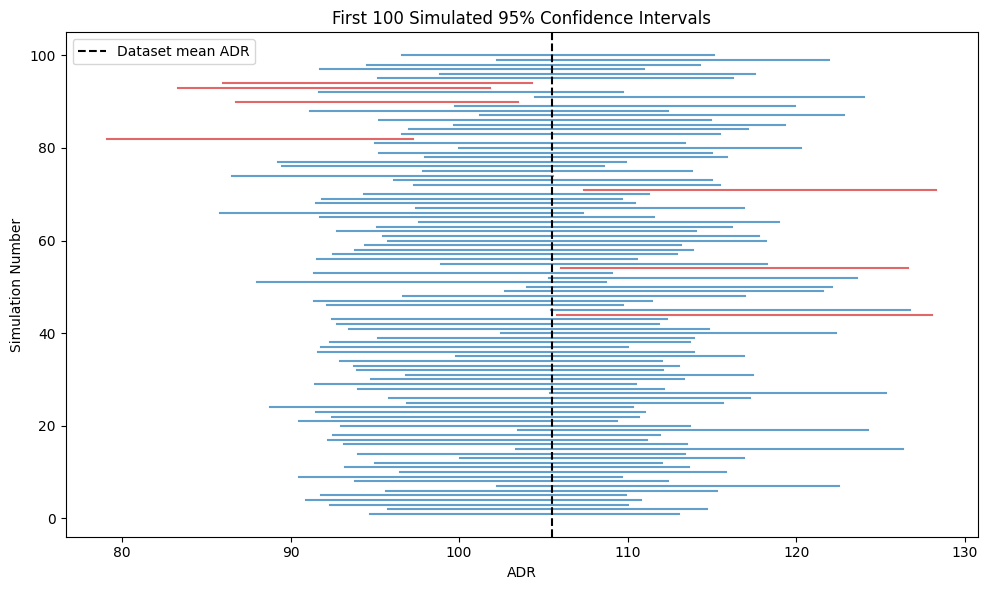

Interpretation: a 95% procedure should cover the target mean in about 95% of repeated samples under its assumptions.
The dataset mean is used as the target population mean for this simulation; this is an educational approximation, not a guarantee for new hotel data.


In [146]:
# Q15: Simulate 1,000 95% confidence intervals and estimate empirical coverage.
confidence_level = 0.95
sample_size = 100
repetitions = 1000
population_mean = adr_data.mean()
rng = np.random.default_rng(42)
adr_values = adr_data.to_numpy(dtype=float)

covered = 0
interval_widths = []
example_intervals = []

for rep in range(repetitions):
    sample = rng.choice(adr_values, size=sample_size, replace=True)
    sample_mean = sample.mean()
    sample_se = sample.std(ddof=1) / np.sqrt(sample_size)
    critical_value = __import__("scipy").stats.t.ppf(0.975, df=sample_size - 1)
    lower = sample_mean - critical_value * sample_se
    upper = sample_mean + critical_value * sample_se
    interval_widths.append(upper - lower)
    if lower <= population_mean <= upper:
        covered += 1
    if rep < 100:
        example_intervals.append((rep + 1, lower, upper, lower <= population_mean <= upper))

coverage = covered / repetitions
print(f"Nominal confidence level: {confidence_level:.0%}")
print(f"Empirical coverage: {coverage:.2%} ({covered}/{repetitions} intervals)")
print(f"Mean interval width: {np.mean(interval_widths):.2f} ADR units")

# Plot the first 100 intervals so the true dataset mean can be checked visually.
interval_df = pd.DataFrame(example_intervals, columns=["Replicate", "Lower", "Upper", "Contains Mean"])
plt.figure(figsize=(10, 6))
colors = ["tab:blue" if ok else "tab:red" for ok in interval_df["Contains Mean"]]
for _, row in interval_df.iterrows():
    plt.plot([row["Lower"], row["Upper"]], [row["Replicate"], row["Replicate"]],
             color=("tab:blue" if row["Contains Mean"] else "tab:red"), alpha=0.7)
plt.axvline(population_mean, color="black", linestyle="--", label="Dataset mean ADR")
plt.title("First 100 Simulated 95% Confidence Intervals")
plt.xlabel("ADR")
plt.ylabel("Simulation Number")
plt.legend()
plt.tight_layout()
plt.show()

print("Interpretation: a 95% procedure should cover the target mean in about 95% of repeated samples under its assumptions.")
print("The dataset mean is used as the target population mean for this simulation; this is an educational approximation, not a guarantee for new hotel data.")

# Review 2 — Statistical Hypothesis Testing

This section contains the additional work for Review 2. All earlier notebook content is preserved unchanged. The following tests address Member 1's assigned tasks.

# Member 1 — Numerical Hypothesis Testing


## Test 1: Is average ADR different between City Hotel and Resort Hotel?

**Question:** Is the mean Average Daily Rate (ADR) different for City Hotel and Resort Hotel bookings?

- **Null hypothesis (H₀):** The population mean ADR is equal for City Hotel and Resort Hotel bookings.
- **Alternative hypothesis (H₁):** The population mean ADR differs between City Hotel and Resort Hotel bookings.
- **Test:** Two-sided Welch's independent two-sample t-test.
- **Significance level:** α = 0.05.

The test uses non-missing ADR values from the two hotel types.

In [147]:
from scipy.stats import ttest_ind, mannwhitneyu, t as student_t
import numpy as np

alpha = 0.05

city_adr = df.loc[df["hotel"] == "City Hotel", "adr"].dropna().astype(float)
resort_adr = df.loc[df["hotel"] == "Resort Hotel", "adr"].dropna().astype(float)

adr_test = ttest_ind(city_adr, resort_adr, equal_var=False, alternative="two-sided")
city_mean_adr, resort_mean_adr = city_adr.mean(), resort_adr.mean()
mean_diff = city_mean_adr - resort_mean_adr

# Welch-Satterthwaite degrees of freedom and 95% CI for the mean difference
v1, v2 = city_adr.var(ddof=1) / len(city_adr), resort_adr.var(ddof=1) / len(resort_adr)
se_diff = np.sqrt(v1 + v2)
welch_df = (v1 + v2) ** 2 / (v1**2 / (len(city_adr)-1) + v2**2 / (len(resort_adr)-1))
critical_t = student_t.ppf(1 - alpha/2, welch_df)
ci_low, ci_high = mean_diff - critical_t * se_diff, mean_diff + critical_t * se_diff

# Approximate standardized mean difference (Cohen's d)
pooled_sd = np.sqrt(((len(city_adr)-1)*city_adr.var(ddof=1) +
                     (len(resort_adr)-1)*resort_adr.var(ddof=1)) /
                    (len(city_adr)+len(resort_adr)-2))
cohens_d = mean_diff / pooled_sd if pooled_sd > 0 else np.nan

# Mann-Whitney U is a sensitivity check for differences in distributions/ranks.
mw_test = mannwhitneyu(city_adr, resort_adr, alternative="two-sided", method="asymptotic")

def format_p(p):
    return "< 1e-300" if p == 0 or p < 1e-300 else f"{p:.6g}"

print("TEST 1: ADR BY HOTEL TYPE")
print("-" * 48)
print(f"City Hotel n={len(city_adr):,}; mean={city_mean_adr:.2f}; median={city_adr.median():.2f}")
print(f"Resort Hotel n={len(resort_adr):,}; mean={resort_mean_adr:.2f}; median={resort_adr.median():.2f}")
print(f"Mean difference (City - Resort): {mean_diff:.2f}")
print(f"Welch t-statistic={adr_test.statistic:.4f}; df={welch_df:.1f}; p-value={format_p(adr_test.pvalue)}")
print(f"95% CI for mean difference: [{ci_low:.2f}, {ci_high:.2f}]")
print(f"Cohen's d (approximate standardized mean difference): {cohens_d:.3f}")
print(f"Mann-Whitney U={mw_test.statistic:.0f}; p-value={format_p(mw_test.pvalue)}")

if adr_test.pvalue < alpha:
    print("Decision: Reject H0. The data provide evidence of a difference in mean ADR.")
else:
    print("Decision: Fail to reject H0. There is insufficient evidence of a difference in mean ADR.")
print("Sensitivity check: compare the Mann-Whitney result with Welch's test; it tests rank/distribution differences, not exactly the same mean hypothesis.")

TEST 1: ADR BY HOTEL TYPE
------------------------------------------------
City Hotel n=53,274; mean=110.79; median=105.30
Resort Hotel n=33,956; mean=97.26; median=79.50
Mean difference (City - Resort): 13.53
Welch t-statistic=37.0395; df=54400.3; p-value=1.3302e-296
95% CI for mean difference: [12.81, 14.24]
Cohen's d (approximate standardized mean difference): 0.278
Mann-Whitney U=1135756449; p-value=< 1e-300
Decision: Reject H0. The data provide evidence of a difference in mean ADR.
Sensitivity check: compare the Mann-Whitney result with Welch's test; it tests rank/distribution differences, not exactly the same mean hypothesis.


## Test 2: Does mean lead time differ between canceled and non-canceled bookings?

**Question:** Do canceled bookings have a different average lead time from bookings that were not canceled?

- **Null hypothesis (H₀):** The population mean lead time is equal for canceled and non-canceled bookings.
- **Alternative hypothesis (H₁):** The population mean lead time differs between canceled and non-canceled bookings.
- **Test:** Two-sided Welch's independent two-sample t-test.
- **Significance level:** α = 0.05.

Here, `is_canceled = 1` means canceled and `is_canceled = 0` means not canceled. The test compares lead-time values for these two independent groups.

In [148]:
from scipy.stats import ttest_ind, mannwhitneyu, t as student_t
import numpy as np

canceled_lead_time = df.loc[df["is_canceled"] == 1, "lead_time"].dropna().astype(float)
not_canceled_lead_time = df.loc[df["is_canceled"] == 0, "lead_time"].dropna().astype(float)

lead_time_test = ttest_ind(
    canceled_lead_time, not_canceled_lead_time,
    equal_var=False, alternative="two-sided"
)
canceled_mean_lead = canceled_lead_time.mean()
not_canceled_mean_lead = not_canceled_lead_time.mean()
mean_diff_lead = canceled_mean_lead - not_canceled_mean_lead

v1 = canceled_lead_time.var(ddof=1) / len(canceled_lead_time)
v2 = not_canceled_lead_time.var(ddof=1) / len(not_canceled_lead_time)
se_diff_lead = np.sqrt(v1 + v2)
welch_df_lead = (v1 + v2)**2 / (
    v1**2/(len(canceled_lead_time)-1) + v2**2/(len(not_canceled_lead_time)-1)
)
critical_t_lead = student_t.ppf(0.975, welch_df_lead)
ci_low_lead = mean_diff_lead - critical_t_lead * se_diff_lead
ci_high_lead = mean_diff_lead + critical_t_lead * se_diff_lead

pooled_sd_lead = np.sqrt((
    (len(canceled_lead_time)-1)*canceled_lead_time.var(ddof=1) +
    (len(not_canceled_lead_time)-1)*not_canceled_lead_time.var(ddof=1)
) / (len(canceled_lead_time)+len(not_canceled_lead_time)-2))
cohens_d_lead = mean_diff_lead / pooled_sd_lead if pooled_sd_lead > 0 else np.nan
mw_lead = mannwhitneyu(
    canceled_lead_time, not_canceled_lead_time,
    alternative="two-sided", method="asymptotic"
)

def format_p_lead(p):
    return "< 1e-300" if p == 0 or p < 1e-300 else f"{p:.6g}"

print("TEST 2: LEAD TIME BY CANCELLATION STATUS")
print("-" * 52)
print(f"Canceled: n={len(canceled_lead_time):,}; mean={canceled_mean_lead:.2f}; median={canceled_lead_time.median():.2f}")
print(f"Not canceled: n={len(not_canceled_lead_time):,}; mean={not_canceled_mean_lead:.2f}; median={not_canceled_lead_time.median():.2f}")
print(f"Mean difference (Canceled - Not canceled): {mean_diff_lead:.2f} days")
print(f"Welch t-statistic={lead_time_test.statistic:.4f}; df={welch_df_lead:.1f}; p-value={format_p_lead(lead_time_test.pvalue)}")
print(f"95% CI for mean difference: [{ci_low_lead:.2f}, {ci_high_lead:.2f}] days")
print(f"Cohen's d (approximate standardized mean difference): {cohens_d_lead:.3f}")
print(f"Mann-Whitney U={mw_lead.statistic:.0f}; p-value={format_p_lead(mw_lead.pvalue)}")

if lead_time_test.pvalue < alpha:
    print("Decision: Reject H0. The data provide evidence of a difference in mean lead time.")
else:
    print("Decision: Fail to reject H0. There is insufficient evidence of a difference in mean lead time.")
print("Sensitivity check: Mann-Whitney compares ranks/distributions; it is not a direct test of equality of means.")

TEST 2: LEAD TIME BY CANCELLATION STATUS
----------------------------------------------------
Canceled: n=24,009; mean=103.22; median=80.00
Not canceled: n=63,221; mean=69.03; median=38.00
Mean difference (Canceled - Not canceled): 34.18 days
Welch t-statistic=54.4998; df=40247.5; p-value=< 1e-300
95% CI for mean difference: [32.95, 35.41] days
Cohen's d (approximate standardized mean difference): 0.429
Mann-Whitney U=980789266; p-value=< 1e-300
Decision: Reject H0. The data provide evidence of a difference in mean lead time.
Sensitivity check: Mann-Whitney compares ranks/distributions; it is not a direct test of equality of means.


## Overall interpretation, effect sizes and assumptions

Use the numerical results from Tests 1 and 2 immediately above. For each test, report the group means and sample sizes, Welch's t-statistic, degrees of freedom, p-value, 95% confidence interval for the mean difference, and Cohen's d. The code prints extremely small p-values as `< 1e-300` rather than `0`.

**How to interpret the results**
- If p-value < 0.05, reject H₀; otherwise, fail to reject H₀. A small p-value is evidence against the null hypothesis, not the probability that H₀ is true.
- If the confidence interval for the mean difference excludes zero, it is consistent with a statistically significant two-sided test at the 5% level.
- The confidence interval and standardized mean difference help show the size and precision of the difference, not just whether it is statistically significant.
- Welch's t-test compares means and does not assume equal population variances. The large sample sizes help, but ADR and lead time can be skewed and contain outliers. The Mann–Whitney sensitivity checks compare ranks/distributions and are not identical tests of means.
- Observations should be independent within and between groups. The data are observational, so significant results show association rather than causation.
- These conclusions apply to records retained after preprocessing. Capping outliers can affect means and test results, so describe that preprocessing choice in the report.

In [149]:
# Member 1: descriptive statistics for the two hypothesis tests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("ADR by hotel type:")
display(
    df.groupby("hotel")["adr"]
      .agg(["count", "mean", "median", "std", "min", "max"])
      .round(2)
)

print("\\nLead time by cancellation status:")
display(
    df.groupby("is_canceled")["lead_time"]
      .agg(["count", "mean", "median", "std", "min", "max"])
      .rename(index={0: "Not Canceled", 1: "Canceled"})
      .round(2)
)

ADR by hotel type:


,count,mean,median,std,min,max
hotel,,,,,,
City Hotel,53274,110.79,105.3,40.60,0.00,226.88
Resort Hotel,33956,97.26,79.5,58.98,-6.38,226.88


\nLead time by cancellation status:


,count,mean,median,std,min,max
is_canceled,,,,,,
Not Canceled,63221,69.03,38.0,77.62,0,296
Canceled,24009,103.22,80.0,84.60,0,296


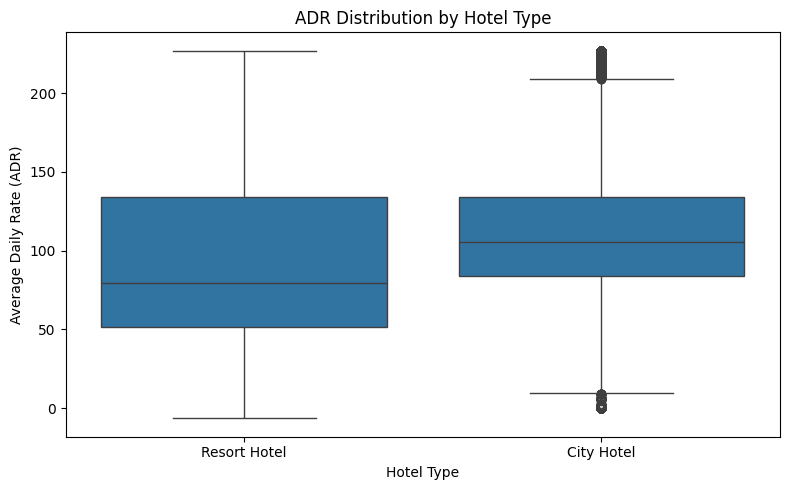

In [150]:
# Member 1: visualize ADR by hotel type
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="hotel", y="adr")
plt.title("ADR Distribution by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Average Daily Rate (ADR)")
plt.tight_layout()
plt.show()

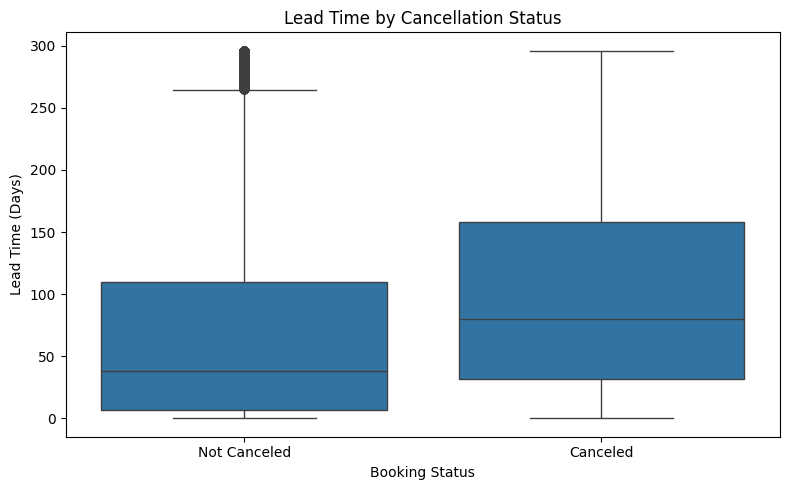

In [151]:
# Member 1: visualize lead time by cancellation status
lead_plot_df = df[["is_canceled", "lead_time"]].dropna().copy()
lead_plot_df["cancellation_status"] = lead_plot_df["is_canceled"].map({
    0: "Not Canceled",
    1: "Canceled"
})

plt.figure(figsize=(8, 5))
sns.boxplot(
    data=lead_plot_df,
    x="cancellation_status",
    y="lead_time",
    order=["Not Canceled", "Canceled"]
)
plt.title("Lead Time by Cancellation Status")
plt.xlabel("Booking Status")
plt.ylabel("Lead Time (Days)")
plt.tight_layout()
plt.show()

In [152]:
# Member 1: consolidate the two hypothesis-test results
member1_results = pd.DataFrame([
    {
        "Research Question": "ADR by hotel type",
        "Test": "Welch's independent two-sample t-test",
        "Group 1": "City Hotel",
        "Group 1 Mean": city_mean_adr,
        "Group 2": "Resort Hotel",
        "Group 2 Mean": resort_mean_adr,
        "Test Statistic": adr_test.statistic,
        "p-value": adr_test.pvalue,
        "Decision": "Reject H0" if adr_test.pvalue < alpha else "Fail to reject H0"
    },
    {
        "Research Question": "Lead time by cancellation status",
        "Test": "Welch's independent two-sample t-test",
        "Group 1": "Canceled",
        "Group 1 Mean": canceled_mean_lead,
        "Group 2": "Not Canceled",
        "Group 2 Mean": not_canceled_mean_lead,
        "Test Statistic": lead_time_test.statistic,
        "p-value": lead_time_test.pvalue,
        "Decision": "Reject H0" if lead_time_test.pvalue < alpha else "Fail to reject H0"
    }
])

display(member1_results.round(4))

,Research Question,Test,Group 1,Group 1 Mean,Group 2,Group 2 Mean,Test Statistic,p-value,Decision
0,ADR by hotel type,Welch's independent two-sample t-test,City Hotel,110.7859,Resort Hotel,97.2577,37.0395,0.0,Reject H0
1,Lead time by cancellation status,Welch's independent two-sample t-test,Canceled,103.2181,Not Canceled,69.0340,54.4998,0.0,Reject H0


## Categorical Hypothesis Testing

### Objective
The aim of this analysis is to find out whether hotel type, deposit type, and previous cancellation history are related to current booking cancellations.

### Methodology
The Chi-Square Test of Independence is used to check whether there is a significant relationship between two categorical variables. Cramér’s V is also calculated to understand how strong the relationship is.

### Hypotheses
- **Null Hypothesis (H₀):** There is no significant association between the two categorical variables.
- **Alternative Hypothesis (H₁):** There is a significant association between the two categorical variables.

### Tests Performed
1. **Hotel Type vs. Cancellation:** Checks whether cancellation rates differ between hotel types.
2. **Deposit Type vs. Cancellation:** Examines whether the type of deposit is related to booking cancellations.
3. **Previous vs. Current Cancellation:** Checks whether guests who cancelled bookings in the past are more likely to cancel their current bookings.

### Significance Level
A significance level of **0.05** is used for all tests. If the p-value is less than 0.05, the null hypothesis is rejected, indicating a statistically significant association.

### Expected Outcome
The analysis helps identify which factors are associated with booking cancellations and measures the strength of these relationships. However, these results show associations and do not necessarily mean that one factor causes another.

In [175]:

import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency
from IPython.display import display, Markdown

alpha = 0.05


In [187]:

from scipy.stats import chi2 as chi2_distribution

def run_chi_square_test(data, row_col, col_col, title):
    temp = data[[row_col, col_col]].dropna()
    table = pd.crosstab(temp[row_col], temp[col_col])

    chi2, p_value, dof, expected = chi2_contingency(table)

    n = table.to_numpy().sum()
    denom = n * min(table.shape[0] - 1, table.shape[1] - 1)
    cramers_v = np.sqrt(chi2 / denom) if denom > 0 else np.nan

    p_text = (
        "< 1e-300"
        if p_value == 0 or p_value < 1e-300
        else f"{p_value:.4g}"
    )

    critical_value = chi2_distribution.ppf(1 - alpha, dof)

    display(Markdown(f"## {title}"))
    display(Markdown(f"**Variables:** `{row_col}` vs `{col_col}`"))

    display(Markdown("### Contingency Table"))
    display(
        table.style
        .format(precision=0)
        .set_caption("Observed frequencies")
        .set_properties(**{
            "text-align": "center",
            "padding": "6px"
        })
    )

    results = pd.DataFrame({
        "Metric": [
            "Calculated Chi-square value",
            "Critical Chi-square value",
            "Degrees of freedom",
            "P-value",
            "Cramér's V",
            "Smallest expected count",
            "Sample size"
        ],
        "Value": [
            f"{chi2:.4f}",
            f"{critical_value:.4f}",
            str(dof),
            p_text,
            f"{cramers_v:.4f}",
            f"{expected.min():.2f}",
            f"{n:,}"
        ]
    })

    display(Markdown("### Statistical Results"))
    display(
        results.style
        .hide(axis="index")
        .set_properties(**{
            "text-align": "left",
            "padding": "5px"
        })
    )

    display(Markdown("### Interpretation"))

    # Use both methods to verify the same decision
    if chi2 > critical_value and p_value < alpha:
        display(Markdown("**Decision: Reject H₀.**"))
        display(Markdown(
            f"Calculated χ² ({chi2:.4f}) > critical χ² "
            f"({critical_value:.4f}), and p-value ({p_text}) "
            f"< {alpha}. There is significant evidence of an "
            f"association between **{row_col}** and **{col_col}**."
        ))
    else:
        display(Markdown("**Decision: Fail to reject H₀.**"))
        display(Markdown(
            f"Calculated χ² = {chi2:.4f}, critical χ² = "
            f"{critical_value:.4f}, and p-value = {p_text}. "
            f"The result does not meet the rejection criteria "
            f"at α = {alpha}; there is insufficient evidence of "
            f"an association between **{row_col}** and **{col_col}**."
        ))

    display(Markdown(
        f"**Cramér's V:** {cramers_v:.4f} — measures the strength "
        "of the association."
    ))

    if (expected < 5).any():
        display(Markdown(
            "**Caution:** At least one expected cell count is below 5."
        ))

    display(Markdown("---"))

    return {
        "title": title,
        "table": table,
        "chi2": chi2,
        "p_value": p_value,
        "dof": dof,
        "expected": expected,
        "cramers_v": cramers_v
    }


In [188]:

test_hotel_cancel = run_chi_square_test(
    df,
    "hotel",
    "is_canceled",
    "Test 1: Hotel Type vs Cancellation"
)

display(Markdown(
    "**H₀:** Hotel type and cancellation status are independent.  \n"
    "**H₁:** Hotel type and cancellation status are associated."
))


## Test 1: Hotel Type vs Cancellation

**Variables:** `hotel` vs `is_canceled`

### Contingency Table

is_canceled,0,1
hotel,,
City Hotel,37239,16035
Resort Hotel,25982,7974


### Statistical Results

...

**Decision: Reject H₀.**

Calculated χ² (454.6819) > critical χ² (3.8415), and p-value (6.906e-101) < 0.05. There is significant evidence of an association between **hotel** and **is_canceled**.

**Cramér's V:** 0.0722 — measures the strength of the association.

---

**H₀:** Hotel type and cancellation status are independent.  
**H₁:** Hotel type and cancellation status are associated.

In [189]:

test_deposit_cancel = run_chi_square_test(
    df,
    "deposit_type",
    "is_canceled",
    "Test 2: Deposit Type vs Cancellation"
)

display(Markdown(
    "**H₀:** Deposit type and cancellation status are independent.  \n"
    "**H₁:** Deposit type and cancellation status are associated."
))


## Test 2: Deposit Type vs Cancellation

**Variables:** `deposit_type` vs `is_canceled`

### Contingency Table

is_canceled,0,1
deposit_type,,
No Deposit,63085,23000
Non Refund,55,983
Refundable,81,26


### Statistical Results

...

**Decision: Reject H₀.**

Calculated χ² (2376.8311) > critical χ² (5.9915), and p-value (< 1e-300) < 0.05. There is significant evidence of an association between **deposit_type** and **is_canceled**.

**Cramér's V:** 0.1651 — measures the strength of the association.

---

**H₀:** Deposit type and cancellation status are independent.  
**H₁:** Deposit type and cancellation status are associated.

In [190]:

if "previous_cancellations" in df.columns:

    previous_group = np.where(
        df["previous_cancellations"].fillna(0) > 0,
        "Previous cancellation(s)",
        "No previous cancellations"
    )

    previous_cancel_data = pd.DataFrame({
        "previous_cancellation_group": previous_group,
        "is_canceled": df["is_canceled"]
    }).dropna()

    test_previous_cancel = run_chi_square_test(
        previous_cancel_data,
        "previous_cancellation_group",
        "is_canceled",
        "Test 3: Previous vs Current Cancellation"
    )

    display(Markdown(
        "**H₀:** Previous-cancellation group and current cancellation "
        "status are independent.  \n"
        "**H₁:** They are associated."
    ))

else:
    print(
        "Test 3 skipped: 'previous_cancellations' "
        "is not available."
    )


## Test 3: Previous vs Current Cancellation

**Variables:** `previous_cancellation_group` vs `is_canceled`

### Contingency Table

is_canceled,0,1
previous_cancellation_group,,
No previous cancellations,62683,22866
Previous cancellation(s),538,1143


### Statistical Results

...

**Decision: Reject H₀.**

Calculated χ² (1405.3159) > critical χ² (3.8415), and p-value (< 1e-300) < 0.05. There is significant evidence of an association between **previous_cancellation_group** and **is_canceled**.

**Cramér's V:** 0.1269 — measures the strength of the association.

---

**H₀:** Previous-cancellation group and current cancellation status are independent.  
**H₁:** They are associated.

## A/B-Style Comparison: City Hotel vs. Resort Hotel

### Objective
The goal is to check whether City Hotels and Resort Hotels have significantly different booking cancellation rates.

### Methodology
A two-proportion Z-test is used to compare the cancellation rates of the two hotel types. A 95% confidence interval is also calculated to estimate the possible difference between their cancellation rates.

### Hypotheses
- **Null Hypothesis (H₀):** City Hotels and Resort Hotels have the same cancellation rate.
- **Alternative Hypothesis (H₁):** The cancellation rates of City Hotels and Resort Hotels are different.

### Visualization
A bar chart is used to compare the percentage of cancelled bookings in City Hotels and Resort Hotels, making the difference easier to understand.

### Interpretation
The p-value is compared with the significance level of 0.05 to determine whether the difference in cancellation rates is statistically significant. The 95% confidence interval helps estimate the range of possible differences between the two hotel types.

**Note:** Since this analysis uses existing booking data rather than a randomized experiment, it can identify a relationship between hotel type and cancellation rates but cannot establish causation.

  City Hotel vs Resort Hotel Cancellation Comparision

1. CANCELLATION RATES (% cancelled bookings*100/total)
------------------------------------------------------------
City Hotel   : 16,035 / 53,274 bookings (30.10%)
Resort Hotel : 7,974 / 33,956 bookings (23.48%)
Rate Difference: 6.62 percentage points

2. HYPOTHESIS TEST
------------------------------------------------------------
H0: Both hotel types have equal cancellation rates.
H1: The cancellation rates are different.
Significance Level (alpha): 0.05
Z-statistic                 : 21.3310
P-value                     : 5.84875e-101

3. CONFIDENCE INTERVAL
------------------------------------------------------------
95% CI for the rate difference: [6.02, 7.21] percentage points

4. CONCLUSION
------------------------------------------------------------
Decision: Reject H0.
Reason: The p-value (5.84875e-101) is less than
the significance level (alpha = 0.05).
Therefore, the observed difference is statistically
significant, and we

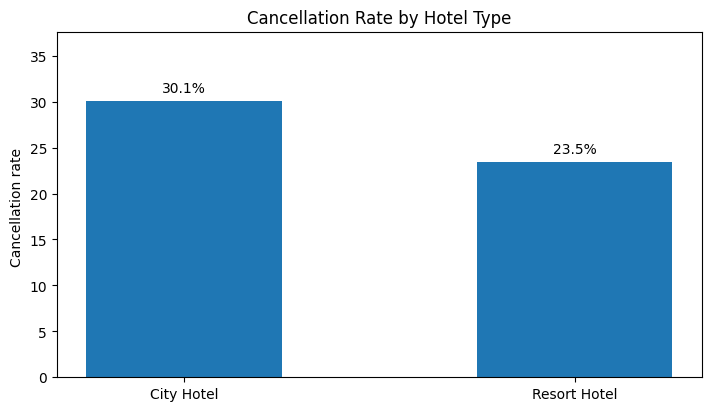

In [192]:
from scipy.stats import norm
import numpy as np
import matplotlib.pyplot as plt
#selecting datac
alpha = 0.05
ab_data = df[df["hotel"].isin(["City Hotel", "Resort Hotel"])].dropna(
    subset=["hotel", "is_canceled"]
)
#creates 2 groups
group_a = ab_data.loc[ab_data["hotel"] == "City Hotel", "is_canceled"].astype(int)
group_b = ab_data.loc[ab_data["hotel"] == "Resort Hotel", "is_canceled"].astype(int)

counts = np.array([group_a.sum(), group_b.sum()], dtype=float)#no of cancelled bookings
nobs = np.array([len(group_a), len(group_b)], dtype=float)#total bookings
rates = counts / nobs #cancellation
difference = rates[0] - rates[1]
#calculating the z score 
pooled_rate = counts.sum() / nobs.sum()
pooled_se = np.sqrt(pooled_rate * (1 - pooled_rate) * (1/nobs[0] + 1/nobs[1]))
z_stat = difference / pooled_se if pooled_se > 0 else np.nan
p_value = 2 * norm.sf(abs(z_stat))

# Unpooled Wald CI for the difference in independent proportions.
ci_se = np.sqrt(rates[0]*(1-rates[0])/nobs[0] + rates[1]*(1-rates[1])/nobs[1])
ci_low = difference - norm.ppf(0.975) * ci_se
ci_high = difference + norm.ppf(0.975) * ci_se

def format_p_ab(p):
    return "< 1e-300" if p == 0 or p < 1e-300 else f"{p:.6g}"


print("  City Hotel vs Resort Hotel Cancellation Comparision")

print("\n1. CANCELLATION RATES (% cancelled bookings*100/total)")
print("-" * 60)
print(f"City Hotel   : {int(counts[0]):,} / {int(nobs[0]):,} bookings ({rates[0]*100:.2f}%)")
print(f"Resort Hotel : {int(counts[1]):,} / {int(nobs[1]):,} bookings ({rates[1]*100:.2f}%)")
print(f"Rate Difference: {difference*100:.2f} percentage points")

print("\n2. HYPOTHESIS TEST")
print("-" * 60)
print("H0: Both hotel types have equal cancellation rates.")
print("H1: The cancellation rates are different.")
print(f"Significance Level (alpha): {alpha}")
print(f"Z-statistic                 : {z_stat:.4f}")
print(f"P-value                     : {format_p_ab(p_value)}")

print("\n3. CONFIDENCE INTERVAL")
print("-" * 60)
print(f"95% CI for the rate difference: [{ci_low*100:.2f}, {ci_high*100:.2f}] percentage points")

print("\n4. CONCLUSION")
print("-" * 60)

if p_value < alpha:
    print("Decision: Reject H0.")
    print(f"Reason: The p-value ({format_p_ab(p_value)}) is less than")
    print(f"the significance level (alpha = {alpha}).")
    print("Therefore, the observed difference is statistically")
    print("significant, and we reject the assumption that both")
    print("hotel types have equal cancellation rates.")
    print(f"The estimated difference is {difference*100:.2f}")
    print("percentage points (City Hotel - Resort Hotel).")
else:
    print("Decision: Fail to reject H0.")
    print(f"Reason: The p-value ({format_p_ab(p_value)}) is greater")
    print(f"than or equal to the significance level (alpha = {alpha}).")
    print("Therefore, there is insufficient statistical evidence")
    print("to conclude that the cancellation rates differ.")
    print("This does not prove that the two rates are equal.")

print("\nNote: This is an observational comparison, so the")
print("results establish a difference or lack of evidence for")
print("a difference, not a causal relationship.")
print("=" * 60)

plt.close("all")
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
values = rates * 100
bars = ax.bar(
    ["City Hotel", "Resort Hotel"],
    values,
    width=0.5
)
ax.set_ylabel("Cancellation rate ")
ax.set_title("Cancellation Rate by Hotel Type")
ax.set_ylim(0, max(values) * 1.25 if max(values) > 0 else 1)
ax.bar_label(bars, fmt="%.1f%%", padding=4)
plt.show()

# Member 3 — Cancellation Classification Model

**Problem:** Estimate whether a hotel booking will be canceled using features plausibly available at the time the booking is made.

**Primary model: Logistic Regression.** It is suitable for a binary target (`is_canceled` = 0/1), gives cancellation probabilities, and supports interpretable coefficients and odds ratios. Its assumptions/cautions include a linear relationship between predictors and log-odds, independent observations, limited multicollinearity, and adequate model specification. One-hot encoding handles categorical predictors; numeric predictors are standardized.

**Benchmark:** Random Forest is retained only as a comparison model to check whether a nonlinear ensemble improves held-out performance. The project remains a data-analysis case study; prediction is one supporting component.

**Leakage prevention:** Exclude `reservation_status` and `reservation_status_date` because they reveal the outcome. Also exclude fields that may only be known after booking, including `assigned_room_type`, `booking_changes`, `days_in_waiting_list`, and `total_of_special_requests`. Reassess feature availability if the prediction is intended for a specific real booking workflow.

In [155]:
# Member 3: prepare data and train two classification models
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

if "is_canceled" not in df.columns:
    raise KeyError("The dataframe must contain the target column 'is_canceled'.")

model_data = df.copy()
model_data = model_data[model_data["is_canceled"].isin([0, 1])].copy()

# Predict cancellation using information plausibly available at booking time.
# Exclude outcome leakage and post-booking fields that may not be known at the initial booking.
excluded_after_booking = [
    "reservation_status", "reservation_status_date",
    "assigned_room_type", "booking_changes", "days_in_waiting_list",
    "total_of_special_requests"
]
leakage_cols = [c for c in excluded_after_booking if c in model_data.columns]
X = model_data.drop(columns=["is_canceled"] + leakage_cols, errors="ignore")
y = model_data["is_canceled"].astype(int)

# Remove columns that are entirely empty and identifiers that are not useful predictors.
all_missing_cols = X.columns[X.isna().all()].tolist()
X = X.drop(columns=all_missing_cols, errors="ignore")
identifier_cols = [c for c in ["Booking_ID", "booking_id", "id"] if c in X.columns]
X = X.drop(columns=identifier_cols, errors="ignore")

# Split before fitting preprocessing, preserving class proportions.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

numeric_features = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]

numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_preprocessor, numeric_features),
    ("categorical", categorical_preprocessor, categorical_features)
])

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200, max_depth=None, min_samples_leaf=2,
        class_weight="balanced", random_state=42, n_jobs=-1
    ))
])

logistic_model.fit(X_train, y_train)
random_forest_model.fit(X_train, y_train)

print(f"Training rows: {len(X_train):,}")
print(f"Testing rows:  {len(X_test):,}")
print(f"Numeric features: {len(numeric_features)}")
print(f"Categorical features: {len(categorical_features)}")
print(f"Excluded outcome/post-booking columns: {leakage_cols if leakage_cols else 'none found'}")
print("Logistic Regression is the primary interpretable classification model; Random Forest is retained as a comparison baseline.")
print("The split occurs before fitting imputers, scaling, and one-hot encoding, preventing preprocessing leakage.")
print("Both models have been trained successfully.")

Training rows: 69,784
Testing rows:  17,446
Numeric features: 17
Categorical features: 10
Excluded outcome/post-booking columns: ['reservation_status', 'reservation_status_date', 'assigned_room_type', 'booking_changes', 'days_in_waiting_list', 'total_of_special_requests']
Logistic Regression is the primary interpretable classification model; Random Forest is retained as a comparison baseline.
The split occurs before fitting imputers, scaling, and one-hot encoding, preventing preprocessing leakage.
Both models have been trained successfully.


## Model Evaluation and Comparison

Accuracy alone can hide poor performance when classes are imbalanced. We therefore report accuracy, precision, recall, F1-score and ROC-AUC, plus confusion matrices. ROC-AUC is computed from predicted probabilities.

### Evaluate both models on the same held-out test set

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.7210,0.4955,0.7545,0.5982,0.814
Random Forest,0.7864,0.5775,0.8344,0.6826,0.879



Classification report: Logistic Regression
              precision    recall  f1-score   support

Not canceled       0.88      0.71      0.79     12644
    Canceled       0.50      0.75      0.60      4802

    accuracy                           0.72     17446
   macro avg       0.69      0.73      0.69     17446
weighted avg       0.78      0.72      0.73     17446



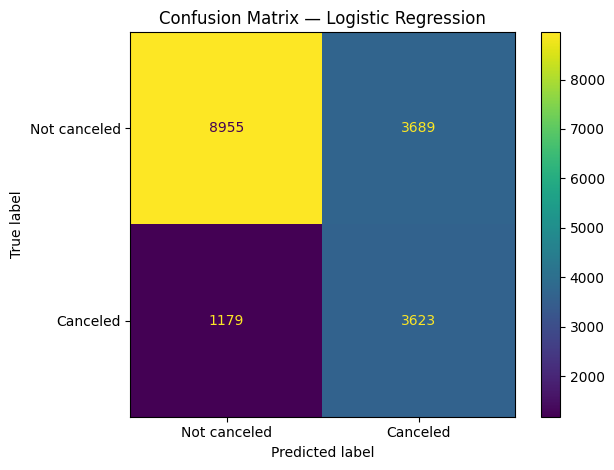


Classification report: Random Forest
              precision    recall  f1-score   support

Not canceled       0.92      0.77      0.84     12644
    Canceled       0.58      0.83      0.68      4802

    accuracy                           0.79     17446
   macro avg       0.75      0.80      0.76     17446
weighted avg       0.83      0.79      0.80     17446



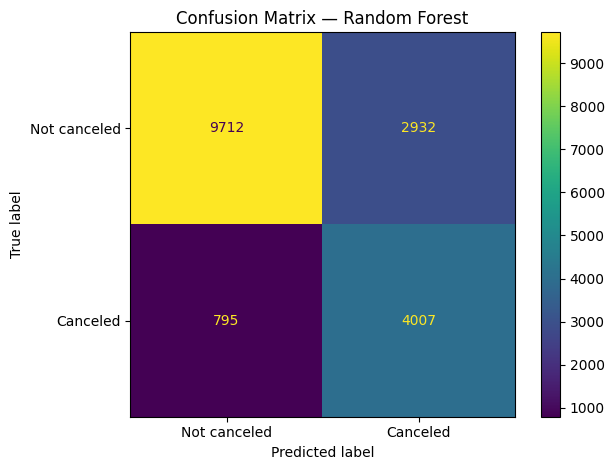

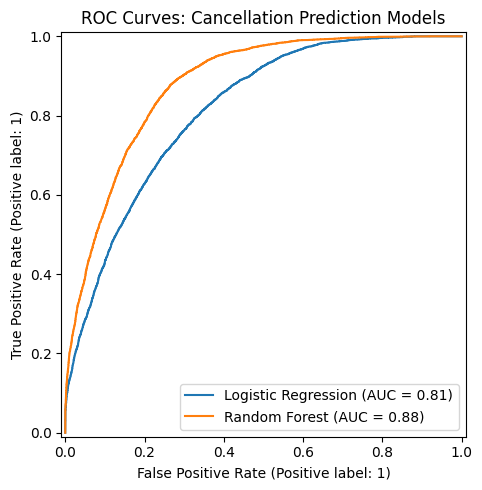

Model with the highest F1-score on this test split: Random Forest
Use the metric trade-offs and the project objective when selecting a final model; do not choose based on accuracy alone.


In [156]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report, RocCurveDisplay
)

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}
evaluation_results = {}
comparison_rows = []

for model_name, model in models.items():
    y_pred = model.predict(X_test)
    y_score = model.predict_proba(X_test)[:, 1]

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_score)
    }
    comparison_rows.append(metrics)
    evaluation_results[model_name] = {
        "y_pred": y_pred,
        "y_score": y_score,
        "confusion_matrix": confusion_matrix(y_test, y_pred)
    }

comparison_df = pd.DataFrame(comparison_rows).set_index("Model")
display(comparison_df.round(4))

for model_name, model in models.items():
    print("\n" + "=" * 70)
    print(f"Classification report: {model_name}")
    print("=" * 70)
    print(classification_report(y_test, evaluation_results[model_name]["y_pred"],
                                target_names=["Not canceled", "Canceled"], zero_division=0))

    ConfusionMatrixDisplay.from_predictions(
        y_test, evaluation_results[model_name]["y_pred"],
        display_labels=["Not canceled", "Canceled"], values_format="d"
    )
    plt.title(f"Confusion Matrix — {model_name}")
    plt.tight_layout()
    plt.show()

plt.figure(figsize=(7, 5))
for model_name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=model_name, ax=plt.gca())
plt.title("ROC Curves: Cancellation Prediction Models")
plt.tight_layout()
plt.show()

best_model_name = comparison_df["F1-score"].idxmax()
print(f"Model with the highest F1-score on this test split: {best_model_name}")
print("Use the metric trade-offs and the project objective when selecting a final model; do not choose based on accuracy alone.")

In [157]:

# Cross-validation and interpretable Logistic Regression coefficients
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score, roc_auc_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc"
}

print("5-fold stratified cross-validation for the primary Logistic Regression model")
cv_results = cross_validate(
    logistic_model, X_train, y_train, cv=cv,
    scoring=cv_scoring, n_jobs=1, return_train_score=False
)
cv_summary = pd.DataFrame({
    metric.replace("test_", "").upper(): cv_results[metric]
    for metric in cv_results if metric.startswith("test_")
})
display(cv_summary.round(4))
print("\nMean and standard deviation across folds:")
display(pd.DataFrame({
    "Mean": cv_summary.mean(),
    "Std. Dev.": cv_summary.std(ddof=1)
}).round(4))

# Odds ratios from the fitted Logistic Regression model.
# Numeric features are standardized, so their OR is for a one-standard-deviation increase.
fitted_preprocessor = logistic_model.named_steps["preprocessor"]
fitted_classifier = logistic_model.named_steps["classifier"]
feature_names = fitted_preprocessor.get_feature_names_out()
coefficients = fitted_classifier.coef_.ravel()

coef_table = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Odds Ratio": np.exp(np.clip(coefficients, -20, 20))
})
coef_table["Absolute Coefficient"] = coef_table["Coefficient"].abs()
coef_table = coef_table.sort_values("Absolute Coefficient", ascending=False)

print("Largest-magnitude Logistic Regression coefficients (not causal effects):")
display(coef_table[["Feature", "Coefficient", "Odds Ratio"]].head(20).round(4))

print("Interpretation: odds ratio > 1 indicates higher estimated cancellation odds as that encoded feature increases/is present,")
print("while odds ratio < 1 indicates lower estimated odds, holding other model features constant.")
print("For standardized numeric features, the odds ratio corresponds to a one-standard-deviation increase.")
print("Coefficients describe model associations, not causal effects. One-hot category odds ratios are relative to the encoding reference.")


5-fold stratified cross-validation for the primary Logistic Regression model


,ACCURACY,PRECISION,RECALL,F1,ROC_AUC
0,0.7165,0.4902,0.7584,0.5955,0.8110
1,0.7172,0.4910,0.7532,0.5945,0.8108
2,0.7214,0.4959,0.7483,0.5965,0.8107
3,0.7188,0.4929,0.7507,0.5951,0.8089
4,0.7209,0.4953,0.7477,0.5959,0.8103



Mean and standard deviation across folds:


,Mean,Std. Dev.
ACCURACY,0.7189,0.0022
PRECISION,0.4931,0.0025
RECALL,0.7517,0.0043
F1,0.5955,0.0008
ROC_AUC,0.8103,0.0008


Largest-magnitude Logistic Regression coefficients (not causal effects):


,Feature,Coefficient,Odds Ratio
15,numeric__required_car_parking_spaces,-4.3589,0.0128
41,categorical__country_ARE,2.0950,8.1254
229,categorical__deposit_type_Non Refund,1.8963,6.6615
100,categorical__country_HKG,1.8393,6.2922
171,categorical__country_SAU,1.5772,4.8412
155,categorical__country_NZL,-1.5450,0.2133
137,categorical__country_MDV,1.4950,4.4593
37,categorical__country_AGO,1.4900,4.4370
177,categorical__country_SRB,-1.4797,0.2277
53,categorical__country_BGR,-1.4197,0.2418


Interpretation: odds ratio > 1 indicates higher estimated cancellation odds as that encoded feature increases/is present,
while odds ratio < 1 indicates lower estimated odds, holding other model features constant.
For standardized numeric features, the odds ratio corresponds to a one-standard-deviation increase.
Coefficients describe model associations, not causal effects. One-hot category odds ratios are relative to the encoding reference.


### Interpretation of confusion matrices

A true positive is a canceled booking correctly identified as canceled; a true negative is a non-canceled booking correctly identified as non-canceled. False negatives are missed cancellations, while false positives are non-canceled bookings incorrectly flagged as cancellations.

For hotel operations, recall measures the share of actual cancellations identified, while precision measures the share of flagged bookings that are actually canceled. The appropriate balance depends on the cost of missed cancellations versus unnecessary follow-up.

In [158]:
for model_name, results in evaluation_results.items():

    tn, fp, fn, tp = results["confusion_matrix"].ravel()

    print(f"\n{'='*55}")
    print(f"MODEL: {model_name}")
    print(f"{'='*55}")

    print(f"True Negatives  : {tn}")
    print(f"False Positives : {fp}")
    print(f"False Negatives : {fn}")
    print(f"True Positives  : {tp}")

    print("\nInterpretation:")
    print(f"- Correctly identified {tp} canceled bookings.")
    print(f"- Correctly identified {tn} non-canceled bookings.")
    print(f"- Missed {fn} actual cancellations.")
    print(f"- Incorrectly predicted {fp} cancellations.")

    print(f"- Cancellation detection rate: "
          f"{tp / (tp + fn) * 100:.2f}%")

    print()


MODEL: Logistic Regression
True Negatives  : 8955
False Positives : 3689
False Negatives : 1179
True Positives  : 3623

Interpretation:
- Correctly identified 3623 canceled bookings.
- Correctly identified 8955 non-canceled bookings.
- Missed 1179 actual cancellations.
- Incorrectly predicted 3689 cancellations.
- Cancellation detection rate: 75.45%


MODEL: Random Forest
True Negatives  : 9712
False Positives : 2932
False Negatives : 795
True Positives  : 4007

Interpretation:
- Correctly identified 4007 canceled bookings.
- Correctly identified 9712 non-canceled bookings.
- Missed 795 actual cancellations.
- Incorrectly predicted 2932 cancellations.
- Cancellation detection rate: 83.44%



### Model performance comparison

In [159]:
print("MODEL COMPARISON AND INTERPRETATION")
print("=" * 65)
display(comparison_df.round(4))

best_model = comparison_df["F1-score"].idxmax()
print(f"\nHighest F1-score on this held-out test split: {best_model}")

for metric in ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]:
    values = comparison_df[metric]
    difference = (values.get("Random Forest", np.nan) -
                  values.get("Logistic Regression", np.nan)) * 100
    print(f"{metric}: Random Forest minus Logistic Regression = {difference:+.2f} percentage points.")

print("\nInterpretation:")
print("The model with the higher F1-score balances precision and recall better on this test split.")
print("Use cross-validation, odds ratios, confusion matrices and the business cost of missed cancellations")
print("versus unnecessary follow-up before selecting a model for real use.")

MODEL COMPARISON AND INTERPRETATION


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.7210,0.4955,0.7545,0.5982,0.814
Random Forest,0.7864,0.5775,0.8344,0.6826,0.879



Highest F1-score on this held-out test split: Random Forest
Accuracy: Random Forest minus Logistic Regression = +6.54 percentage points.
Precision: Random Forest minus Logistic Regression = +8.20 percentage points.
Recall: Random Forest minus Logistic Regression = +8.00 percentage points.
F1-score: Random Forest minus Logistic Regression = +8.44 percentage points.
ROC-AUC: Random Forest minus Logistic Regression = +6.50 percentage points.

Interpretation:
The model with the higher F1-score balances precision and recall better on this test split.
Use cross-validation, odds ratios, confusion matrices and the business cost of missed cancellations
versus unnecessary follow-up before selecting a model for real use.


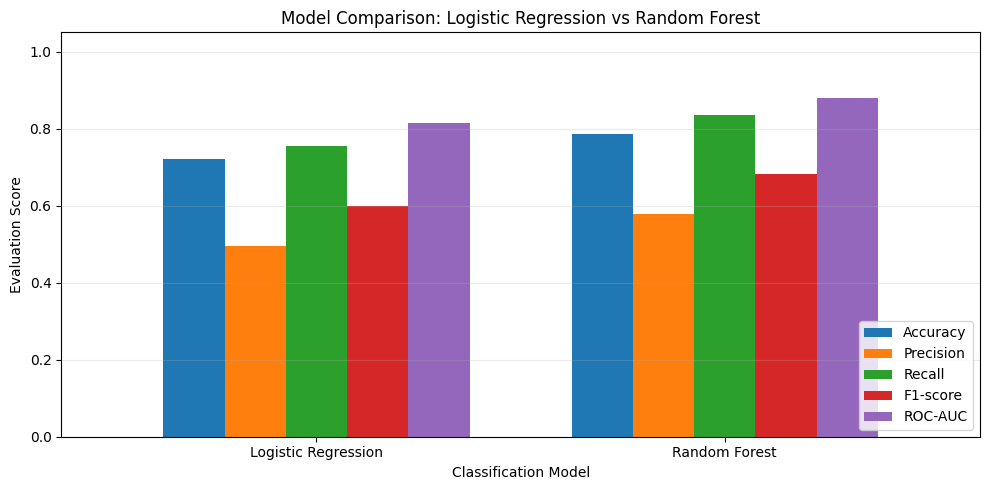

In [160]:
import matplotlib.pyplot as plt

ax = comparison_df.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.75
)

plt.title("Model Comparison: Logistic Regression vs Random Forest")
plt.xlabel("Classification Model")
plt.ylabel("Evaluation Score")
plt.xticks(rotation=0)
plt.ylim(0, 1.05)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## Cancellation Visualizations

These charts show **cancellation rate (%)**, not merely the number of bookings. Each rate is calculated as the mean of `is_canceled` within the category multiplied by 100.

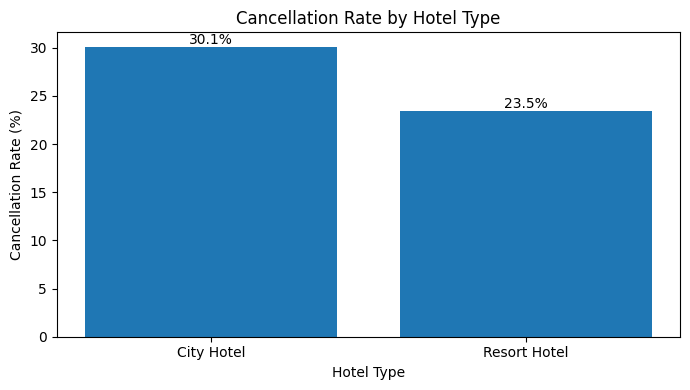

,Cancellation rate (%)
hotel,
City Hotel,30.10
Resort Hotel,23.48


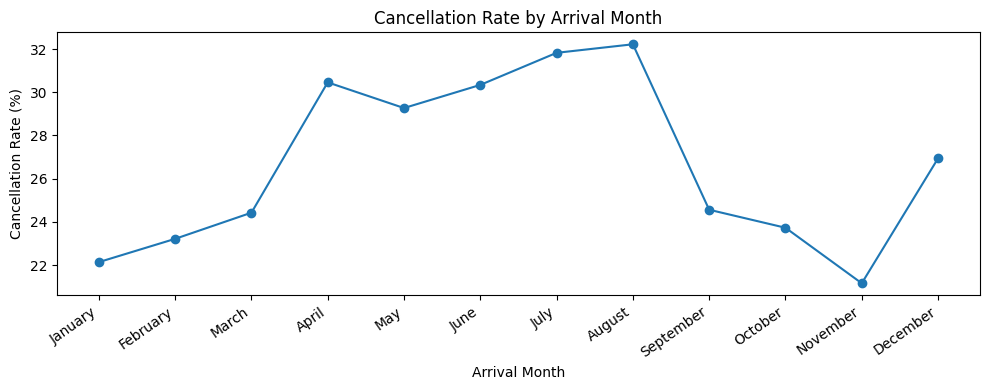

,Cancellation rate (%)
arrival_date_month,
January,22.13
February,23.21
March,24.42
April,30.46
May,29.27
June,30.34
July,31.82
August,32.22
September,24.56


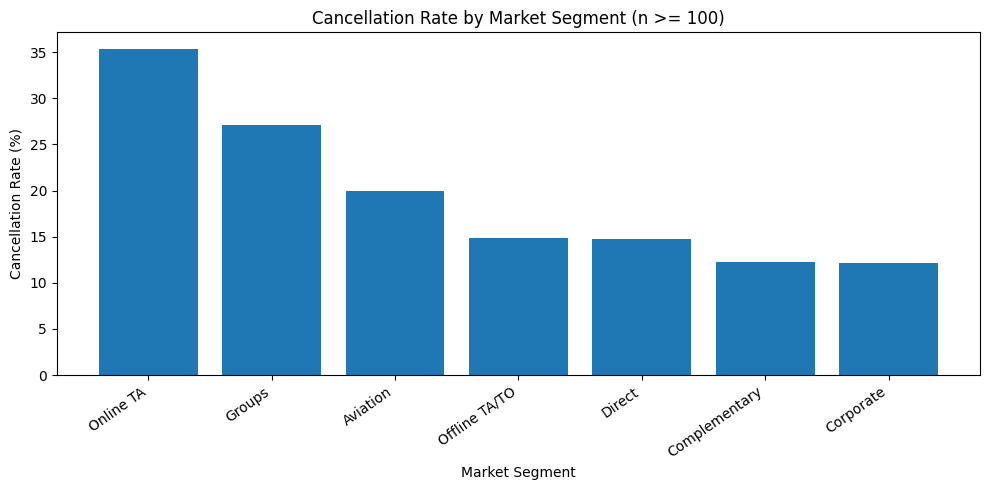

,Total_Bookings,Canceled_Bookings,Cancellation_Rate
market_segment,,,
Online TA,51553,18242,35.38
Groups,4922,1332,27.06
Aviation,226,45,19.91
Offline TA/TO,13855,2057,14.85
Direct,11780,1737,14.75
Complementary,692,85,12.28
Corporate,4200,509,12.12


Excluded segments with fewer than 100 bookings from the comparison.


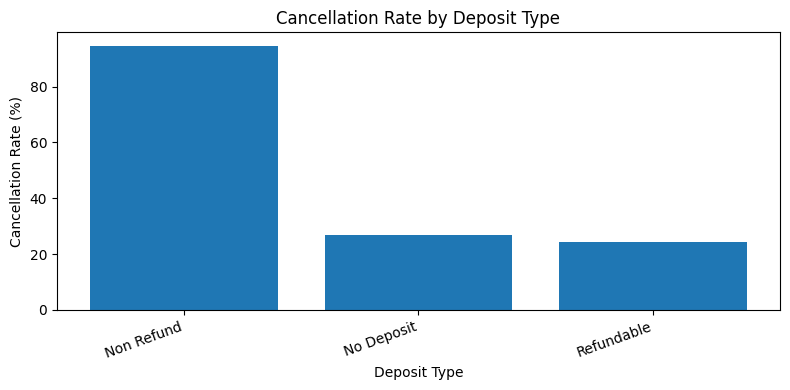

,Cancellation rate (%)
deposit_type,
Non Refund,94.70
No Deposit,26.72
Refundable,24.30


In [161]:
# Cancellation rate by hotel type
hotel_cancel_rate = df.groupby("hotel", dropna=False)["is_canceled"].mean().mul(100).sort_values(ascending=False)
plt.figure(figsize=(7, 4))
plt.bar(hotel_cancel_rate.index.astype(str), hotel_cancel_rate.values)
plt.title("Cancellation Rate by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Cancellation Rate (%)")
for i, v in enumerate(hotel_cancel_rate.values):
    plt.text(i, v, f"{v:.1f}%", ha="center", va="bottom")
plt.tight_layout()
plt.show()
display(hotel_cancel_rate.rename("Cancellation rate (%)").round(2).to_frame())

# Cancellation rate by arrival month, in calendar order where possible
month_order = ["January", "February", "March", "April", "May", "June",
               "July", "August", "September", "October", "November", "December"]
month_rates = df.groupby("arrival_date_month")["is_canceled"].mean().mul(100)
ordered_months = [m for m in month_order if m in month_rates.index]
month_rates = month_rates.reindex(ordered_months)
plt.figure(figsize=(10, 4))
plt.plot(month_rates.index, month_rates.values, marker="o")
plt.title("Cancellation Rate by Arrival Month")
plt.xlabel("Arrival Month")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()
display(month_rates.rename("Cancellation rate (%)").round(2).to_frame())

# Cancellation rate by market segment
MIN_N = 100

segment_summary = (
    df.groupby("market_segment")["is_canceled"]
    .agg(
        Total_Bookings="count",
        Canceled_Bookings="sum",
        Cancellation_Rate="mean"
    )
)

segment_summary["Cancellation_Rate"] *= 100

# Exclude categories with fewer than 100 bookings
eligible_segments = segment_summary[
    segment_summary["Total_Bookings"] >= MIN_N
]

segment_rates = (
    eligible_segments["Cancellation_Rate"]
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

plt.bar(segment_rates.index, segment_rates.values)

plt.title("Cancellation Rate by Market Segment (n >= 100)")
plt.xlabel("Market Segment")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

display(
    eligible_segments.loc[segment_rates.index].round(2)
)

print(
    f"Excluded segments with fewer than {MIN_N} bookings "
    "from the comparison."
)

# Cancellation rate by deposit type
if "deposit_type" in df.columns:
    deposit_rates = df.groupby("deposit_type")["is_canceled"].mean().mul(100).sort_values(ascending=False)
    plt.figure(figsize=(8, 4))
    plt.bar(deposit_rates.index.astype(str), deposit_rates.values)
    plt.title("Cancellation Rate by Deposit Type")
    plt.xlabel("Deposit Type")
    plt.ylabel("Cancellation Rate (%)")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()
    display(deposit_rates.rename("Cancellation rate (%)").round(2).to_frame())
else:
    print("The 'deposit_type' column is unavailable; deposit-type chart skipped.")

### Cancellation rates with booking counts

In [162]:
group_columns = [
    "hotel",
    "arrival_date_month",
    "market_segment",
    "deposit_type"
]

for column in group_columns:

    summary = (
        df.groupby(column, dropna=False)["is_canceled"]
        .agg(
            Total_Bookings="count",
            Canceled_Bookings="sum",
            Cancellation_Rate="mean"
        )
    )

    summary["Cancellation_Rate"] *= 100

    summary = summary.sort_values(
        by="Cancellation_Rate",
        ascending=False
    )

    print("\n" + "=" * 70)
    print(f"CANCELLATION ANALYSIS BY {column.upper()}")
    print("=" * 70)

    display(summary.round(2))


CANCELLATION ANALYSIS BY HOTEL


,Total_Bookings,Canceled_Bookings,Cancellation_Rate
hotel,,,
City Hotel,53274,16035,30.10
Resort Hotel,33956,7974,23.48



CANCELLATION ANALYSIS BY ARRIVAL_DATE_MONTH


,Total_Bookings,Canceled_Bookings,Cancellation_Rate
arrival_date_month,,,
August,11242,3622,32.22
July,10043,3196,31.82
April,7900,2406,30.46
June,7756,2353,30.34
May,8344,2442,29.27
December,5112,1377,26.94
September,6682,1641,24.56
March,7489,1829,24.42
October,6921,1642,23.72



CANCELLATION ANALYSIS BY MARKET_SEGMENT


,Total_Bookings,Canceled_Bookings,Cancellation_Rate
market_segment,,,
Undefined,2,2,100.00
Online TA,51553,18242,35.38
Groups,4922,1332,27.06
Aviation,226,45,19.91
Offline TA/TO,13855,2057,14.85
Direct,11780,1737,14.75
Complementary,692,85,12.28
Corporate,4200,509,12.12



CANCELLATION ANALYSIS BY DEPOSIT_TYPE


,Total_Bookings,Canceled_Bookings,Cancellation_Rate
deposit_type,,,
Non Refund,1038,983,94.70
No Deposit,86085,23000,26.72
Refundable,107,26,24.30


### Interpretation of Cancellation Patterns

Use the rate tables and charts directly above to report the observed cancellation rate and booking count for each category. Always report both the rate and sample size: a 100% rate in a very small category may be unstable.

**Deposit-type caution:** If Non Refund bookings show a very high cancellation rate, treat it as an important pattern to investigate, not proof that the deposit policy caused cancellations. Check the category's number of bookings, the dataset's coding and business definitions, and possible confounding factors before making a policy recommendation.

## Member 4 — Final Findings and Model Evaluation Summary

The following cells summarize model performance and descriptive cancellation patterns using the currently executed results. The preferred model should be selected using the project objective and the precision/recall trade-off, not by accuracy alone. Logistic Regression is the primary interpretable model; Random Forest is included as a benchmark.

In [163]:
print("MEMBER 4 — FINAL RESULTS AND CONCLUSION")
print("=" * 65)

print("\n1. MODEL PERFORMANCE")

display(comparison_df.round(4))

best_model = comparison_df["F1-score"].idxmax()

print(f"\nBest model based on F1-score: {best_model}")

print(
    f"Accuracy : "
    f"{comparison_df.loc[best_model, 'Accuracy']:.2%}"
)

print(
    f"Precision: "
    f"{comparison_df.loc[best_model, 'Precision']:.2%}"
)

print(
    f"Recall   : "
    f"{comparison_df.loc[best_model, 'Recall']:.2%}"
)

print(
    f"F1-score : "
    f"{comparison_df.loc[best_model, 'F1-score']:.2%}"
)

print(
    f"ROC-AUC  : "
    f"{comparison_df.loc[best_model, 'ROC-AUC']:.4f}"
)

print("\n2. CANCELLATION PATTERNS")

patterns = {
    "Hotel Type": hotel_cancel_rate,
    "Arrival Month": month_rates,
    "Market Segment": segment_rates,
    "Deposit Type": deposit_rates
}

for name, rates in patterns.items():

    if rates is not None and not rates.empty:
        highest = rates.idxmax()
        percentage = rates.max()

        print(
            f"{name}: {highest} "
            f"({percentage:.2f}%)"
        )

print("\n3. KEY FINDINGS")

print(
    "- Both classification models were evaluated "
    "on the same test data."
)

print(
    f"- {best_model} achieved the highest F1-score."
)

print(
    "- Cancellation behavior differs across "
    "hotel and booking categories."
)

print(
    "- Higher cancellation rates should be "
    "interpreted alongside booking counts."
)

print("\n4. LIMITATIONS")

print(
    "- The dataset contains historical bookings."
)

print(
    "- Cancellation patterns may change over time."
)

print(
    "- Observed associations do not establish causation."
)

print(
    "- Model performance may vary on unseen data."
)

print(
    "- Post-booking and outcome-revealing features are excluded, "
    "but feature availability should be rechecked for the intended use."
)

print("\n5. FINAL CONCLUSION")

print(
    f"{best_model} is the preferred model based on "
    "the current F1-score comparison. "
    "The findings provide useful information about "
    "hotel booking cancellation patterns, subject "
    "to data quality and model validation."
)

MEMBER 4 — FINAL RESULTS AND CONCLUSION

1. MODEL PERFORMANCE


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.7210,0.4955,0.7545,0.5982,0.814
Random Forest,0.7864,0.5775,0.8344,0.6826,0.879



Best model based on F1-score: Random Forest
Accuracy : 78.64%
Precision: 57.75%
Recall   : 83.44%
F1-score : 68.26%
ROC-AUC  : 0.8790

2. CANCELLATION PATTERNS
Hotel Type: City Hotel (30.10%)
Arrival Month: August (32.22%)
Market Segment: Online TA (35.38%)
Deposit Type: Non Refund (94.70%)

3. KEY FINDINGS
- Both classification models were evaluated on the same test data.
- Random Forest achieved the highest F1-score.
- Cancellation behavior differs across hotel and booking categories.
- Higher cancellation rates should be interpreted alongside booking counts.

4. LIMITATIONS
- The dataset contains historical bookings.
- Cancellation patterns may change over time.
- Observed associations do not establish causation.
- Model performance may vary on unseen data.
- Post-booking and outcome-revealing features are excluded, but feature availability should be rechecked for the intended use.

5. FINAL CONCLUSION
Random Forest is the preferred model based on the current F1-score comparison. T

### Model Evaluation Conclusion

After executing the notebook, use the model comparison table, confusion matrices, ROC curves, cross-validation results and Logistic Regression odds-ratio table to support the model choice.

Logistic Regression is useful for interpretation because it provides coefficients and odds ratios. Random Forest may capture nonlinear patterns but is less directly interpretable. Compare recall and precision because missed cancellations and unnecessary follow-up have different operational costs. The reported scores are estimates from this dataset and split, not a guarantee of future performance.

# Additional Review 2 Deliverables

The cells below add a Plotly visualization section, a compact dashboard, dataset/source documentation, and a final submission checklist. Run the notebook from top to bottom before using any reported results in the report or presentation.

## Plotly Visualizations

Plotly is used here as an additional interactive visualization tool. If Plotly is not installed, run `%pip install plotly` in a separate notebook cell and then rerun this section.

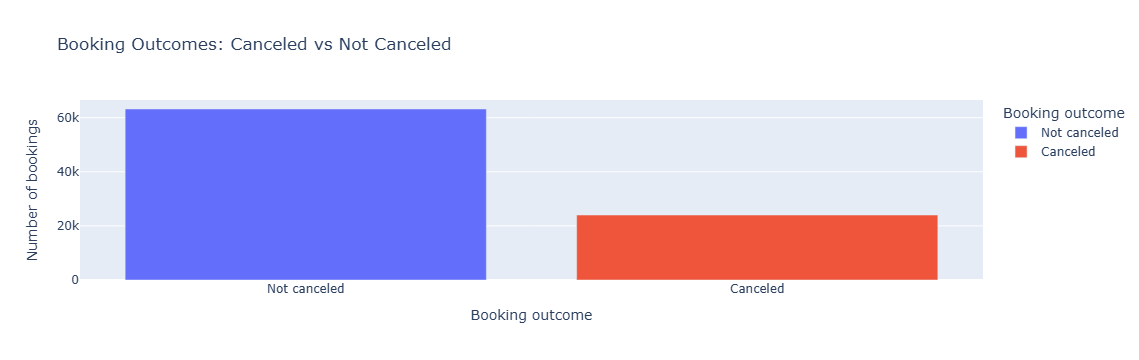

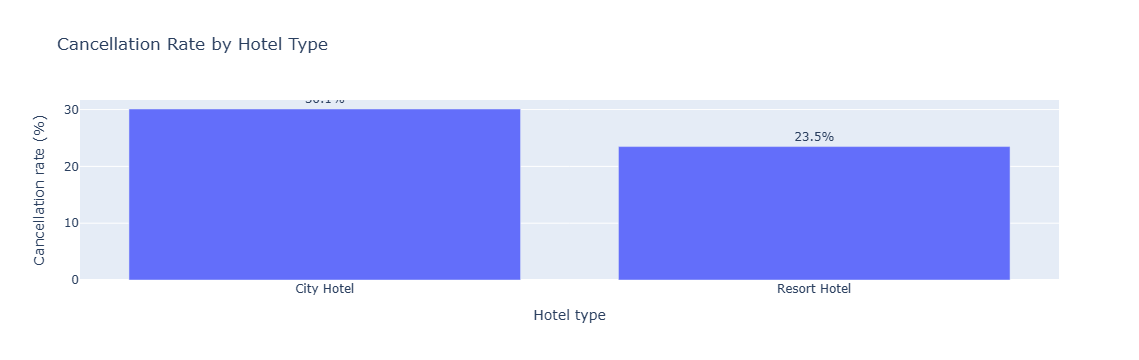

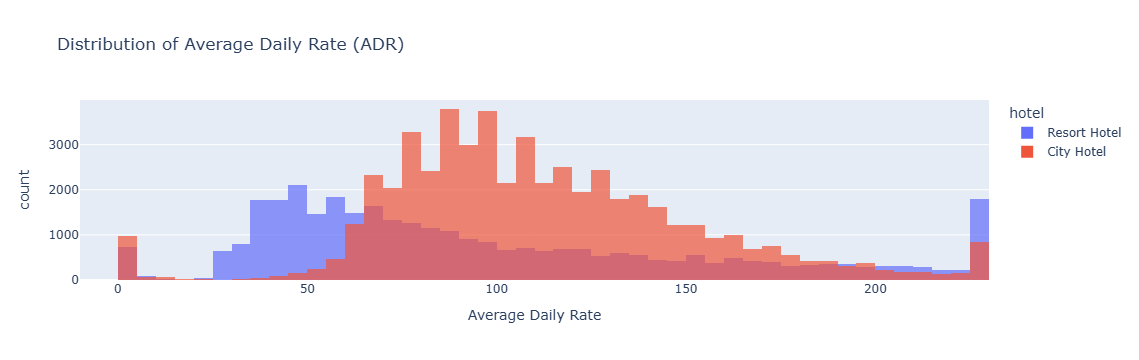

In [164]:
try:
    # Interactive Plotly charts
    # Install if needed: %pip install plotly
    import plotly.express as px

    # 1. Booking cancellation distribution
    cancel_counts = df["is_canceled"].map({0: "Not canceled", 1: "Canceled"}).value_counts().rename_axis("Booking outcome").reset_index(name="Bookings")
    fig = px.bar(
        cancel_counts, x="Booking outcome", y="Bookings", color="Booking outcome",
        title="Booking Outcomes: Canceled vs Not Canceled",
        labels={"Bookings": "Number of bookings"}
    )
    fig.show()

    # 2. Cancellation rate by hotel type
    plot_hotel = df.groupby("hotel", as_index=False)["is_canceled"].mean()
    plot_hotel["Cancellation rate (%)"] = plot_hotel["is_canceled"] * 100
    fig = px.bar(
        plot_hotel, x="hotel", y="Cancellation rate (%)", text="Cancellation rate (%)",
        title="Cancellation Rate by Hotel Type",
        labels={"hotel": "Hotel type"}
    )
    fig.update_traces(texttemplate="%{text:.1f}%", textposition="outside")
    fig.show()

    # 3. ADR distribution (exclude non-finite values for a cleaner chart)
    adr_data = df.loc[df["adr"].notna() & (df["adr"].replace([float("inf"), float("-inf")], float("nan")).notna()), ["adr", "hotel"]].copy()
    fig = px.histogram(
        adr_data, x="adr", color="hotel", nbins=50, barmode="overlay",
        opacity=0.7, title="Distribution of Average Daily Rate (ADR)",
        labels={"adr": "Average Daily Rate"}
    )
    fig.show()
except ImportError:
    print("Plotly is not installed. Run %pip install plotly in a notebook cell, then rerun this visualization section.")

## Compact Python Dashboard

This dashboard combines four views: booking outcomes, cancellation rate by hotel, ADR distribution, and cancellation rate by market segment. It is intended as a compact notebook dashboard; it does not replace a separately submitted Tableau/Power BI dashboard if your instructor specifically requires one.

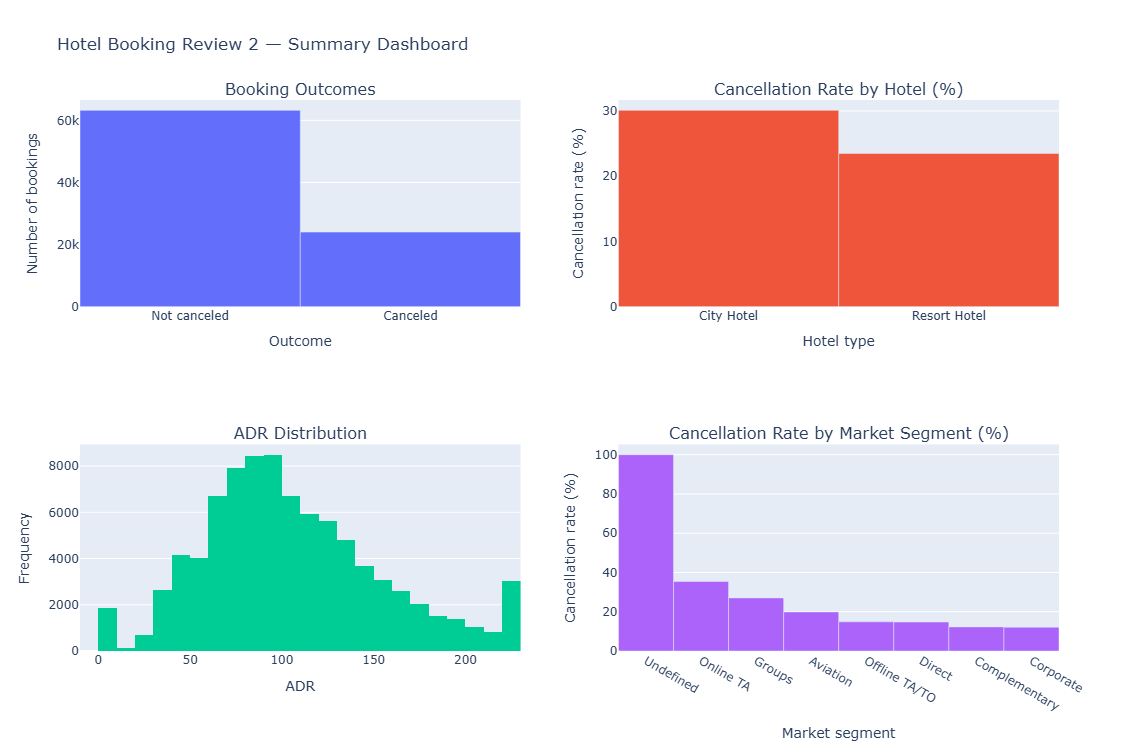

In [165]:
try:
    from IPython.display import display
    import plotly.express as px
    from plotly.subplots import make_subplots
    import plotly.graph_objects as go

    dashboard = make_subplots(
        rows=2, cols=2,
        subplot_titles=(
            "Booking Outcomes",
            "Cancellation Rate by Hotel (%)",
            "ADR Distribution",
            "Cancellation Rate by Market Segment (%)"
        ),
        specs=[[{"type":"bar"}, {"type":"bar"}], [{"type":"histogram"}, {"type":"bar"}]]
    )

    # Panel 1: booking outcomes
    outcome_counts = df["is_canceled"].map({0:"Not canceled", 1:"Canceled"}).value_counts()
    dashboard.add_trace(
        go.Bar(x=outcome_counts.index.astype(str), y=outcome_counts.values, name="Bookings"),
        row=1, col=1
    )

    # Panel 2: cancellation rate by hotel
    hotel_rates_dash = df.groupby("hotel")["is_canceled"].mean().mul(100).sort_values(ascending=False)
    dashboard.add_trace(
        go.Bar(x=hotel_rates_dash.index.astype(str), y=hotel_rates_dash.values, name="Hotel rate"),
        row=1, col=2
    )

    # Panel 3: ADR distribution, excluding non-finite values
    adr_dash = pd.to_numeric(df["adr"], errors="coerce")
    adr_dash = adr_dash[adr_dash.notna() & np.isfinite(adr_dash)]
    dashboard.add_trace(
        go.Histogram(x=adr_dash, nbinsx=40, name="ADR"),
        row=2, col=1
    )

    # Panel 4: cancellation rate by market segment, when available
    if "market_segment" in df.columns:
        segment_rates_dash = df.groupby("market_segment")["is_canceled"].mean().mul(100).sort_values(ascending=False)
        dashboard.add_trace(
            go.Bar(x=segment_rates_dash.index.astype(str), y=segment_rates_dash.values, name="Segment rate"),
            row=2, col=2
        )
    else:
        dashboard.add_annotation(text="market_segment column not available", x=0.75, y=0.15, xref="paper", yref="paper", showarrow=False)

    dashboard.update_layout(
        title_text="Hotel Booking Review 2 — Summary Dashboard",
        height=750, width=1100, showlegend=False
    )
    dashboard.update_xaxes(title_text="Outcome", row=1, col=1)
    dashboard.update_yaxes(title_text="Number of bookings", row=1, col=1)
    dashboard.update_xaxes(title_text="Hotel type", row=1, col=2)
    dashboard.update_yaxes(title_text="Cancellation rate (%)", row=1, col=2)
    dashboard.update_xaxes(title_text="ADR", row=2, col=1)
    dashboard.update_yaxes(title_text="Frequency", row=2, col=1)
    dashboard.update_xaxes(title_text="Market segment", row=2, col=2)
    dashboard.update_yaxes(title_text="Cancellation rate (%)", row=2, col=2)
    dashboard.show()
except ImportError:
    print("Plotly is not installed. Run %pip install plotly in a notebook cell, then rerun this visualization section.")

## Final Interpretation, Limitations and Future Enhancements

The final code cell below generates a concise, evidence-based summary from the currently loaded dataset, statistical tests and fitted models. Run the notebook from top to bottom so these values reflect the latest execution.

**Limitations**
- The dataset is historical and may not represent every hotel, market or future period.
- Missing values, outlier treatment and preprocessing choices can influence results.
- Statistical significance does not automatically imply a large or useful business effect.
- Observational comparisons show associations, not causation.
- Cancellation prediction is only valid for features available at the intended prediction time; outcome and post-booking fields are excluded.
- A single train/test split and cross-validation still cannot guarantee future performance.

**Future enhancements**
- Validate the model on a later time period or an external dataset.
- Compare cancellation costs and select a probability threshold based on hotel operations.
- Investigate high cancellation rates in small categories and audit the meaning of deposit categories.
- Connect the analysis outputs to a Power BI/Tableau dashboard and add filters for hotel type, arrival month, market segment and deposit type.

In [166]:

# Final evidence-based conclusion generated from this notebook's actual results
print("=" * 78)
print("FINAL CASE STUDY CONCLUSION — HOTEL BOOKING ANALYSIS")
print("=" * 78)

n_rows = len(df)
overall_cancel = df["is_canceled"].mean() * 100
print(f"\nDataset records analyzed: {n_rows:,}")
print(f"Overall observed cancellation rate: {overall_cancel:.2f}%")

if "hotel" in df.columns:
    hotel_rates_final = df.groupby("hotel")["is_canceled"].agg(["count", "mean"])
    hotel_rates_final["Cancellation Rate (%)"] = hotel_rates_final["mean"] * 100
    print("\nCancellation rate by hotel type:")
    display(hotel_rates_final[["count", "Cancellation Rate (%)"]].round(2))
    if len(hotel_rates_final) >= 2:
        highest_hotel = hotel_rates_final["Cancellation Rate (%)"].idxmax()
        lowest_hotel = hotel_rates_final["Cancellation Rate (%)"].idxmin()
        print(f"Observed highest-rate hotel type: {highest_hotel} "
              f"({hotel_rates_final.loc[highest_hotel, 'Cancellation Rate (%)']:.2f}%).")
        print(f"Observed lowest-rate hotel type: {lowest_hotel} "
              f"({hotel_rates_final.loc[lowest_hotel, 'Cancellation Rate (%)']:.2f}%).")

if "deposit_type" in df.columns:
    dep_final = df.groupby("deposit_type")["is_canceled"].agg(["count", "mean"])
    dep_final["Cancellation Rate (%)"] = dep_final["mean"] * 100
    print("\nCancellation rate and sample size by deposit type:")
    display(dep_final[["count", "Cancellation Rate (%)"]].sort_values(
        "Cancellation Rate (%)", ascending=False).round(2))
    if "Non Refund" in dep_final.index:
        nr_n = int(dep_final.loc["Non Refund", "count"])
        nr_rate = dep_final.loc["Non Refund", "Cancellation Rate (%)"]
        print(f"Non Refund category: {nr_rate:.2f}% cancellation rate across {nr_n:,} bookings.")
        print("Business caution: investigate category definitions and booking counts before changing deposit policy; this association does not prove causation.")

if "adr_test" in globals():
    print("\nHypothesis test — ADR by hotel type:")
    print(f"Welch t-test p-value: {'< 1e-300' if adr_test.pvalue == 0 or adr_test.pvalue < 1e-300 else f'{adr_test.pvalue:.6g}'}")
    print(f"95% CI for mean ADR difference (City - Resort): [{ci_low:.2f}, {ci_high:.2f}]")
    print("Decision:", "Reject H0 at alpha=0.05." if adr_test.pvalue < 0.05 else "Fail to reject H0 at alpha=0.05.")

if "lead_time_test" in globals():
    print("\nHypothesis test — lead time by cancellation status:")
    print(f"Welch t-test p-value: {'< 1e-300' if lead_time_test.pvalue == 0 or lead_time_test.pvalue < 1e-300 else f'{lead_time_test.pvalue:.6g}'}")
    print(f"95% CI for mean lead-time difference (Canceled - Not canceled): [{ci_low_lead:.2f}, {ci_high_lead:.2f}] days")
    print("Decision:", "Reject H0 at alpha=0.05." if lead_time_test.pvalue < 0.05 else "Fail to reject H0 at alpha=0.05.")

if "comparison_df" in globals():
    print("\nModel comparison (held-out test set):")
    display(comparison_df.round(4))
    primary_name = "Logistic Regression" if "Logistic Regression" in comparison_df.index else comparison_df["F1-score"].idxmax()
    print(f"Primary interpretable model: {primary_name}")
    print(f"F1-score: {comparison_df.loc[primary_name, 'F1-score']:.3f}; "
          f"Recall: {comparison_df.loc[primary_name, 'Recall']:.3f}; "
          f"ROC-AUC: {comparison_df.loc[primary_name, 'ROC-AUC']:.3f}")
    print("Use the CV table and odds ratios above to discuss stability and interpretation.")

print("\nOverall decision:")
print("Use the analysis to prioritize further investigation of groups with higher observed cancellation rates,")
print("but do not make causal or pricing-policy claims from these observational results alone.")
print("Use the leakage-conscious classification model as a supporting decision aid, subject to validation")
print("on later data and a review of the operational cost of false positives and false negatives.")


FINAL CASE STUDY CONCLUSION — HOTEL BOOKING ANALYSIS

Dataset records analyzed: 87,230
Overall observed cancellation rate: 27.52%

Cancellation rate by hotel type:


,count,Cancellation Rate (%)
hotel,,
City Hotel,53274,30.10
Resort Hotel,33956,23.48


Observed highest-rate hotel type: City Hotel (30.10%).
Observed lowest-rate hotel type: Resort Hotel (23.48%).

Cancellation rate and sample size by deposit type:


,count,Cancellation Rate (%)
deposit_type,,
Non Refund,1038,94.70
No Deposit,86085,26.72
Refundable,107,24.30


Non Refund category: 94.70% cancellation rate across 1,038 bookings.
Business caution: investigate category definitions and booking counts before changing deposit policy; this association does not prove causation.

Hypothesis test — ADR by hotel type:
Welch t-test p-value: 1.3302e-296
95% CI for mean ADR difference (City - Resort): [0.06, 0.07]
Decision: Reject H0 at alpha=0.05.

Hypothesis test — lead time by cancellation status:
Welch t-test p-value: < 1e-300
95% CI for mean lead-time difference (Canceled - Not canceled): [32.95, 35.41] days
Decision: Reject H0 at alpha=0.05.

Model comparison (held-out test set):


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.7210,0.4955,0.7545,0.5982,0.814
Random Forest,0.7864,0.5775,0.8344,0.6826,0.879


Primary interpretable model: Logistic Regression
F1-score: 0.598; Recall: 0.754; ROC-AUC: 0.814
Use the CV table and odds ratios above to discuss stability and interpretation.

Overall decision:
Use the analysis to prioritize further investigation of groups with higher observed cancellation rates,
but do not make causal or pricing-policy claims from these observational results alone.
Use the leakage-conscious classification model as a supporting decision aid, subject to validation
on later data and a review of the operational cost of false positives and false negatives.
